In [425]:
import pandas as pd
import seaborn as sbn
import numpy as np
import ast
from shapely.geometry import Polygon, Point
import matplotlib.pyplot as plt
from mplsoccer import Pitch
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder, StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
from sklearn.base import clone

# Mandatory 2 – Predikere om et skudd blir mål (StatsBomb, Barcelona i Messi-årene)

## 1. Mål med notebooken
Målet er å bygge en klassifikasjonsmodell som, ut fra informasjon om selve skuddsituasjonen, predikerer om et skudd ender i **mål** eller **ikke mål**. Datasettet består av **alle skudd i La Liga-kamper der Barcelona deltok** i Messi-årene i tillegg til **en** helt stråelende kamp fra 1973/1974 sesogen hvor **legenden Johan Cruyff** skåret og vant **5-0** over real mardird i deres hjemme bane, både Barcelonas egne skudd og motstandernes. Hvilket lag som skyter er med som en feature (`team`).

Målvariabelen lages fra kolonnen `shot_outcome`:
- `1` = `Goal`
- `0` = alle andre utfall (redda, utenfor mål, i stolpen, blokkert osv.)

Features er det som er kjent *i øyeblikket skuddet tas*: posisjon på banen, avstand og vinkel mot mål, kroppsdel, teknikk, spillsituasjon (`play_pattern`, `shot_type`), press, og hvordan keeper og forsvarere står plassert (`shot_freeze_frame`). Informasjon som først er kjent *etter* skuddet (f.eks. hvor ballen endte, `shot_end_location`) brukes ikke som feature fordi det er datalekkasje.

## 2. Data
**Kilde:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (åpent og gratis tilgjengelig event-data fra fotballkamper). Data er kreditert StatsBomb.

**Hvordan datasettet ble laget:**
1. Hentet oversikten over alle konkurranser og filtrerte på La Liga (18 sesonger).
2. Hentet alle kampene i La Liga og beholdt de der Barcelona spilte hjemme eller borte (525 kamper). Dette dekker sesongene 2004/05–2020/21, de årene Messi spilte for klubben, pluss én kamp fra 1973/74 (Real Madrid–Barcelona 0–5, Cruyff-tiden). Den kampen ble beholdt bevisst, siden den utgjør en svært liten del av datasettet og påvirker ikke resultatene.
3. Hentet alle hendelser (events) fra de 525 kampene og beholdt alle hendelser av typen `Shot`, uavhengig av hvilket lag som skjøt (Barcelona: 8 285 skudd, motstanderne: 4 700).
4. Valgte ut 24 relevante kolonner av de opprinnelige 119 (resten var tomme for skudd eller ikke relevante) og lagret resultatet som `barca_shots_events.csv`.

Datainnhentingen og filtreringen ble gjort over flere iterasjoner i et eget skript (`StatsBombEventsBarcelona`) og er ikke en del av denne innleveringen. Notebooken starter med den ferdige CSV-filen, slik at den kan kjøres uten nettverkstilgang.

**Størrelse:** 12 985 skudd, hvorav 1 775 mål (ca. 13,7 %).

## 3. Utfordring: ubalanserte klasser
Bare omtrent **1 av 7 skudd** blir mål. En modell som alltid svarer «ikke mål» får rundt 86 % *accuracy* uten å lære noe, så accuracy alene er misvisende her. Derfor legger jeg vekt på:
- precision, recall og F1 for målklassen, samt confusion matrix og precision-recall-kurver
- stratifisert deling og håndtering av ubalansen (f.eks. `class_weight`)
- `GroupKFold` på `match_id`, slik at skudd fra samme kamp ikke havner både i trening og test

## 4. Hva jeg vil lære av oppgaven
Oppgaven er også en mulighet til å jobbe grundig med metodene fra kurset:
- **Databehandling:** rensing, feature engineering (avstand, vinkel, freeze-frame-features), skalering, *power transformations* og *Principal Component Analysis (PCA)*
- **Pipelines** med `Pipeline` og `ColumnTransformer`, slik at all behandling skjer innenfor krysspvalideringen uten lekkasje
- **Automatisk hyperparameter-tuning** (og tuning av behandlingsvalg) og **kryssvalidering**
- **Modeller:** to baseline-modeller, tre avanserte modeller (bl.a. *bagging* og *boosting*) og til slutt et **kunstig nevralt nettverk (ANN)**
- **Evaluering** og sammenligning av alle modellene, også mot StatsBombs egen xG-modell (`shot_statsbomb_xg`) som ekstern referanse

## 5. Oversikt over notebooken
1. Innlasting og første inspeksjon
2. Databehandling og feature engineering
3. Utforskende dataanalyse (EDA) 
4. Baseline-modeller
5. Avanserte modeller og tuning
6. ANN
7. Evaluering og sammenligning
8. Konklusjon og begrensninger

In [244]:
barcelona_shots = pd.read_csv("data\\barcelona_shots_events_season.csv")

In [245]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [246]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,NaN,NaN,Right Foot,NaN,"[120.0, 47.8, 0.0]",NaN,"[{'location': [91.6, 30.4], 'player': {'id': 5...",True,NaN,0.200969,Normal,Open Play,Off T,2020-10-31,2020/2021
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,NaN,NaN,Right Foot,NaN,"[115.8, 42.1, 0.0]",True,"[{'location': [97.2, 35.3], 'player': {'id': 2...",NaN,NaN,0.096384,Normal,Open Play,Saved,2020-10-31,2020/2021
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,NaN,NaN,Left Foot,NaN,"[120.0, 50.6, 0.0]",True,"[{'location': [104.3, 36.7], 'player': {'id': ...",NaN,NaN,0.098879,Normal,Open Play,Off T,2020-10-31,2020/2021
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,NaN,NaN,Left Foot,NaN,"[119.8, 37.6]",NaN,"[{'location': [114.1, 43.8], 'player': {'id': ...",NaN,NaN,0.078938,Normal,Free Kick,Blocked,2020-10-31,2020/2021
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,NaN,NaN,Left Foot,NaN,"[120.0, 40.7, 0.0]",NaN,"[{'location': [108.6, 55.2], 'player': {'id': ...",True,True,0.976192,Normal,Open Play,Goal,2020-10-31,2020/2021


In [247]:
barcelona_shots.tail()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season
12980,3888713,Barcelona,Carles Rexach i Cerdà,397775.0,75,17,2,Right Wing,"[106.1, 51.5]",0.250905,Regular Play,NaN,NaN,Right Foot,NaN,"[109.6, 49.0]",NaN,"[{'location': [100.4, 51.3], 'player': {'id': ...",NaN,NaN,0.092134,Normal,Open Play,Blocked,1974-02-17,1973/1974
12981,3888713,Barcelona,Hugo Alejandro Sotil Yerén,397776.0,75,32,2,Left Wing,"[109.9, 38.5]",0.944358,From Throw In,True,NaN,Head,True,"[120.0, 42.7, 3.3]",NaN,"[{'location': [118.8, 38.8], 'player': {'id': ...",NaN,NaN,0.108684,Normal,Open Play,Off T,1974-02-17,1973/1974
12982,3888713,Barcelona,Carles Rexach i Cerdà,397775.0,78,55,2,Right Wing,"[105.8, 59.9]",1.398122,From Counter,NaN,NaN,Left Foot,NaN,"[115.0, 40.3]",NaN,"[{'location': [118.5, 40.2], 'player': {'id': ...",NaN,NaN,0.011345,Normal,Open Play,Wayward,1974-02-17,1973/1974
12983,3888713,Barcelona,Juan Manuel Asensi Ripoll,397774.0,86,6,2,Right Center Midfield,"[106.9, 29.2]",0.361332,From Throw In,NaN,NaN,Left Foot,NaN,"[111.4, 33.0]",True,"[{'location': [109.1, 44.1], 'player': {'id': ...",NaN,NaN,0.106139,Normal,Open Play,Blocked,1974-02-17,1973/1974
12984,3888713,Barcelona,Johan Cruyff,39713.0,86,34,2,Center Forward,"[100.2, 49.9]",0.202476,From Throw In,NaN,NaN,Right Foot,NaN,"[103.1, 47.9]",NaN,"[{'location': [88.5, 63.6], 'player': {'id': 3...",NaN,NaN,0.044297,Half Volley,Open Play,Blocked,1974-02-17,1973/1974


In [248]:
barcelona_shots[barcelona_shots["player"] == "Johan Cruyff"]

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season
12967,3888713,Barcelona,Johan Cruyff,39713.0,34,57,1,Center Forward,"[108.0, 43.2]",0.872205,Regular Play,NaN,NaN,Left Foot,NaN,"[120.0, 40.5, 0.0]",NaN,"[{'location': [109.7, 38.6], 'player': {'id': ...",NaN,NaN,0.578706,Normal,Open Play,Goal,1974-02-17,1973/1974
12973,3888713,Barcelona,Johan Cruyff,39713.0,52,33,2,Center Forward,"[98.3, 30.9]",1.391505,From Counter,NaN,NaN,Right Foot,NaN,"[120.0, 45.2, 6.7]",NaN,"[{'location': [97.6, 29.0], 'player': {'id': 3...",NaN,NaN,0.053107,Normal,Open Play,Off T,1974-02-17,1973/1974
12975,3888713,Barcelona,Johan Cruyff,39713.0,57,14,2,Center Forward,"[98.3, 23.8]",2.020851,From Throw In,NaN,NaN,Right Foot,NaN,"[120.0, 52.9, 0.0]",NaN,"[{'location': [95.2, 40.2], 'player': {'id': 3...",NaN,NaN,0.021481,Half Volley,Open Play,Off T,1974-02-17,1973/1974
12976,3888713,Barcelona,Johan Cruyff,39713.0,57,38,2,Center Forward,"[98.2, 42.2]",0.277758,Regular Play,NaN,NaN,Right Foot,NaN,"[101.7, 42.6]",NaN,"[{'location': [118.7, 40.6], 'player': {'id': ...",NaN,NaN,0.074925,Normal,Open Play,Blocked,1974-02-17,1973/1974
12984,3888713,Barcelona,Johan Cruyff,39713.0,86,34,2,Center Forward,"[100.2, 49.9]",0.202476,From Throw In,NaN,NaN,Right Foot,NaN,"[103.1, 47.9]",NaN,"[{'location': [88.5, 63.6], 'player': {'id': 3...",NaN,NaN,0.044297,Half Volley,Open Play,Blocked,1974-02-17,1973/1974


In [249]:
barcelona_shots.dtypes

match_id                  int64
team                        str
player                      str
player_id               float64
minute                    int64
second                    int64
period                    int64
position                    str
location                    str
duration                float64
play_pattern                str
under_pressure           object
shot_follows_dribble     object
shot_body_part              str
shot_aerial_won          object
shot_end_location           str
shot_first_time          object
shot_freeze_frame           str
shot_one_on_one          object
shot_open_goal           object
shot_statsbomb_xg       float64
shot_technique              str
shot_type                   str
shot_outcome                str
match_date                  str
season                      str
dtype: object

### Datatyper
Her ser jeg hvilken datatype hver kolonne har.

- **Tall** (`int64`/`float64`): `match_id`, `minute`, `second`, `period`, `duration`, `shot_statsbomb_xg` og `player_id`. `player_id` er `float64` selv om det er et heltall, så den gjør jeg om til `int` senere.
- **Tekst** (`str`): `team`, `player`, `position`, `play_pattern`, `shot_body_part`, `shot_technique`, `shot_type` og `shot_outcome`. Tekstkategoriene må encodes til tall før modellene kan bruke dem.
- **Lister som tekst:** `location`, `shot_end_location` og `shot_freeze_frame` vises som `str` fordi dataene ligger i en CSV-fil. Listene ble til tekststrenger da filen ble lagret, og må gjøres om til ekte lister igjen.
- **`object`:** de seks flaggkolonnene (`under_pressure`, `shot_follows_dribble`, `shot_aerial_won`, `shot_first_time`, `shot_one_on_one`, `shot_open_goal`) er `object` fordi de blander `True` og tomme verdier. De må ryddes opp.

In [250]:
barcelona_shots["match_date"] = pd.to_datetime(barcelona_shots["match_date"])

In [251]:
barcelona_shots.isna().mean()

match_id                0.000000
team                    0.000000
player                  0.000000
player_id               0.000000
minute                  0.000000
second                  0.000000
period                  0.000000
position                0.000000
location                0.000000
duration                0.000000
play_pattern            0.000000
under_pressure          0.837659
shot_follows_dribble    0.998999
shot_body_part          0.000000
shot_aerial_won         0.941625
shot_end_location       0.000000
shot_first_time         0.692337
shot_freeze_frame       0.010705
shot_one_on_one         0.928071
shot_open_goal          0.987062
shot_statsbomb_xg       0.000000
shot_technique          0.000000
shot_type               0.000000
shot_outcome            0.000000
match_date              0.000000
season                  0.000000
dtype: float64

### Manglende verdier
Her ser jeg andelen manglende verdier (0 = ingen mangler, 1 = alt mangler) i hver kolonne.

- **De fleste kolonnene er komplette** (0,0).
- **Flaggkolonnene har mange tomme verdier**: `shot_follows_dribble` (99,9 %), `shot_open_goal` (98,7 %), `shot_aerial_won` (94,2 %), `shot_one_on_one` (92,8 %), `under_pressure` (83,8 %) og `shot_first_time` (69,2 %). Dette er ikke ekte manglende data. StatsBomb fyller bare inn `True` når noe skjedde, så tom betyr «nei».
- **`shot_freeze_frame` mangler for 1,1 % av skuddene.** Det er de 139 straffesparkene, som ikke har noen freeze frame.

In [252]:
#Location 
# [ <gjør_noe_med_elementet> for element in <samling_av_elementer> if <betingelse> ]
#barcelona_shots["location"] = barcelona_shots["location"].apply(ast.literal_eval)

In [253]:
barcelona_shots["location"].isna().sum()

np.int64(0)

In [254]:
def converting_columns_to_list(column_name):
    barcelona_shots[column_name] = [ast.literal_eval(rad) if isinstance(rad, str)  
    else rad if isinstance(rad, list)
    else []
    for rad in barcelona_shots[column_name] ]

In [255]:
converting_columns_to_list("location")
converting_columns_to_list("shot_end_location")
converting_columns_to_list("shot_freeze_frame")

In [256]:
barcelona_shots.isna().mean()

match_id                0.000000
team                    0.000000
player                  0.000000
player_id               0.000000
minute                  0.000000
second                  0.000000
period                  0.000000
position                0.000000
location                0.000000
duration                0.000000
play_pattern            0.000000
under_pressure          0.837659
shot_follows_dribble    0.998999
shot_body_part          0.000000
shot_aerial_won         0.941625
shot_end_location       0.000000
shot_first_time         0.692337
shot_freeze_frame       0.000000
shot_one_on_one         0.928071
shot_open_goal          0.987062
shot_statsbomb_xg       0.000000
shot_technique          0.000000
shot_type               0.000000
shot_outcome            0.000000
match_date              0.000000
season                  0.000000
dtype: float64

### Lister og manglende verdier i `location`-kolonnene
Kolonnene `location`, `shot_end_location` og `shot_freeze_frame` var lister som hadde blitt til tekst da dataene ble lagret som CSV. Jeg har derfor skrevet funksjonen `converting_columns_to_list`, som gjør teksten om til lister igjen. Funksjonen kan kjøres flere ganger uten å ødelegge dataene, og de 139 manglende freeze frames (straffer) blir til tomme lister `[]`.

Etter konverteringen mangler ingen verdier i disse tre kolonnene. Det betyr ikke at straffene har fått en freeze frame, men at den er en tom liste. Det tar jeg hensyn til når jeg lager features fra den senere.

In [257]:
flag_cols= ["under_pressure", "shot_follows_dribble", "shot_aerial_won", 
                 "shot_first_time", "shot_one_on_one", "shot_open_goal"]

In [258]:
barcelona_shots[flag_cols] = barcelona_shots[flag_cols].fillna(value=False)
barcelona_shots[flag_cols] = barcelona_shots[flag_cols].astype(int)

In [259]:
barcelona_shots[flag_cols].dtypes

under_pressure          int64
shot_follows_dribble    int64
shot_aerial_won         int64
shot_first_time         int64
shot_one_on_one         int64
shot_open_goal          int64
dtype: object

In [260]:
barcelona_shots[flag_cols].sum()

under_pressure          2108
shot_follows_dribble      13
shot_aerial_won          758
shot_first_time         3995
shot_one_on_one          934
shot_open_goal           168
dtype: int64

### Flaggkolonnene til 0 og 1
De seks flaggkolonnene (`under_pressure`, `shot_follows_dribble`, `shot_aerial_won`, `shot_first_time`, `shot_one_on_one`, `shot_open_goal`) hadde bare `True` eller tomt, der tomt betyr «nei». Jeg fylte de tomme verdiene med `False` og gjorde `True`/`False` om til `1`/`0`. Dette er en enkel form for koding (encoding).

Etter konverteringen er alle seks kolonnene `int64`, og summene stemmer med antallet `True` før konverteringen: 2 108 skudd under press, 3 995 første-berøringsskudd, 934 en-mot-en, 758 hodeduellseire, 168 mot åpent mål og 13 etter dribling.

Flaggene er sjeldne, så de fleste verdiene er 0. `shot_follows_dribble` har bare 13 enere og vil sannsynligvis ikke bety mye for modellen.

In [261]:
barcelona_shots["location_x"] = barcelona_shots["location"].str[0]
barcelona_shots["location_y"] = barcelona_shots["location"].str[1]

In [262]:
#np.sqrt((120 - df['x'])**2 + (40 - df['y'])**2)
barcelona_shots["shot_distance_from_goal"] = np.sqrt((120- barcelona_shots["location_x"])**2 + (40 - barcelona_shots["location_y"])**2 )

In [263]:
barcelona_shots.head()
#scale_pos_weight i XGBoost eller bruke class_weight='balanced'

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,2020-10-31,2020/2021,108.6,28.0,16.551737
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,2020-10-31,2020/2021,103.6,51.0,19.747405
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,2020-10-31,2020/2021,104.3,33.9,16.843396
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,2020-10-31,2020/2021,97.9,44.3,22.514440
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,2020-10-31,2020/2021,118.3,42.1,2.701851


In [264]:
#df['vinkel_senter'] = np.degrees(np.arctan2(np.abs(40 - df['y']), 120 - df['x']))
barcelona_shots["shot_angle"] = np.degrees(np.arctan2(np.abs(40- barcelona_shots["location_y"]), 120 - barcelona_shots["location_x"]))

In [265]:
teller = 8 * (120 - barcelona_shots['location_x'])
nevner = (120 - barcelona_shots['location_x'])**2 + (36 - barcelona_shots['location_y']) * (44 - barcelona_shots['location_y'])

barcelona_shots['shot_angle_visual'] = np.degrees(np.arctan2(teller, nevner))

In [266]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,2020-10-31,2020/2021,108.6,28.0,16.551737,46.468801,19.470701
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,2020-10-31,2020/2021,103.6,51.0,19.747405,33.851010,19.332894
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,2020-10-31,2020/2021,104.3,33.9,16.843396,21.232892,25.135121
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,2020-10-31,2020/2021,97.9,44.3,22.514440,11.010480,19.806729
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,2020-10-31,2020/2021,118.3,42.1,2.701851,51.009006,122.607287


### Posisjonsfeatures: avstand og to vinkler
Posisjonen er gitt som `x` (banens lengde, 0–120) og `y` (bredden, 0–80). Begge lag angriper mot x = 120, målmidten ligger på (120, 40), og stolpene står på y = 36 og y = 44. Fra `x` og `y` har jeg laget tre features:

- **`shot_distance_from_goal`**: faktisk avstand til målmidten, regnet ut med Pythagoras: √((120 − x)² + (40 − y)²). Kort avstand gir normalt større sjanse for mål.
- **`shoot_angle`**: vinkelen bort fra midtlinjen mot mål, regnet ut med `arctan2`. 0° betyr rett foran mål, og 90° betyr helt ute ved dødlinjen. Den sier hvor skeivt skuddet er tatt, men ikke hvor stort mål skytteren har å sikte på.
- **`shot_angle_visual`**: åpningsvinkelen, altså vinkelen mellom linjene fra skytteren til de to stolpene. Den sier hvor stor del av målet skytteren ser. Formelen er hentet fra [Soccermatics, «The geometry of shooting»](https://soccermatics.readthedocs.io/en/latest/lesson2/GeometryOfShooting.html) (David Sumpter) og tilpasset StatsBombs koordinater, der målet er 8 enheter bredt: `8·dx / (dx² + (36 − y)(44 − y))`, med `dx = 120 − x`. 

**Forskjellen på de to vinklene:** Et skudd rett foran mål, men langt ute, har `shoot_angle` = 0°, men en liten åpning (ca. 15°). Et skudd fra siden i boksen har stor `shoot_angle` (46°), men en åpning på ca. 19°. Helt ute ved dødlinjen er `shoot_angle` nesten 90°, men åpningen bare noen få grader. Åpningsvinkelen er en ikke-lineær kombinasjon av posisjonen som enkle modeller (som logistisk regresjon) vanskelig kan lære selv. Jeg har derfor laget den på forhånd og vil sammenligne hvor mye hver av dem betyr for modellene senere.

In [267]:
barcelona_shots.dtypes

match_id                            int64
team                                  str
player                                str
player_id                         float64
minute                              int64
second                              int64
period                              int64
position                              str
location                           object
duration                          float64
play_pattern                          str
under_pressure                      int64
shot_follows_dribble                int64
shot_body_part                        str
shot_aerial_won                     int64
shot_end_location                  object
shot_first_time                     int64
shot_freeze_frame                  object
shot_one_on_one                     int64
shot_open_goal                      int64
shot_statsbomb_xg                 float64
shot_technique                        str
shot_type                             str
shot_outcome                      

In [268]:
barcelona_shots["shot_freeze_frame"][0]

[{'location': [91.6, 30.4],
  'player': {'id': 5487, 'name': 'Antoine Griezmann'},
  'position': {'id': 23, 'name': 'Center Forward'},
  'teammate': True},
 {'location': [99.2, 43.8],
  'player': {'id': 5503, 'name': 'Lionel Andrés Messi Cuccittini'},
  'position': {'id': 19, 'name': 'Center Attacking Midfield'},
  'teammate': True},
 {'location': [96.7, 53.3],
  'player': {'id': 6612, 'name': 'Rubén Duarte Sánchez'},
  'position': {'id': 6, 'name': 'Left Back'},
  'teammate': False},
 {'location': [95.7, 33.4],
  'player': {'id': 6615, 'name': 'Víctor Laguardia Cisneros'},
  'position': {'id': 3, 'name': 'Right Center Back'},
  'teammate': False},
 {'location': [103.8, 40.0],
  'player': {'id': 3093, 'name': 'Florian Grégoire Claude Lejeune'},
  'position': {'id': 5, 'name': 'Left Center Back'},
  'teammate': False},
 {'location': [106.0, 29.2],
  'player': {'id': 6923, 'name': 'Joaquín Navarro Jiménez'},
  'position': {'id': 2, 'name': 'Right Back'},
  'teammate': False},
 {'location

In [269]:
barcelona_shots["keeper_x"] =barcelona_shots["shot_freeze_frame"].apply(lambda x: 
                                           [spiller.get("location") for spiller in x if isinstance(spiller, dict) and spiller.get("position")["name"] == "Goalkeeper" and spiller.get("teammate") == False][0][0] 
                                           if isinstance(x, list) and len([s for s in x if isinstance(s, dict) and s.get("position")["name"] == "Goalkeeper" and s.get("teammate") == False]) > 0 else None) 

In [270]:
barcelona_shots["keeper_y"] = barcelona_shots["shot_freeze_frame"].apply(lambda x: 
                                           [spiller.get("location") for spiller in x if isinstance(spiller, dict) and spiller.get("position")["name"] == "Goalkeeper" and spiller.get("teammate") == False ][0][1]
                                           if isinstance(x, list) and len([s for s in x if isinstance(s, dict) and s.get("position")["name"] == "Goalkeeper" and s.get("teammate") == False]) > 0 else None) 

In [271]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,2020-10-31,2020/2021,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,2020-10-31,2020/2021,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,2020-10-31,2020/2021,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,2020-10-31,2020/2021,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,2020-10-31,2020/2021,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3


In [272]:
def pythagoras(x1, y1, x2, y2):
   return np.sqrt(((x2-x1)**2) + ((y2-y1)**2))

In [273]:
def distance_column_maker(dataset, columnx1, columny1,  columnx2,columny2, newcolumn):
   dataset[newcolumn] = pythagoras(dataset[columnx1], dataset[columny1], dataset[columnx2], dataset[columny2])
      

In [274]:
distance_column_maker(barcelona_shots, columnx1="location_x", columny1="location_y", columnx2="keeper_x", columny2="keeper_y", newcolumn="distance_between_shooter_and_keeper")

In [275]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,2020-10-31,2020/2021,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,2020-10-31,2020/2021,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,2020-10-31,2020/2021,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,2020-10-31,2020/2021,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,2020-10-31,2020/2021,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987


In [276]:
barcelona_shots.isna().sum()

match_id                                 0
team                                     0
player                                   0
player_id                                0
minute                                   0
second                                   0
period                                   0
position                                 0
location                                 0
duration                                 0
play_pattern                             0
under_pressure                           0
shot_follows_dribble                     0
shot_body_part                           0
shot_aerial_won                          0
shot_end_location                        0
shot_first_time                          0
shot_freeze_frame                        0
shot_one_on_one                          0
shot_open_goal                           0
shot_statsbomb_xg                        0
shot_technique                           0
shot_type                                0
shot_outcom

In [277]:
barcelona_shots.loc[148, ["keeper_x", "keeper_y"]]

keeper_x    117.5
keeper_y     40.7
Name: 148, dtype: float64

### Features fra `shot_freeze_frame`
Kolonnen `shot_freeze_frame` er spesiell fordi den gir et «frossent bilde» av banen i det øyeblikket skuddet ble tatt. For hvert skudd får vi en liste over spillerne som var synlige, med posisjon, rolle (f.eks. keeper eller back) og om de er medspiller eller motstander. Listen er ikke et tall, så modellene kan ikke bruke den direkte. Jeg gjør den derfor om til features med fast betydning.

I feature engineering er målet å gi modellen så mye relevant informasjon om hendelsen som mulig. Jeg mener at gode features ofte er minst like viktig som tuning av selve modellen. Jeg har derfor valgt fire features fra frysebildet:

1. **Avstand mellom skytteren og keeperen**
2. **Avstand mellom keeperen og målmidten**
3. **Antall motstandere rundt skytteren**, talt i tre ringer med ulik radius (hvor kompakt forsvaret står)
4. **Antall motstandere i trekanten** mellom skytteren og de to stolpene (altså de som står i skuddlinjen)

Jeg lager ikke én kolonne per spiller. Antall spillere varierer fra skudd til skudd, og rekkefølgen i listen er tilfeldig, så slike kolonner ville vært nesten tomme og uten fast betydning.

#### Feature 1: avstand mellom skytteren og keeperen
Jeg gjorde dette i tre steg:
1. **Fant keeperen i hver rad.** Jeg gikk gjennom spillerne i frysebildet og valgte den som har posisjonen `Goalkeeper` og som *ikke* er medspiller. Sjekken på medspiller er viktig, for i noen skudd er egen keeper også synlig i bildet, og da ville jeg fått feil keeper.
2. **Hentet ut keeperens `x` og `y`** i to nye kolonner, `keeper_x` og `keeper_y`.
3. **Regnet ut avstanden** mellom skytteren og keeperen med Pythagoras' setning og la den i kolonnen `distance_between_shooter_and_keeper`.

Jeg kontrollerte at resultatet stemmer ved å regne for hånd på første skudd (skytter på (108,6, 28,0), keeper på (114,5, 33,8) gir ca. 8,27) og ved å teste på en rad der egen keeper står først i lista.

**Manglende verdier:** 151 skudd har ingen keeper. 139 er straffespark, som ikke har noe frysebilde, og 12 er skudd der motstanderens keeper ikke var synlig. Disse får `NaN` i alle keeperkolonnene. Det håndterer jeg senere i pipelinen (imputering eller en modell som takler `NaN`), slik at verdiene læres fra treningsdata alene.

In [278]:
barcelona_shots["distance_between_keeper_and_goal"]= pythagoras(barcelona_shots["keeper_x"], barcelona_shots["keeper_y"], 120, 40)

In [279]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,2020-10-31,2020/2021,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,2020-10-31,2020/2021,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,2020-10-31,2020/2021,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,2020-10-31,2020/2021,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,2020-10-31,2020/2021,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372


### Feature 2: avstand mellom keeperen og målmidten

Hensikten med feature engineering er å gi modellene så mye relevant informasjon som mulig, slik at mønstrene blir lette å fange. Denne featuren måler avstanden fra keeperen til målmidten (120, 40), altså hvor langt keeperen står fra sitt eget mål. Den regnes ut med samme avstandsformel som før.

**Hva tilbyr den?** Sammen med `distance_between_shooter_and_keeper` gir den et bilde av keeperens plassering i tre trekk:

- `distance_between_shooter_and_keeper` sier hvor langt det er mellom keeper og skytter.
- `distance_between_keeper_and_goal` sier hvor langt ute keeperen står fra målet.
- Sammen viser de om keeperen står dypt på streken, har kommet ut for å korte ned vinkelen, eller er ute av posisjon.

En keeper som står langt ute har dekket mer av vinkelen, men kan bli omgått eller lobbet. Modellene kan lære hvilke av disse situasjonene som oftest ender i mål.

Som for første keeper-feature mangler verdien når keeperen ikke er synlig i freeze frame, og for straffespark (til sammen 151 rader). Dette skal da håndteres i pipelinen senere.

In [280]:
barcelona_shots["shot_freeze_frame"][0]

[{'location': [91.6, 30.4],
  'player': {'id': 5487, 'name': 'Antoine Griezmann'},
  'position': {'id': 23, 'name': 'Center Forward'},
  'teammate': True},
 {'location': [99.2, 43.8],
  'player': {'id': 5503, 'name': 'Lionel Andrés Messi Cuccittini'},
  'position': {'id': 19, 'name': 'Center Attacking Midfield'},
  'teammate': True},
 {'location': [96.7, 53.3],
  'player': {'id': 6612, 'name': 'Rubén Duarte Sánchez'},
  'position': {'id': 6, 'name': 'Left Back'},
  'teammate': False},
 {'location': [95.7, 33.4],
  'player': {'id': 6615, 'name': 'Víctor Laguardia Cisneros'},
  'position': {'id': 3, 'name': 'Right Center Back'},
  'teammate': False},
 {'location': [103.8, 40.0],
  'player': {'id': 3093, 'name': 'Florian Grégoire Claude Lejeune'},
  'position': {'id': 5, 'name': 'Left Center Back'},
  'teammate': False},
 {'location': [106.0, 29.2],
  'player': {'id': 6923, 'name': 'Joaquín Navarro Jiménez'},
  'position': {'id': 2, 'name': 'Right Back'},
  'teammate': False},
 {'location

In [281]:
frame = barcelona_shots["shot_freeze_frame"]
for player in frame[0]:
    print(player.get("position")["name"])

Center Forward
Center Attacking Midfield
Left Back
Right Center Back
Left Center Back
Right Back
Goalkeeper


In [282]:
def find_opponents(freeze_frame):
    """Gir en liste med [x, y] for motstanderne, uten keeper."""
    if not isinstance(freeze_frame, list) or len(freeze_frame) == 0:
        return None

    opponents = []
    for player in freeze_frame:
        is_opponent = player.get("teammate") == False
        is_keeper = player["position"]["name"] == "Goalkeeper"
        if is_opponent and not is_keeper:
            opponents.append(player["location"])
    return opponents


def count_in_ring(row, inner, outer):
    """Teller motstandere med avstand større enn inner og opptil outer fra skytteren."""
    opponents = find_opponents(row["shot_freeze_frame"])
    if opponents is None:
        return np.nan

    count = 0
    for opp_x, opp_y in opponents:
        distance = pythagoras(row["location_x"], row["location_y"], opp_x, opp_y)
        if inner < distance <= outer:
            count += 1
    return count


barcelona_shots["opponents_within_2_5_yards"] = barcelona_shots.apply(count_in_ring, axis=1, inner=0,   outer=2.5)
barcelona_shots["opponents_2_5_to_5_yards"]   = barcelona_shots.apply(count_in_ring, axis=1, inner=2.5, outer=5)
barcelona_shots["opponents_5_to_10_yards"]    = barcelona_shots.apply(count_in_ring, axis=1, inner=5,   outer=10)

ring_features = ["opponents_within_2_5_yards", "opponents_2_5_to_5_yards", "opponents_5_to_10_yards"]

In [283]:
barcelona_shots.head(10)

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,2020-10-31,2020/2021,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,2020-10-31,2020/2021,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,2020-10-31,2020/2021,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,2020-10-31,2020/2021,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,2020-10-31,2020/2021,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0
5,3773386,Barcelona,Frenkie de Jong,8118.0,35,25,1,Left Defensive Midfield,"[113.1, 39.3]",0.155746,From Free Kick,1,0,Head,1,"[120.0, 38.5, 4.9]",0,"[{'location': ['101.4', '54.2'], 'player': {'i...",1,0,0.203073,Normal,Open Play,Off T,2020-10-31,2020/2021,113.1,39.3,6.935416,5.792796,59.821068,118.8,39.9,5.731492,1.204159,1.0,1.0,1.0
6,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,42,34,1,Center Attacking Midfield,"[101.3, 41.6]",0.236524,From Free Kick,0,0,Left Foot,0,"[110.5, 39.5]",0,"[{'location': ['110.5', '42.7'], 'player': {'i...",0,0,0.095015,Normal,Free Kick,Blocked,2020-10-31,2020/2021,101.3,41.6,18.768324,4.890402,23.984619,119.1,38.6,18.051039,1.664332,0.0,0.0,8.0
7,3773386,Deportivo Alavés,Florian Grégoire Claude Lejeune,3093.0,44,47,1,Left Center Back,"[84.7, 42.1]",1.196929,From Free Kick,0,0,Right Foot,0,"[120.0, 46.4, 5.6]",0,"[{'location': ['95.2', '41.6'], 'player': {'id...",0,0,0.017764,Normal,Free Kick,Off T,2020-10-31,2020/2021,84.7,42.1,35.362409,3.404518,12.885083,119.0,40.0,34.364226,1.000000,0.0,1.0,0.0
8,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,45,16,1,Center Attacking Midfield,"[105.3, 32.9]",0.728686,From Goal Kick,1,0,Left Foot,0,"[118.3, 37.0, 0.0]",1,"[{'location': ['105.4', '33.3'], 'player': {'i...",0,0,0.112452,Normal,Open Play,Saved,2020-10-31,2020/2021,105.3,32.9,16.324828,25.780227,25.148228,118.3,37.6,13.823531,2.941088,1.0,1.0,4.0
9,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,47,47,2,Center Attacking Midfield,"[113.3, 26.1]",0.350130,Regular Play,0,0,Left Foot,0,"[118.2, 35.8, 1.3]",0,"[{'location': ['106.2', '32.9'], 'player': {'i...",1,0,0.054103,Normal,Open Play,Saved,2020-10-31,2020/2021,113.3,26.1,15.4

### Feature 3: motstandere rundt skytteren (tre ringer)

Disse tre featurene teller hvor mange motstandere som står i tre ikke-overlappende ringer rundt skytteren: 0–2,5, 2,5–5 og 5–10 yards. Keeperen er ikke med, siden han har egne features. Hver motstander telles i bare én ring.

**Hva tilbyr de?** De sier hvor kompakt forsvaret står rundt skytteren. Hypotesen er at et skudd med mange motstandere tett på har lavere sannsynlighet for å bli mål, fordi skytteren har mindre tid og plass, og skuddet oftere blir blokkert. Er det få motstandere i nærheten, er det motsatt. Modellen får dermed et bilde av situasjonen, ikke bare av posisjonen på banen. Dette er en hypotese som modellene skal teste, ikke noe vi vet på forhånd.

**Håndtering av manglende verdier:** Skudd uten freeze frame (139 straffer) får `NaN`. Hvis freeze frame finnes men ingen motstandere er synlige, telles ringene som 0. `NaN` håndteres senere i pipelinen.

**Ablasjonsstudie:** Disse featurene samles i listen `ring_features`, fordi jeg senere vil gjøre en ablasjonsstudie. Jeg trener samme modell med og uten gruppen, med samme CV-folder, og sammenligner gjennomsnitt og standardavvik i F1 og PR-AUC. Blir modellen dårligere uten ringene, tilfører de reell informasjon. Er den like god eller bedre, er de overflødige.

In [284]:
barcelona_shots[ring_features].isna().sum()    # skal være 139 per kolonne (straffene)

opponents_within_2_5_yards    139
opponents_2_5_to_5_yards      139
opponents_5_to_10_yards       139
dtype: int64

In [285]:
barcelona_shots[ring_features].describe()

,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards
count,12846.000000,12846.000000,12846.000000
mean,0.671960,0.881208,1.846178
std,0.759814,0.921637,1.373498
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000
50%,1.000000,1.000000,2.000000
75%,1.000000,1.000000,3.000000
max,5.000000,6.000000,10.000000


In [286]:
def nearest_opponent_distance(row):
    opponents = find_opponents(row["shot_freeze_frame"])
    if not opponents:                      # None (straffe) eller tom liste
        return np.nan
    return min(pythagoras(row["location_x"], row["location_y"], opp_x, opp_y)
               for opp_x, opp_y in opponents)


barcelona_shots["distance_to_nearest_opponent"] = barcelona_shots.apply(nearest_opponent_distance, axis=1)

In [287]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,2020-10-31,2020/2021,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0,2.863564
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,2020-10-31,2020/2021,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0,6.525335
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,2020-10-31,2020/2021,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0,2.800000
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,2020-10-31,2020/2021,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0,10.231324
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,2020-10-31,2020/2021,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0,16.300307


### Feature 4: avstand til nærmeste motstander

Denne featuren måler avstanden fra skytteren til den motstanderen som står nærmest. Keeperen er ikke med, siden han har egne features. Avstanden regnes ut med samme avstandsformel som tidligere, og vi tar minimumsverdien av alle motstandernes avstander.

**Hva tilbyr den?** Ringene i feature 3 gir bare en grov tellinger (hvor mange som står innenfor 2,5, 5 og 10 yards). Nærmeste motstander gir en kontinuerlig verdi som sier hvor mye press skytteren er under akkurat nå. Modellen kan dermed skille et skudd med en forsvarer 0,3 yards unna fra et med en forsvarer 2,4 yards unna, selv om begge ligger i samme ring.

Featuren overlapper delvis med ringene, spesielt de to innerste. Den måler også noe annet enn en eventuell trekant-feature, som viser om skuddlinjen er dekket. Nærmeste motstander sier noe om press, uavhengig av hvor motstanderen står i forhold til målet.

**Manglende verdier:** Skudd uten freeze frame (139 straffer) og skudd der ingen motstandere er synlige (29 rader) får `NaN`, til sammen 168 rader. Det finnes ingen nærmeste motstander i disse tilfellene, så `NaN` er riktig. Håndteres senere i pipelinen.

**Ablasjonsstudie:** Featuren ligger i en egen gruppe, `pressure_features`, slik at vi kan teste om den tilfører noe utover ringene. Hvis modellen ikke blir dårligere uten den, kan den fjernes.

In [288]:
def thresome_maker(player_x, player_y):
    h_stolpe_x, h_stolpe_y = 120, 44
    v_stolpe_x, v_stolpe_y = 120, 36

    koordinatene = [(player_x, player_y), (h_stolpe_x, h_stolpe_y), (v_stolpe_x, v_stolpe_y)]
    trekant = Polygon(koordinatene)

    return trekant 

def opponents_counter(date_frame):
    opponents_players = find_opponents(date_frame["shot_freeze_frame"])
    if opponents_players is None:
        return np.nan
    triangle = thresome_maker(date_frame["location_x"] , date_frame["location_y"])
    player_counter = 0

    for x, y in opponents_players:
        if triangle.covers(Point(x, y)):
            player_counter += 1
    return player_counter


    
        

In [289]:
barcelona_shots["opponents_in_shot_triangle"] = barcelona_shots.apply(opponents_counter, axis=1)

In [290]:
triangle_features= ["opponents_in_shot_triangle"]

In [291]:
barcelona_shots.head(10)

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,2020-10-31,2020/2021,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0,2.863564,0.0
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,2020-10-31,2020/2021,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0,6.525335,0.0
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,2020-10-31,2020/2021,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0,2.800000,1.0
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,2020-10-31,2020/2021,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0,10.231324,7.0
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,2020-10-31,2020/2021,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0,16.300307,0.0
5,3773386,Barcelona,Frenkie de Jong,8118.0,35,25,1,Left Defensive Midfield,"[113.1, 39.3]",0.155746,From Free Kick,1,0,Head,1,"[120.0, 38.5, 4.9]",0,"[{'location': ['101.4', '54.2'], 'player': {'i...",1,0,0.203073,Normal,Open Play,Off T,2020-10-31,2020/2021,113.1,39.3,6.935416,5.792796,59.821068,118.8,39.9,5.731492,1.204159,1.0,1.0,1.0,0.640312,0.0
6,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,42,34,1,Center Attacking Midfield,"[101.3, 41.6]",0.236524,From Free Kick,0,0,Left Foot,0,"[110.5, 39.5]",0,"[{'location': ['110.5', '42.7'], 'player': {'i...",0,0,0.095015,Normal,Free Kick,Blocked,2020-10-31,2020/2021,101.3,41.6,18.768324,4.890402,23.984619,119.1,38.6,18.051039,1.664332,0.0,0.0,8.0,9.265528,6.0
7,3773386,Deportivo Alavés,Florian Grégoire Claude Lejeune,3093.0,44,47,1,Left Center Back,"[84.7, 42.1]",1.196929,From Free Kick,0,0,Right Foot,0,"[120.0, 46.4, 5.6]",0,"[{'location': ['95.2', '41.6'], 'player': {'id...",0,0,0.017764,Normal,Free Kick,Off T,2020-10-31,2020/2021,84.7,42.1,35.362409,3.404518,12.885083,119.0,40.0,34.364226,1.000000,0.0,1.0,0.0,4.494441,2.0
8,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,45,16,1,Center Attacking Midfield,"[105.3, 32.9]",0.728686,From Goal Kick,1,0,Left Foot,0,"[118.3, 37.0, 0.0]",1,"[{'location': ['105.4', '33.3'], 'player': {'i...",0,0,0.112452,Normal,Open Play,Saved,2020-10-31,2020/2021,105.3,32.9,16.324828,25.780227,25.148228,118.3,37.6,13.823531,2.941088,1.0,1.0,4.0,0.412311,0.0
9,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,47,47,2,Center Attacking Midfield,"[113.3, 26.1]",0.350130,R

### Feature 5: antall motstandere i skuddtrekanten

Denne featuren teller hvor mange motstandere som står inne i trekanten mellom skytteren og målet. Trekanten har skytteren som spiss og de to stolpene, (120, 36) og (120, 44), som de to andre hjørnene. Motstandere i trekanten kan blokkere skuddlinjen. Keeperen er ikke med, siden han har egne features.

**Hva tilbyr den?** Ringene i feature 3 og nærmeste motstander i feature 4 sier noe om press rundt skytteren. Trekanten sier noe annet: hvor åpen veien mot mål er. En forsvarer som står rett ved siden av skytteren legger press på ham, men blokkerer ikke nødvendigvis skuddet. En forsvarer midt i trekanten gjør det. Modellen får dermed et mål på blokkering, som de andre featurene ikke fanger direkte.

**Hvordan den er laget:** Jeg brukte biblioteket [`shapely`](https://shapely.readthedocs.io/en/stable/reference/shapely.Polygon.html), som er laget for geometri. Det brukes slik her:
- `Polygon` lager trekanten fra de tre hjørnene.
- `Point` lager et punkt av hver motstanders posisjon.
- `covers` sjekker om punktet ligger i trekanten, også om det ligger nøyaktig på kanten.

Funksjonen kjøres på hver rad med `.apply(..., axis=1)`. Dokumentasjon: <https://shapely.readthedocs.io/en/stable/reference/shapely.Polygon.html>

**Manglende verdier:** Skudd uten freeze frame (139 straffer) får `NaN`. Hvis freeze frame finnes, men ingen motstandere står i trekanten, er verdien 0.

**Ablasjonsstudie:** Featuren legges i gruppen `triangle_features`, så vi kan teste om modellen blir dårligere uten den.

In [292]:
barcelona_shots["shot_outcome_target"] = (barcelona_shots["shot_outcome"] == "Goal").astype(int)

In [293]:
barcelona_shots["shot_outcome_target"].value_counts()

shot_outcome_target
0    11210
1     1775
Name: count, dtype: int64

### Målvariabel: binær klassifisering (mål / ikke mål)

Jeg lager målvariabelen `shot_outcome_target` fra `shot_outcome`:

- **1** hvis skuddet ble mål (`"Goal"`)
- **0** for alt annet (reddet, forbi målet, blokkert og så videre)

Jeg har valgt et **todelt klassifikasjonsproblem** i stedet for å forutsi hvert enkelt utfall. Målet mitt er å vite om jeg kan predikere om et skudd blir mål eller ikke. Jeg er ikke interessert i å skille mellom reddet, utenfor mål og blokkert. Et flerklasseproblem ville dessuten delt datasettet i flere mindre klasser, og det ville gjort modellene vanskeligere å trene og evaluere uten å svare bedre på spørsmålet jeg faktisk stiller.

Datasettet er skjevt fordelt: 1 775 mål (13,7 %) mot 11 210 skudd uten mål. Derfor bruker jeg presisjon, recall, F1 og PR-kurver sammen med accuracy, siden en modell som alltid sier «ikke mål» får over 86 % accuracy uten å lære noe.

`shot_outcome` skal senere fjernes fra featurene før trening, siden den inneholder selve fasiten.

In [294]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle,shot_outcome_target
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,2020-10-31,2020/2021,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0,2.863564,0.0,0
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,2020-10-31,2020/2021,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0,6.525335,0.0,0
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,2020-10-31,2020/2021,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0,2.800000,1.0,0
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,2020-10-31,2020/2021,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0,10.231324,7.0,0
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,2020-10-31,2020/2021,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0,16.300307,0.0,1


In [295]:
barcelona_shots.info()

<class 'pandas.DataFrame'>
RangeIndex: 12985 entries, 0 to 12984
Data columns (total 41 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   match_id                             12985 non-null  int64         
 1   team                                 12985 non-null  str           
 2   player                               12985 non-null  str           
 3   player_id                            12985 non-null  float64       
 4   minute                               12985 non-null  int64         
 5   second                               12985 non-null  int64         
 6   period                               12985 non-null  int64         
 7   position                             12985 non-null  str           
 8   location                             12985 non-null  object        
 9   duration                             12985 non-null  float64       
 10  play_pattern         

In [296]:
categorical_features = ["team", "position", "shot_body_part", "shot_technique", "shot_type"]

binary_features = ["under_pressure", "shot_follows_dribble", "shot_aerial_won",
                   "shot_first_time", "shot_one_on_one", "shot_open_goal"]

numeric_features = ["minute", "location_x", "location_y", "keeper_x", "keeper_y",
                    "shot_distance_from_goal", "shot_angle", "shot_angle_visual",
                    "distance_between_shooter_and_keeper", "distance_between_keeper_and_goal",
                    "opponents_within_2_5_yards", "opponents_2_5_to_5_yards", "opponents_5_to_10_yards",
                    "distance_to_nearest_opponent", "opponents_in_shot_triangle"]

target = "shot_outcome_target"
group_column = "match_id"      # brukes til GroupKFold eller lignende, ikke som feature
season_column = "season"       # brukes til splitting/ekstra sjekk, ikke som feature
date_column = "match_date"     # brukes til spillerhistorikk, ikke som feature

features = categorical_features + binary_features + numeric_features
X = barcelona_shots[features]
y = barcelona_shots[target]
groups = barcelona_shots[group_column]
seasons = barcelona_shots[season_column]

## EDA: utforsking av dataene

EDA-fasen er den delen av prosjektet som hjelper oss å "se" dataene, altså visualisere dem på best mulig måte. Gjennom denne fasen blir vi kjent med:

1. **Numeriske features:** fordeling, spredning, skjevhet og outliers
2. **Kategoriske features:** hvilke verdier som finnes og hvor ofte
3. **Binære features:** hvor ofte flaggene er sanne
4. **Hver av dem i forhold til målet:** hva skiller mål fra ikke-mål?
5. **Kombinasjoner av features:** numerisk mot kategorisk, kategorisk mot binær, og alle sammen, for å få et helhetlig bilde av datasettet

Til slutt tegner jeg skuddene på fotballbane.

**Verktøy:** `describe()` og `value_counts()` for tall, histogram og KDE for fordeling, boxplot og violinplot for spredning og outliers, `countplot` for kategorier, korrelasjonsmatrise og `pairplot` for sammenhenger, `subplots` for å se mange features samtidig, og `mplsoccer` for bane. Jeg bruker ikke alle overalt, men velger det som gir mest innsikt.

**Hva EDA skal gi oss:** beslutninger til de neste fasene. Skjev fordeling peker mot power transformations, sterkt korrelerte features mot PCA eller fjerning, outliers mot et alternativt datasett uten dem, og manglende verdier mot en imputeringsstrategi. Hver fase avsluttes med en kort oppsummering av hva jeg lærte.

In [297]:
barcelona_shots[numeric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
minute,12985.0,47.934232,26.367789,0.000000,25.000000,48.000000,70.000000,98.000000
location_x,12985.0,103.818899,8.770296,40.000000,97.900000,105.300000,110.700000,120.000000
location_y,12985.0,39.351667,10.021424,0.700000,31.600000,39.400000,46.900000,78.500000
keeper_x,12834.0,117.606740,2.329003,79.900000,117.100000,118.400000,119.000000,120.000000
keeper_y,12834.0,39.876562,2.811680,16.900000,38.200000,39.900000,41.400000,59.200000
shot_distance_from_goal,12985.0,19.097888,8.652062,0.400000,12.238055,18.047160,25.117723,81.443539
shot_angle,12985.0,28.761452,19.303601,0.000000,12.648174,26.906093,42.569092,90.000000
shot_angle_visual,12985.0,24.828662,15.198286,0.089959,15.016398,19.799502,30.181096,180.000000
distance_between_shooter_and_keeper,12834.0,16.142764,9.127596,0.360555,8.700000,14.800338,22.993151,66.046423
distance_between_keeper_and_goal,12834.0,3.419057,2.717041,0.100000,1.702939,2.782983,4.110961,45.265992


### Numeriske features: oppsummering fra `describe()`

**Antall verdier:** Features fra posisjon og vinkel har alle 12 985 verdier. Keeperfeaturene har 12 834 (151 mangler), ring- og trekantfeaturene 12 846 (139 mangler, straffene), og nærmeste motstander 12 817 (168 mangler). Dette stemmer med forklaringene våre tidligere.

**Posisjon:** De fleste skudd tas nær mål. Medianen for `location_x` er 105,3 og 75 %-kvartilen er 110,7, så halvparten av skuddene kommer de siste 15 yardene. `location_y` har gjennomsnitt 39,4, nesten midt på banen (40), så skuddene fordeler seg omtrent jevnt mellom høyre og venstre side.

**Avstand og vinkel:** `shot_distance_from_goal` har gjennomsnitt 19,1 og median 18,0. `shot_angle_visual` går opp til 180 grader, som skjer når skytteren står mellom stolpene rett ved mållinjen.

**Keeper:** Keeperen står som regel tett på målet. Medianen for `distance_between_keeper_and_goal` er 2,8 yards, men det finnes keepere som står langt ute.

**Ringer og trekant:** Dette er tellinger, ikke kontinuerlige verdier. Median er 1, 1 og 2 for de tre ringene, og 0 for trekanten. Over halvparten av skuddene har altså ingen motstandere som kan blokkere linjen.

**`minute` og `second`:** `minute` går fra 0 til 98 (overtid). `second` er jevnt fordelt mellom 0 og 59 og sier lite alene. Det kan være aktuelt å slå dem sammen eller droppe `second`.

**Fun facts:** Det lengste skuddet i datasettet ble tatt fra 81,4 yards. Den lengste avstanden mellom skytter og keeper er 66 yards, og én keeper sto 45 yards fra eget mål da skuddet ble tatt.

In [298]:
barcelona_shots[numeric_features].skew()

minute                                -0.033386
location_x                            -0.895865
location_y                             0.099196
keeper_x                              -3.502109
keeper_y                              -0.061790
shot_distance_from_goal                0.825652
shot_angle                             0.457771
shot_angle_visual                      2.456177
distance_between_shooter_and_keeper    0.617521
distance_between_keeper_and_goal       3.053453
opponents_within_2_5_yards             1.013440
opponents_2_5_to_5_yards               0.975900
opponents_5_to_10_yards                0.747383
distance_to_nearest_opponent           1.686977
opponents_in_shot_triangle             1.929091
dtype: float64

### Skjevhet i de numeriske featurene

`skew()` viser at de fleste numeriske features er omtrent symmetriske eller moderat skjeve, men noen skiller seg tydelig ut:

- `keeper_x` (−3,50) er sterkt venstreskjev.
- `distance_between_keeper_and_goal` (3,05) og `shot_angle_visual` (2,46) er sterkt høyreskjeve.

Disse kan det være aktuelt å transformere med en power transformation. Skjevhet i tall er ikke bevis for noe. Tallet påvirkes av enkeltverdier og sier ingenting om formen på fordelingen, så jeg sjekker histogrammer og KDE før jeg bestemmer meg.

Ideen foreløpig er å lage to pipelines, én med `PowerTransformer` og én uten, og sammenligne dem med cross-validation. Det er også en nyttig test, siden treegende modeller ikke påvirkes av skjevhet, mens logistisk regresjon og ANN kan påvirkes.

array([[<Axes: title={'center': 'minute'}>,
        <Axes: title={'center': 'location_x'}>,
        <Axes: title={'center': 'location_y'}>,
        <Axes: title={'center': 'keeper_x'}>],
       [<Axes: title={'center': 'keeper_y'}>,
        <Axes: title={'center': 'shot_distance_from_goal'}>,
        <Axes: title={'center': 'shot_angle'}>,
        <Axes: title={'center': 'shot_angle_visual'}>],
       [<Axes: title={'center': 'distance_between_shooter_and_keeper'}>,
        <Axes: title={'center': 'distance_between_keeper_and_goal'}>,
        <Axes: title={'center': 'opponents_within_2_5_yards'}>,
        <Axes: title={'center': 'opponents_2_5_to_5_yards'}>],
       [<Axes: title={'center': 'opponents_5_to_10_yards'}>,
        <Axes: title={'center': 'distance_to_nearest_opponent'}>,
        <Axes: title={'center': 'opponents_in_shot_triangle'}>, <Axes: >]],
      dtype=object)

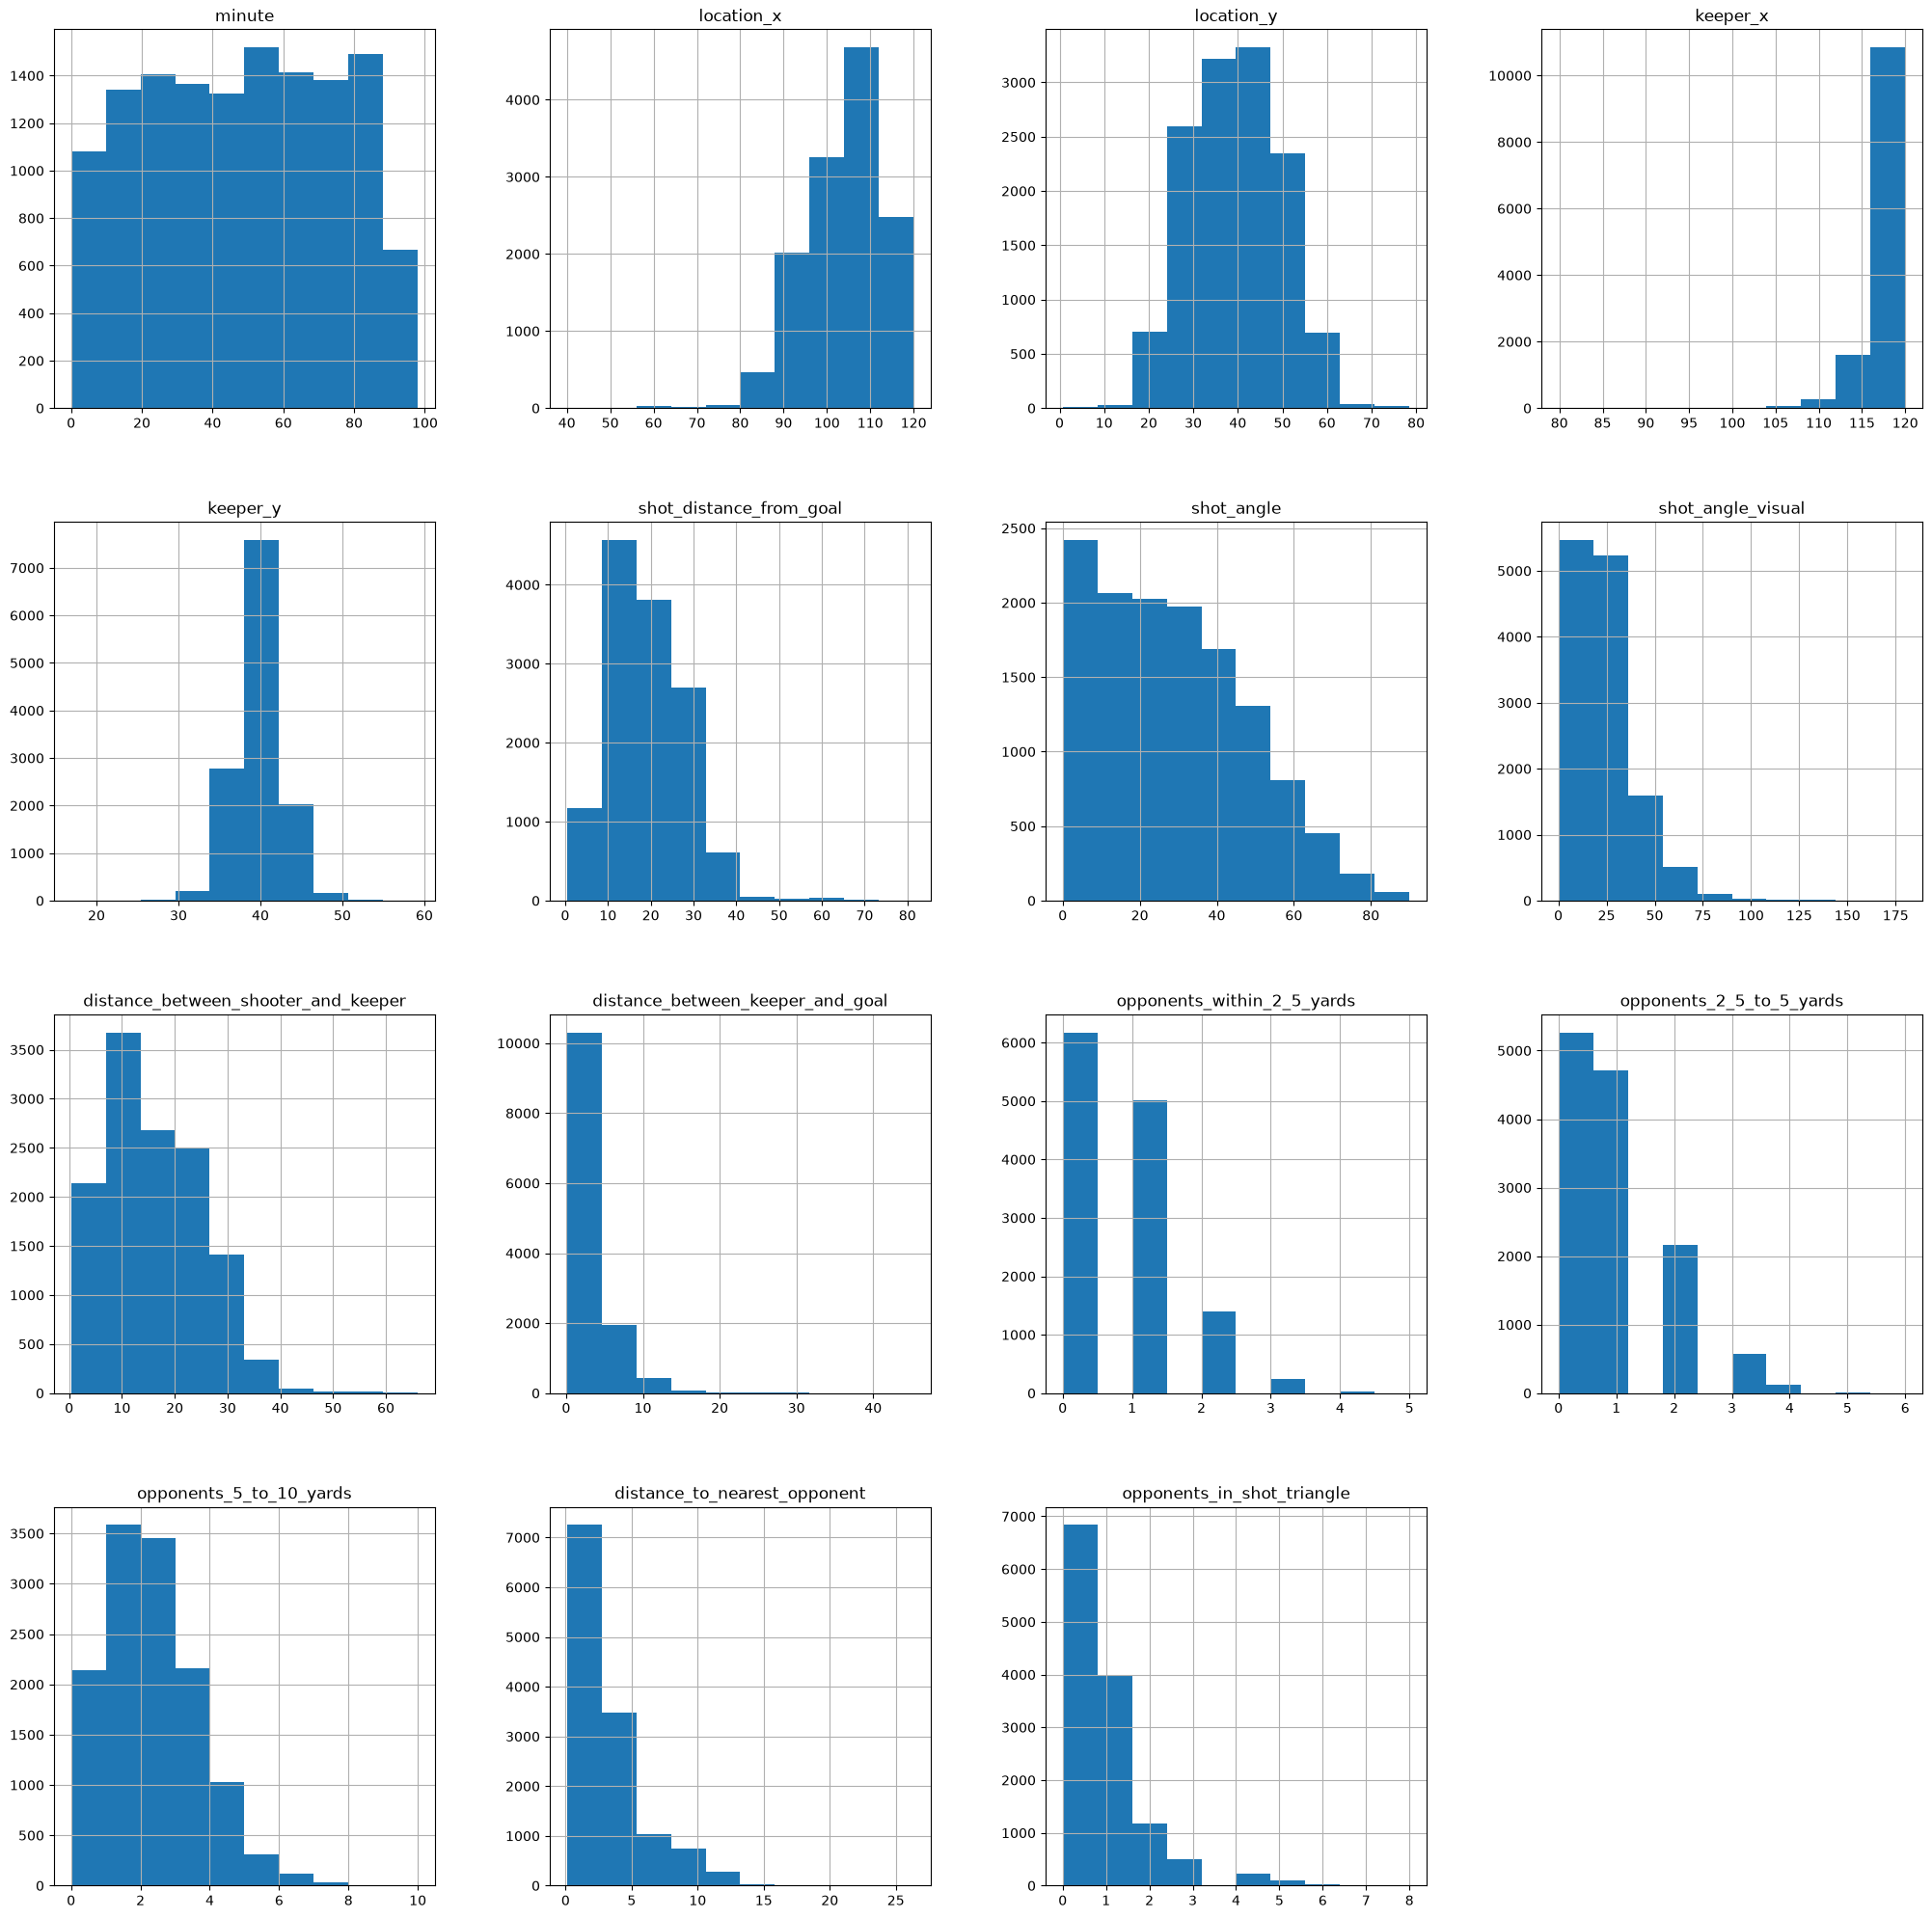

In [299]:
fig, ax = plt.subplots(1, 1 ,figsize=(25,25))
barcelona_shots[numeric_features].hist(ax=ax)

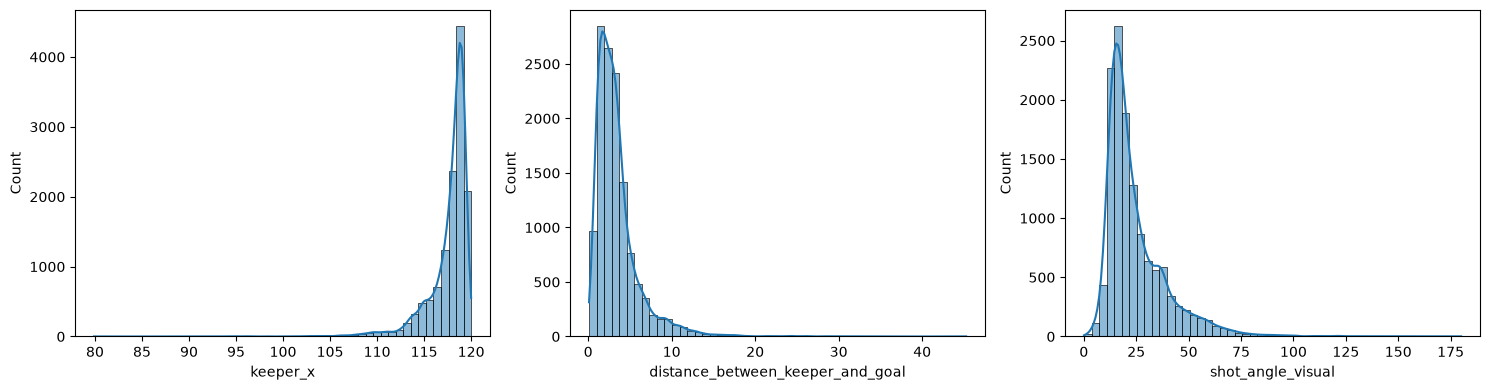

In [300]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

sbn.histplot(barcelona_shots["keeper_x"], bins=50, kde=True, ax=ax[0])
ax[0].set_xlabel("keeper_x")

sbn.histplot(barcelona_shots["distance_between_keeper_and_goal"], bins=50, kde=True, ax=ax[1])
ax[1].set_xlabel("distance_between_keeper_and_goal")

sbn.histplot(barcelona_shots["shot_angle_visual"], bins=50, kde=True, ax=ax[2])
ax[2].set_xlabel("shot_angle_visual")

plt.tight_layout()
plt.show()

### Histogrammer for `keeper_x`, `distance_between_keeper_and_goal` og `shot_angle_visual`

Histogrammene bekrefter det `skew()` viste:

- **`keeper_x`:** De fleste keepere står mellom 115 og 120, med toppen rundt 118–119. Fordelingen stuper ved 120, siden keeperen ikke kan stå bak mållinjen, og har en tynn hale mot venstre ned mot 80. Venstreskjevheten kommer altså av at verdiene presses mot en fysisk grense.
- **`distance_between_keeper_and_goal`:** Toppen ligger rundt 2 yards, og fordelingen faller raskt etter det. Halen går mot 45 yards, men er nesten usynlig over ca. 15. Featuren er i praksis `keeper_x` speilvendt.
- **`shot_angle_visual`:** Toppen ligger rundt 15–20 grader, med en lang hale mot høyre opp mot 180 grader.

I alle tre er halene så lave at de er vanskelige å se. Neste steg er å undersøke hvor mange rader som faktisk ligger der. Jeg velger terskler ut fra plottene og teller radene utenfor dem.

In [301]:
(barcelona_shots["distance_between_keeper_and_goal"] > 10).sum()

np.int64(412)

In [302]:
(barcelona_shots["keeper_x"] < 105).sum()

np.int64(48)

In [303]:
(barcelona_shots["shot_angle_visual"] > 90).sum()

np.int64(72)

**Hvor mange rader ligger i halene?** Jeg valgte terskler med øyemål fra plottene og telte radene utenfor dem:

| Feature | Terskel | Antall | Andel |
|---|---|---|---|
| `distance_between_keeper_and_goal` | over 10 yards | 412 | 3,2 % |
| `keeper_x` | under 105 | 48 | 0,4 % |
| `shot_angle_visual` | over 90 grader | 72 | 0,6 % |

Det er svært få rader som gir så høy skjevhet. Bare 48 av 12 834 rader trekker `keeper_x` ned til −3,5. Disse skuddene er ekte hendelser, for eksempel en keeper som står langt ute, så de skal ikke fjernes uten grunn. Om featurene bør transformeres, avgjør jeg ved å teste en pipeline med og uten `PowerTransformer`.

<Axes: xlabel='shot_distance_from_goal', ylabel='Count'>

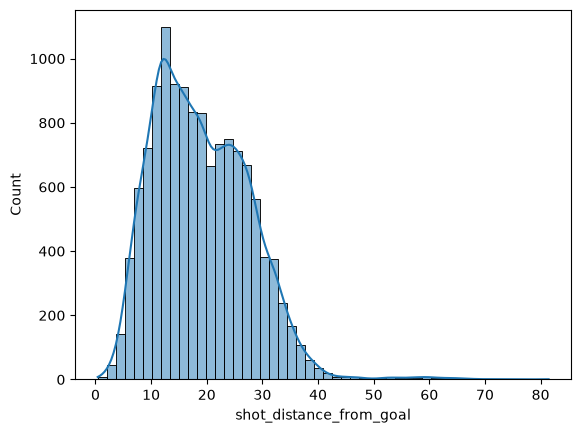

In [304]:
sbn.histplot(barcelona_shots["shot_distance_from_goal"], bins=50, kde=True)

In [305]:
barcelona_shots["shot_type"].value_counts()

shot_type
Open Play    11836
Free Kick      980
Penalty        168
Corner           1
Name: count, dtype: int64

### `shot_distance_from_goal`

Histogrammet viser at fordelingen ikke bare er skjev (0,83) med en hale mot 80 yards, men har **to topper**:

- **Rundt 12 yards.** Det er avstanden til straffemerket. Alle 168 straffer i datasettet ligger mellom 11,6 og 12,9 yards, og de samles i én søyle.
- **Rundt 22–26 yards.** Det er skudd utenfor sekstenmeteren, og her bidrar frisparkene (980 skudd, median 28,5 yards).

Formen er altså delvis en blanding av ulike skuddtyper: straffer, frispark og åpent spill. Skjevhetstallet alene viste ikke dette. Åpent spill alene har én bred topp rundt 10–14 yards med en skulder rundt 20–26 yards.

Dette er et godt argument for å beholde `shot_type` som feature, og det gir en idé til senere i EDA: et histogram delt på `shot_type` for å se at skuddtypene har ulike fordelinger.

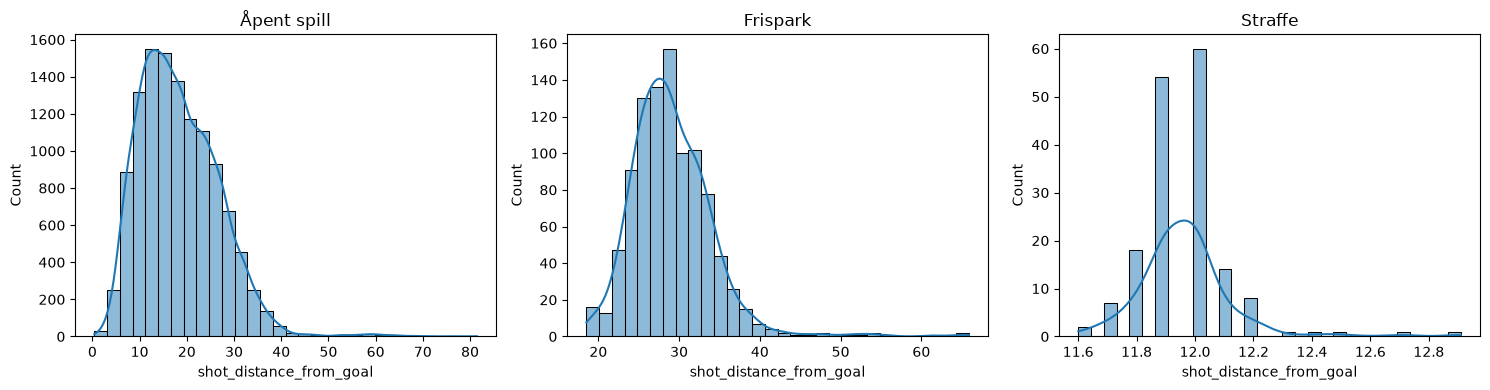

In [306]:
open_play = barcelona_shots[barcelona_shots["shot_type"] == "Open Play"]["shot_distance_from_goal"]
free_kick = barcelona_shots[barcelona_shots["shot_type"] == "Free Kick"]["shot_distance_from_goal"]
penalty = barcelona_shots[barcelona_shots["shot_type"] == "Penalty"]["shot_distance_from_goal"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

sbn.histplot(open_play, bins=30, kde=True, ax=ax[0])
ax[0].set_title("Åpent spill")
ax[0].set_xlabel("shot_distance_from_goal")

sbn.histplot(free_kick, bins=30, kde=True, ax=ax[1])
ax[1].set_title("Frispark")
ax[1].set_xlabel("shot_distance_from_goal")

sbn.histplot(penalty, bins=30, kde=True, ax=ax[2])
ax[2].set_title("Straffe")
ax[2].set_xlabel("shot_distance_from_goal")

plt.tight_layout()
plt.show()

### `shot_distance_from_goal` delt på skuddtype

Når avstanden deles etter skuddtype, blir de tre formene tydelige:

- **Åpent spill:** Én bred topp, og de fleste skuddene tas mellom ca. 12 og 20–22 yards fra mål, med en hale ut mot 80 yards.
- **Frispark:** Ligger høyere opp, med toppen rundt 28 yards. Frisparkene er med på å lage den andre toppen vi så i det samlede histogrammet.
- **Straffe:** Svært smal fordeling rundt 12 yards, siden alle straffer tas fra nesten samme punkt, med små forskjeller +-0.3

Det forklarer tvetoppen i det samlede histogrammet: den er en blanding av skuddtyper med ulike avstander.

**Neste idé:** Ta samme histogrammer, men del hver skuddtype videre etter om skuddet ble mål eller ikke. Da kan vi se om avstanden skiller mål fra ikke-mål innenfor hver skuddtype, for eksempel om målene i åpent spill kommer fra kortere avstand enn de andre skuddene.

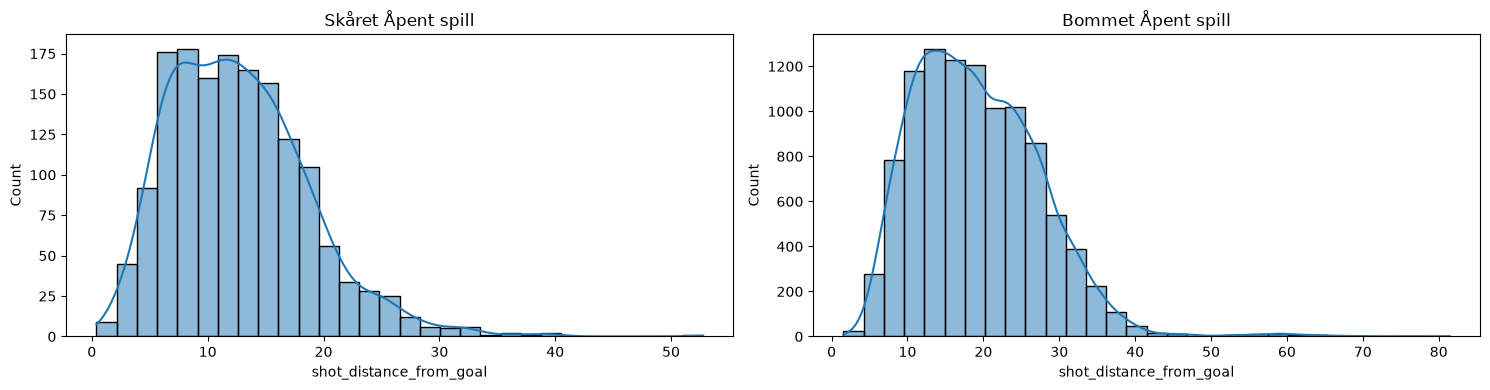

In [307]:
open_play_goal = barcelona_shots[(barcelona_shots["shot_type"] == "Open Play") & (barcelona_shots["shot_outcome_target"] == 1)]["shot_distance_from_goal"]
free_kick_goal = barcelona_shots[(barcelona_shots["shot_type"] == "Free Kick") & (barcelona_shots["shot_outcome_target"] == 1 )]["shot_distance_from_goal"]
penalty_goal = barcelona_shots[(barcelona_shots["shot_type"] == "Penalty") &(barcelona_shots["shot_outcome_target"] == 1)]["shot_distance_from_goal"]

open_play_not_goal = barcelona_shots[(barcelona_shots["shot_type"] == "Open Play") & (barcelona_shots["shot_outcome_target"] == 0)]["shot_distance_from_goal"]
free_kick_not_goal = barcelona_shots[(barcelona_shots["shot_type"] == "Free Kick") & (barcelona_shots["shot_outcome_target"] == 0 )]["shot_distance_from_goal"]
penalty_not_goal = barcelona_shots[(barcelona_shots["shot_type"] == "Penalty") &(barcelona_shots["shot_outcome_target"] == 0)]["shot_distance_from_goal"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))

sbn.histplot(open_play_goal, bins=30, kde=True, ax=ax[0])
ax[0].set_title("Skåret Åpent spill")
ax[0].set_xlabel("shot_distance_from_goal")

sbn.histplot(open_play_not_goal, bins=30, kde=True, ax=ax[1])
ax[1].set_title("Bommet Åpent spill")
ax[1].set_xlabel("shot_distance_from_goal")

plt.tight_layout()
plt.show()


### Åpent spill: avstand for mål og ikke-mål

De fleste målene i åpent spill kommer fra ca. 6–8 yards. Det blir litt færre rundt 10 yards, så stiger det igjen mellom 12 og 16, før det faller mot 18–20 yards. Etter ca. 20 yards er det få mål.

Skuddene som ikke ble mål har en bredere fordeling og tas oftere fra lengre avstand, og mange kommer fra 20–30 yards. Målene kommer altså fra kortere avstand enn de andre skuddene, men fordelingene overlapper mye. Y-aksene er ulike (langt flere skudd uten mål), så vi sammenligner formene, ikke høydene.

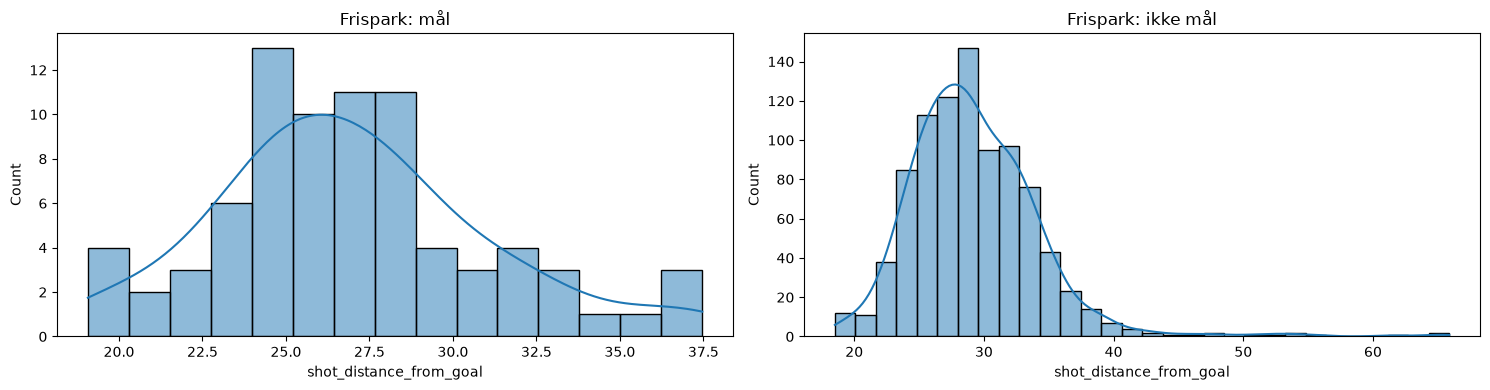

In [308]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))

sbn.histplot(free_kick_goal, bins=15, kde=True, ax=ax[0])
ax[0].set_title("Frispark: mål")
ax[0].set_xlabel("shot_distance_from_goal")

sbn.histplot(free_kick_not_goal, bins=30, kde=True, ax=ax[1])
ax[1].set_title("Frispark: ikke mål")
ax[1].set_xlabel("shot_distance_from_goal")

plt.tight_layout()
plt.show()

In [309]:
len(free_kick_goal)

79

In [310]:
len(free_kick_not_goal)

901

In [311]:

barcelona_shots["shot_type"].value_counts()

shot_type
Open Play    11836
Free Kick      980
Penalty        168
Corner           1
Name: count, dtype: int64

In [312]:
free_kick_not_goal.skew()

np.float64(1.8695995557357676)

### Frispark: avstand for mål og ikke-mål

Frisparkmålene (79 stykker) kommer fra ca. 19 til 37 yards, med flest rundt 24–29 yards. Ikke-målene har toppen rundt 27–30 yards, så de ligger litt lenger unna.

Ikke-målene er **sterkt høyreskjeve** (skjevhet 1,87): de fleste skuddene tas mellom ca. 22 og 38 yards, men noen få strekker seg ut mot 60–65 yards. Det er disse få skuddene som gir den høye skjevheten, mens selve toppen er omtrent symmetrisk. Det er den samme effekten vi så for de andre skjeve featurene.

Forskjellen mellom mål og ikke-mål er mye mindre enn i åpent spill. Begge fordelingene ligger i samme område, så avstand alene skiller dem dårlig for frispark. Det er også få mål, så histogrammet for målene er ujevnt, og vi bør ikke lese for mye ut av små svingninger. Y-aksene er ulike (79 mål mot 901 skudd), så vi sammenligner formene, ikke høydene.

Straffer tas fra samme punkt (ca. 12 yards), så avstanden varierer nesten ikke og sier lite om utfallet. Vi plotter dem derfor ikke mot mål og ikke-mål.

<Axes: xlabel='distance_to_nearest_opponent', ylabel='Count'>

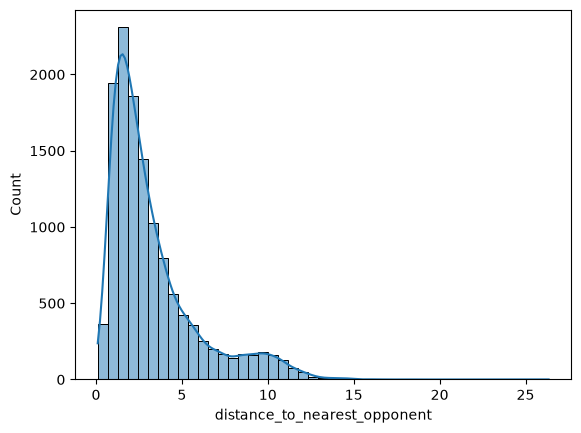

In [313]:
sbn.histplot(barcelona_shots["distance_to_nearest_opponent"], bins=45, kde=True)

### `distance_to_nearest_opponent`

Histogrammet viser at de fleste skudd tas med en motstander tett på: toppen ligger rundt 1,5–2 yards, og de fleste skuddene ligger mellom ca. 1 og 4 yards fra nærmeste motstander. Fordelingen er sterkt høyreskjev, med en hale ut mot 25 yards, men få skudd tas med mer enn 10 yards til nærmeste motstander.

Figuren viser alle skudd samlet, så den sier ikke noe om hva som skiller mål fra ikke-mål. Det ser vi på når vi deler dem opp.

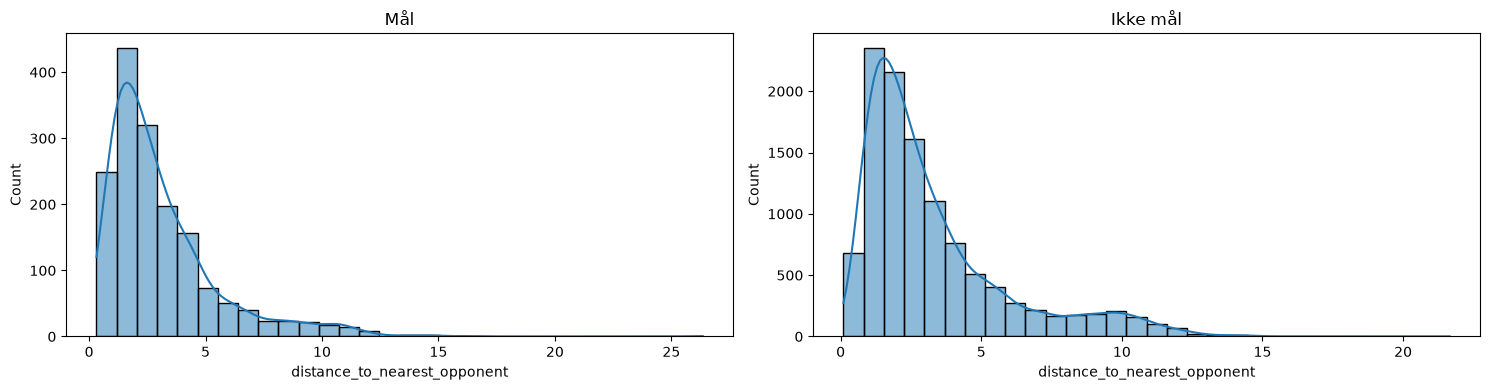

In [314]:
nearest_goal = barcelona_shots[barcelona_shots["shot_outcome_target"] == 1]["distance_to_nearest_opponent"]
nearest_not_goal = barcelona_shots[barcelona_shots["shot_outcome_target"] == 0]["distance_to_nearest_opponent"]

fig, ax = plt.subplots(1, 2, figsize=(15, 4))

sbn.histplot(nearest_goal, bins=30, kde=True, ax=ax[0])
ax[0].set_title("Mål")
ax[0].set_xlabel("distance_to_nearest_opponent")

sbn.histplot(nearest_not_goal, bins=30, kde=True, ax=ax[1])
ax[1].set_title("Ikke mål")
ax[1].set_xlabel("distance_to_nearest_opponent")

plt.tight_layout()
plt.show()

### `distance_to_nearest_opponent`: mål mot ikke-mål

De fleste målene kommer når nærmeste motstander står ca. 2 yards unna skytteren. Det betyr ikke at presset gjør det lettere å score. Ikke-målene har nesten samme form, med toppen på samme sted, så det er rett og slett der de fleste skuddene tas, uansett utfall. Y-aksene er ulike, så vi sammenligner formene, ikke høydene.

Fordi fordelingene er så like, ser featuren ut til å være svak alene: den sier ikke direkte om et skudd blir mål eller ikke. Den kan likevel tilføre noe sammen med de andre featurene, siden avstanden til nærmeste motstander også henger sammen med hvor på banen skuddet tas.

Den eneste tydelige forskjellen er at ikke-målene har en liten ekstra topp rundt 10 yards som målene nesten ikke har. Det kan ha med frispark å gjøre, men det har jeg ikke undersøkt.

In [315]:
barcelona_shots["team"].value_counts()

team
Barcelona                 8285
Real Madrid                406
Sevilla                    302
Atlético Madrid            295
Valencia                   266
Athletic Club              233
Real Sociedad              232
Villarreal                 220
Getafe                     208
Espanyol                   203
Real Betis                 194
Levante UD                 189
Celta Vigo                 174
RC Deportivo La Coruña     171
Osasuna                    139
Rayo Vallecano             136
Eibar                      132
Málaga                     119
Real Valladolid            114
Real Zaragoza              107
Mallorca                   106
Granada                     89
Leganés                     85
Racing Santander            81
Las Palmas                  67
Deportivo Alavés            66
Almería                     61
Girona                      44
Sporting Gijón              43
Recreativo Huelva           43
Cádiz                       23
Elche                       23
Rea

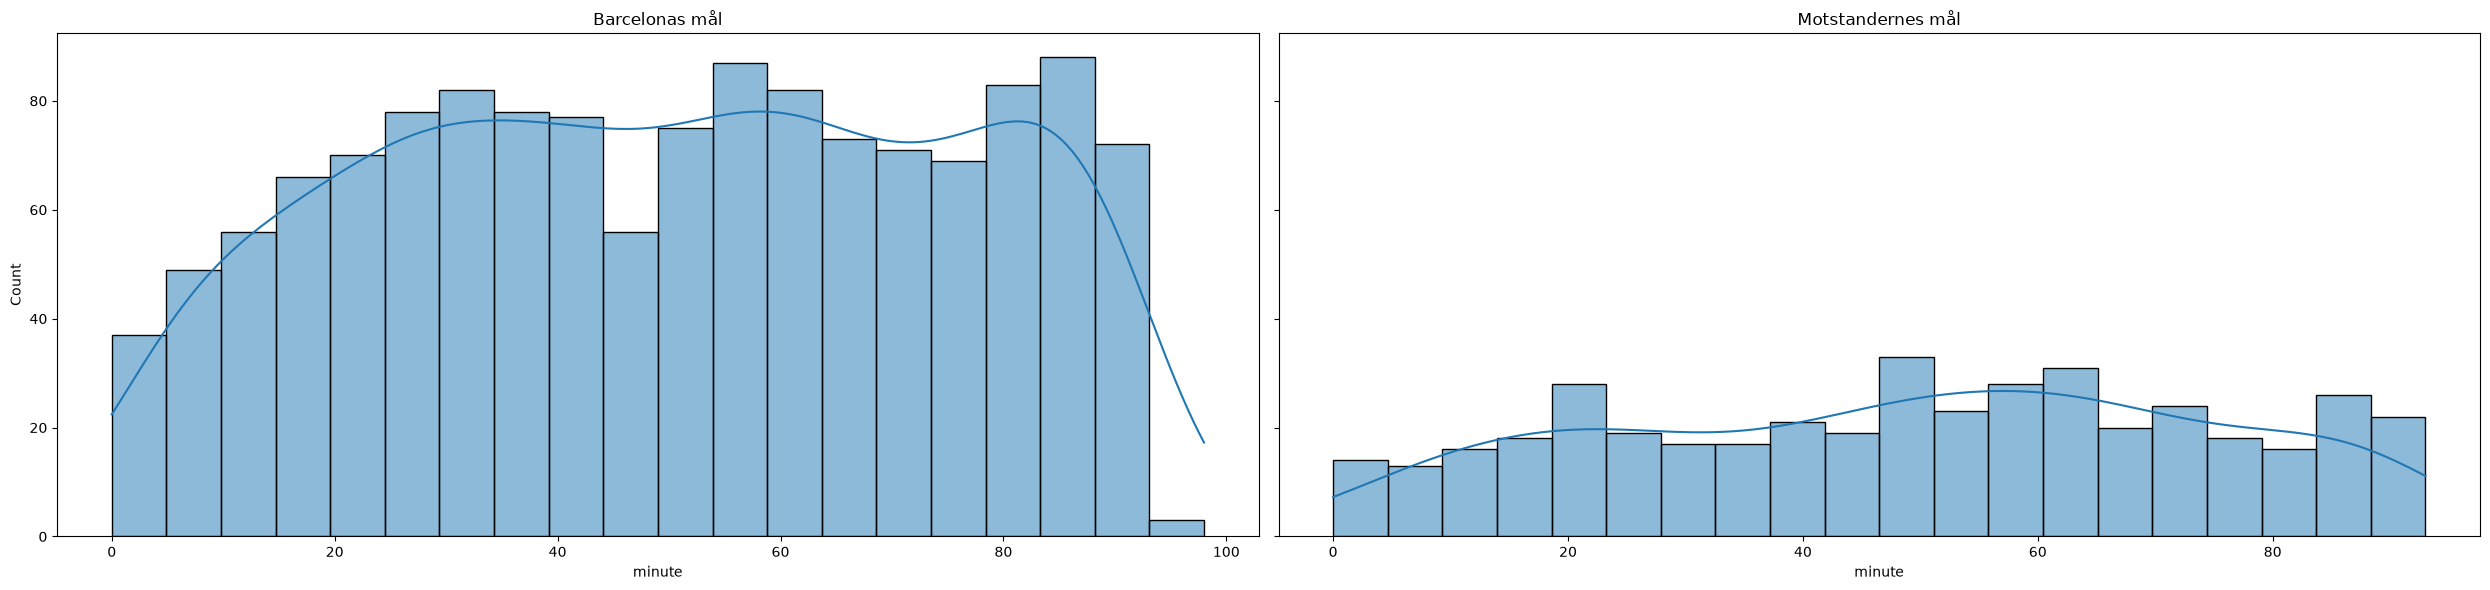

In [316]:
barca_minute = barcelona_shots[(barcelona_shots["team"] == "Barcelona") & (barcelona_shots["shot_outcome_target"]== 1)]["minute"]
others_minute = barcelona_shots[(barcelona_shots["team"] != "Barcelona") & (barcelona_shots["shot_outcome_target"]== 1)]["minute"]

fig, ax = plt.subplots(1, 2, figsize=(25, 6), sharey=True)

sbn.histplot(barca_minute, bins=20, kde=True, ax=ax[0])
ax[0].set_title("Barcelonas mål")
ax[0].set_xlabel("minute")

sbn.histplot(others_minute, bins=20, kde=True, ax=ax[1])
ax[1].set_title("Motstandernes mål")
ax[1].set_xlabel("minute")

plt.tight_layout()
plt.show()

### `minute`: når scores målene?

Figurene viser minuttene da Barcelona og motstanderne scoret. Barcelona har flest mål, og det vises tydelig siden figurene deler y-akse.

Fordelingen er ganske jevn gjennom hele kampen for "begge" lag. Det er litt færre mål de første minuttene, før det flater ut. Resten av svingningene er små og skyldes trolig tilfeldig variasjon. Den siste søylen er lav fordi det bare er noen få minutter overtid.

Dette er bare mål, så figurene viser ikke om *sjansen* for mål endrer seg gjennom kampen. For å vite det måtte vi sammenlignet med alle skuddene i samme minutter. Foreløpig ser `minute` ut til å være en svak feature, selv om jeg egentlig hadde tanke før om at når skudden blir tatt har kanskje noe å si, for skudd som kommer senere i tillegg til hvis laget ligger bra/dårlig ann så vil det påvirke om det blir mål eller ikke 

### Idé: spilleforløp (stillingen før skuddet)

Målet er å lage en modell som predikerer om et skudd blir mål, basert på det vi vet i det skuddet blir tatt: skytterens posisjon, keeperens posisjon, antall motstandere rundt skytteren, avstand til mål og keeper, to ulike vinkler mot målet og når i kampen skuddet kom.

En mulig tilleggsfeature er **stillingen før skuddet**. Med fotballkunnskap forventer jeg at det kan ha noe å si, for eksempel at lag som ligger under presser mer eller tar skudd under annen risiko enn lag som leder. Dette er en hypotese, og jeg vet ikke på forhånd hvor mye den hjelper.

Siden datasettet inneholder alle skudd i hver kamp (`match_id`), kan stillingen regnes ut ved å telle mål som kom *før* hvert skudd. Det er ikke leakage, så lenge:
- bare tidligere mål telles, aldri skuddet selv eller senere skudd
- skuddene sorteres riktig etter kamp, periode, minutt og sekund

Selvmål er ikke skudd og blir ikke telt, så stillingen kan være litt feil i noen kamper. Jeg tester featuren som en egen gruppe (`game_state_features`) i ablasjonsstudien, og sammenligner med og uten den.

Datasettet deles på kamper (`match_id`), ikke på tilfeldige skudd. Skudd fra samme kamp ligner hverandre, og ville ellers havnet både i trenings- og testdata.

### Hvorfor vi splitter på kamper, ikke på sesonger

I et tidligere prosjekt, hvor vi predikerte kampresultater, delte vi dataene på sesong. Featurene der bygde på historikk, og testdataene måtte komme etter treningsdataene for å unngå informasjon fra fremtiden.

Her er problemet et annet. Hvert skudd beskrives av situasjonen i det øyeblikket det tas (posisjon, keeper, motstandere, vinkler og tidspunkt), og ingen features bruker data fra andre kamper. Sesong har lite å si for om et skudd blir mål, og vi bruker den ikke som feature, så det er ikke et tidsserieproblem. Det som er avhengig av hverandre, er skudd fra samme kamp, som ligner hverandre og ikke må havne både i trenings- og testdata. Derfor splitter vi på kamper (`match_id`) med `StratifiedGroupKFold`, og bruker det også i nested cross-validation.

Som en mulig ekstra sjekk kunne vi trent på eldre sesonger og testet på nyere, for å se om modellen holder seg stabil over tid. Det gjør vi ikke i hovedanalysen.

In [317]:
correlation = barcelona_shots[numeric_features].corr()

correlation.style.background_gradient(cmap='coolwarm')

,minute,location_x,location_y,keeper_x,keeper_y,shot_distance_from_goal,shot_angle,shot_angle_visual,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle
minute,1.000000,0.011442,0.014537,-0.029107,0.004343,-0.027401,-0.030344,0.012013,-0.030004,0.020838,-0.007511,-0.000346,0.005725,0.010503,0.005264
location_x,0.011442,1.000000,-0.026784,0.039040,-0.021745,-0.936985,0.484626,0.552238,-0.918633,0.150607,0.314306,0.131719,-0.000137,-0.418783,-0.337751
location_y,0.014537,-0.026784,1.000000,-0.025142,0.679842,0.010150,-0.046551,0.019795,0.005373,0.021139,-0.013242,-0.012596,0.002818,0.021792,-0.000676
keeper_x,-0.029107,0.039040,-0.025142,1.000000,0.040278,-0.015129,0.058935,-0.007251,0.228686,-0.897913,0.048498,0.040096,0.135308,0.044835,0.227793
keeper_y,0.004343,-0.021745,0.679842,0.040278,1.000000,0.017694,-0.020700,-0.004369,0.024640,-0.041624,-0.018462,-0.012266,0.021891,0.027054,0.012762
shot_distance_from_goal,-0.027401,-0.936985,0.010150,-0.015129,0.017694,1.000000,-0.186872,-0.720522,0.955477,-0.089005,-0.349331,-0.176686,-0.076626,0.441549,0.280447
shot_angle,-0.030344,0.484626,-0.046551,0.058935,-0.020700,-0.186872,1.000000,-0.203233,-0.263649,0.234454,0.010827,-0.082622,-0.180715,-0.093949,-0.257829
shot_angle_visual,0.012013,0.552238,0.019795,-0.007251,-0.004369,-0.720522,-0.203233,1.000000,-0.630561,-0.023445,0.279307,0.164022,0.109794,-0.292362,-0.162920
distance_between_shooter_and_keeper,-0.030004,-0.918633,0.005373,0.228686,0.024640,0.955477,-0.263649,-0.630561,1.000000,-0.344647,-0.324549,-0.152588,-0.019748,0.448656,0.354485
distance_between_keeper_and_goal,0.020838,0.150607,0.021139,-0.897913,-0.041624,-0.089005,0.234454,-0.023445,-0.344647,1.000000,-0.039689,-0.073981,-0.179527,-0.071088,-0.278353


In [318]:
corr_columns = numeric_features + binary_features + [target]
correlation = barcelona_shots[corr_columns].corr()

correlation.style.background_gradient(cmap="coolwarm", axis=None, vmin=-1, vmax=1).format("{:.2f}")

,minute,location_x,location_y,keeper_x,keeper_y,shot_distance_from_goal,shot_angle,shot_angle_visual,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle,under_pressure,shot_follows_dribble,shot_aerial_won,shot_first_time,shot_one_on_one,shot_open_goal,shot_outcome_target
minute,1.00,0.01,0.01,-0.03,0.00,-0.03,-0.03,0.01,-0.03,0.02,-0.01,-0.00,0.01,0.01,0.01,-0.03,0.01,-0.01,-0.03,0.01,-0.00,0.02
location_x,0.01,1.00,-0.03,0.04,-0.02,-0.94,0.48,0.55,-0.92,0.15,0.31,0.13,-0.00,-0.42,-0.34,0.15,-0.03,0.21,0.15,0.24,0.16,0.22
location_y,0.01,-0.03,1.00,-0.03,0.68,0.01,-0.05,0.02,0.01,0.02,-0.01,-0.01,0.00,0.02,-0.00,-0.02,0.00,0.01,0.03,-0.01,0.01,0.01
keeper_x,-0.03,0.04,-0.03,1.00,0.04,-0.02,0.06,-0.01,0.23,-0.90,0.05,0.04,0.14,0.04,0.23,0.04,0.02,0.13,-0.05,-0.18,-0.09,-0.19
keeper_y,0.00,-0.02,0.68,0.04,1.00,0.02,-0.02,-0.00,0.02,-0.04,-0.02,-0.01,0.02,0.03,0.01,-0.00,-0.00,0.01,0.01,-0.02,-0.01,-0.00
shot_distance_from_goal,-0.03,-0.94,0.01,-0.02,0.02,1.00,-0.19,-0.72,0.96,-0.09,-0.35,-0.18,-0.08,0.44,0.28,-0.16,0.02,-0.26,-0.17,-0.20,-0.18,-0.27
shot_angle,-0.03,0.48,-0.05,0.06,-0.02,-0.19,1.00,-0.20,-0.26,0.23,0.01,-0.08,-0.18,-0.09,-0.26,0.01,-0.02,-0.06,0.02,0.20,0.07,-0.05
shot_angle_visual,0.01,0.55,0.02,-0.01,-0.00,-0.72,-0.20,1.00,-0.63,-0.02,0.28,0.16,0.11,-0.29,-0.16,0.13,-0.01,0.28,0.15,0.05,0.39,0.32
distance_between_shooter_and_keeper,-0.03,-0.92,0.01,0.23,0.02,0.96,-0.26,-0.63,1.00,-0.34,-0.32,-0.15,-0.02,0.45,0.35,-0.15,0.03,-0.21,-0.18,-0.26,-0.13,-0.27
distance_between_keeper_and_goal,0.02,0.15,0.02,-0.90,-0.04,-0.09,0.23,-0.02,-0.34,1.00,-0.04,-0.07,-0.18,-0.07,-0.28,-0.04,-0.02,-0.15,0.09,0.25,0.10,0.19


In [319]:
correlation = barcelona_shots[numeric_features + binary_features].corr().abs()
pairs = correlation.unstack().sort_values(ascending=False)
pairs[(pairs > 0.5) & (pairs < 1)]

shot_distance_from_goal              distance_between_shooter_and_keeper    0.955477
distance_between_shooter_and_keeper  shot_distance_from_goal                0.955477
shot_distance_from_goal              location_x                             0.936985
location_x                           shot_distance_from_goal                0.936985
                                     distance_between_shooter_and_keeper    0.918633
distance_between_shooter_and_keeper  location_x                             0.918633
distance_between_keeper_and_goal     keeper_x                               0.897913
keeper_x                             distance_between_keeper_and_goal       0.897913
shot_angle_visual                    shot_distance_from_goal                0.720522
shot_distance_from_goal              shot_angle_visual                      0.720522
location_y                           keeper_y                               0.679842
keeper_y                             location_y                  

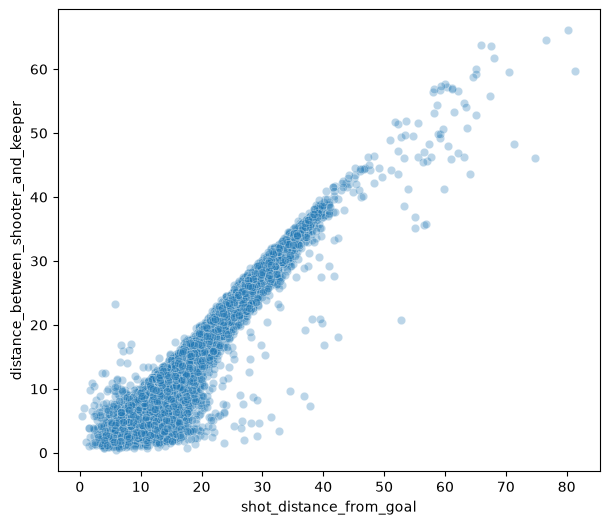

In [320]:
plt.figure(figsize=(7, 6))
sbn.scatterplot(data=barcelona_shots, x="shot_distance_from_goal", y="distance_between_shooter_and_keeper", alpha=0.3)
plt.show()

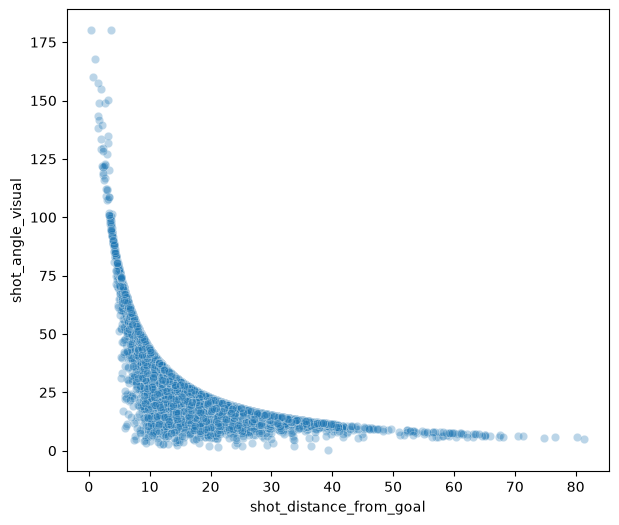

In [321]:
plt.figure(figsize=(7, 6))
sbn.scatterplot(data=barcelona_shots, x="shot_distance_from_goal", y="shot_angle_visual", alpha=0.3)
plt.show()

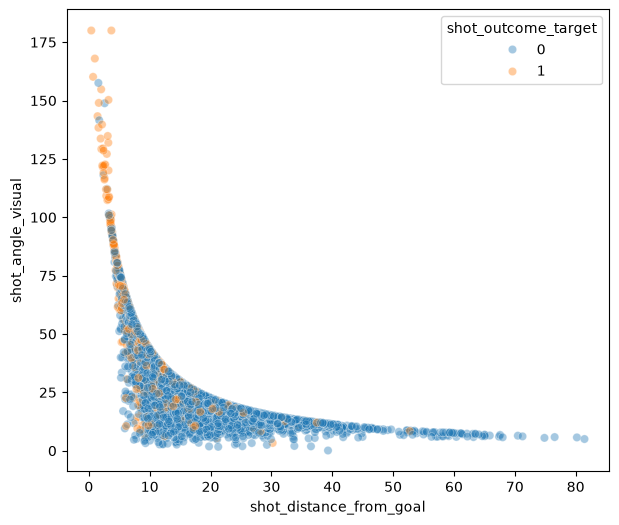

In [322]:
plt.figure(figsize=(7, 6))
sbn.scatterplot(data=barcelona_shots, x="shot_distance_from_goal", y="shot_angle_visual", hue=target, alpha=0.4)
plt.show()

#### Vinkel mot avstand

Plottet av `shot_distance_from_goal` mot `shot_angle_visual` viser en kurve, ikke en rett linje: vinkelen faller raskt de første yardene fra mål og flater ut etter ca. 20–30 yards. Kurven danner også en øvre grense, fordi vinkelen for en gitt avstand er størst når skuddet tas rett foran mål, og mindre fra sidene. De fleste målene ligger nær mål med stor vinkel, mens nesten alle skudd lenger ut er ikke-mål.

Forholdet er ikke-lineært, så korrelasjonen på 0,72 undervurderer hvor tett de to featurene henger sammen. Dette støtter at power transformation (eller PCA) kan hjelpe de lineære modellene, mens trebaserte modeller håndterer kurven uansett. Jeg tester det i pipeline.

### Korrelasjon mellom features

Jeg har sett på hvilke features som henger sammen, ved å liste alle par med absolutt korrelasjon mellom 0,5 og 1. Her er de tydeligste gruppene:

- **Nærhet til mål:** `shot_distance_from_goal`, `location_x`, `distance_between_shooter_and_keeper` og `shot_angle_visual`. Parene i denne gruppen har korrelasjon fra 0,55 til 0,96.
- **Keeper ut fra mål:** `keeper_x` og `distance_between_keeper_and_goal` (0,90).
- **Sidelengs posisjon:** `location_y` og `keeper_y` (0,68). Keeperen følger ballen sidelengs.
- **Press:** `opponents_within_2_5_yards` og `distance_to_nearest_opponent` (0,62).
- **Binære:** `under_pressure` og `shot_aerial_won` (0,57).

Mye av dette er ikke tilfeldig. Keeperen står som oftest nær mållinjen, så avstanden skytter–keeper blir nesten lik avstanden skytter–mål. Pressfeaturene måler det samme på to ulike måter.

**Hypotese:** Features som korrelerer sterkt gir nesten den samme informasjonen. De kan slås sammen til færre komponenter med PCA uten at vi mister mye, og modellene får da mindre overlappende input.

**Konsekvens for modellene:**
- Trebaserte modeller (random forest, boosting) påvirkes lite av korrelerte features.
- Logistisk regresjon og ANN påvirkes mer, så PCA er mest relevant for dem.

Dette gjør at PCA passer godt inn i delen om avansert prosessering. Senere lager jeg pipelines **med og uten PCA** og sammenligner dem med kryssvalidering, for å se om hypotesen min stemmer. PCA brukes bare på de numeriske featurene, etter skalering og inne i pipelinen, slik at vi ikke får lekkasje fra testdata.

In [323]:
cols = numeric_features + binary_features + [target]
barcelona_shots[cols].corr()[target].drop(target).sort_values()

distance_between_shooter_and_keeper   -0.272387
shot_distance_from_goal               -0.267798
keeper_x                              -0.191597
opponents_in_shot_triangle            -0.108596
shot_aerial_won                       -0.051267
shot_angle                            -0.045122
under_pressure                        -0.042041
distance_to_nearest_opponent          -0.022925
shot_follows_dribble                  -0.012597
opponents_within_2_5_yards            -0.012573
opponents_5_to_10_yards               -0.006076
keeper_y                              -0.003256
opponents_2_5_to_5_yards               0.008893
location_y                             0.014921
minute                                 0.024791
shot_one_on_one                        0.092256
shot_first_time                        0.095155
distance_between_keeper_and_goal       0.187086
location_x                             0.218472
shot_open_goal                         0.234155
shot_angle_visual                      0

### Korrelasjon mot target

Jeg sjekket korrelasjonen mellom hver feature og `shot_outcome_target`. Alle verdiene er lave. Den sterkeste er `shot_angle_visual` (0,32), etterfulgt av `distance_between_shooter_and_keeper` (−0,27) og `shot_distance_from_goal` (−0,27). Så kommer `shot_open_goal` (0,23), `location_x` (0,22), `keeper_x` (−0,19) og `distance_between_keeper_and_goal` (0,19).

Dette er ikke overraskende, av tre grunner:
- Pearson måler bare lineære sammenhenger, mens målsjansen ikke endrer seg lineært med avstand eller vinkel.
- Targeten er sjelden (13,7 % mål), og det gjør høye korrelasjoner vanskelige.
- Ingen feature har en urimelig høy korrelasjon, så det er ingen tegn til lekkasje.

Det er verdt å merke seg at `shot_angle_visual` (laget fra trekanten mot målet) korrelerer tydelig sterkere med mål enn `shot_angle` (vinkel fra midten, −0,05). Det støtter valget om å lage featuren selv. `opponents_in_shot_triangle` (−0,11) er også med blant de sterkeste, mens nærmeste motstander alene er svak (−0,02), slik vi så i histogrammene.

Lave korrelasjoner betyr ikke at featurene er ubrukelige. Modellene kan finne ikke-lineære sammenhenger og samspill mellom features, og det er der treningen skal vise verdien. Neste steg er å se på målandel per kategori og per intervall, som er mer informativt enn korrelasjon.

In [324]:
barcelona_shots.groupby("shot_body_part")[target].agg(["count", "mean"])

,count,mean
shot_body_part,,
Head,1625,0.107692
Left Foot,4919,0.147388
Other,33,0.303030
Right Foot,6408,0.134988


In [325]:
barcelona_shots.groupby("shot_technique")[target].agg(["count", "mean"])

,count,mean
shot_technique,,
Backheel,35,0.114286
Diving Header,50,0.240000
Half Volley,1275,0.113725
Lob,234,0.333333
Normal,10532,0.133973
Overhead Kick,83,0.120482
Volley,776,0.148196


In [326]:
barcelona_shots.groupby("shot_type")[target].agg(["count", "mean"])

,count,mean
shot_type,,
Corner,1,0.000000
Free Kick,980,0.080612
Open Play,11836,0.131970
Penalty,168,0.797619


In [327]:
barca_only = barcelona_shots[barcelona_shots["team"] == "Barcelona"]
barca_only.groupby("shot_type")[target].agg(["count", "mean"])

,count,mean
shot_type,,
Corner,1,0.000000
Free Kick,735,0.088435
Open Play,7433,0.160770
Penalty,116,0.793103


In [328]:
barcelona_shots.groupby("position")[target].agg(["count", "mean"])

,count,mean
position,,
Center Attacking Midfield,509,0.133595
Center Back,41,0.121951
Center Defensive Midfield,274,0.076642
Center Forward,2631,0.191562
Center Midfield,1,0.000000
Goalkeeper,1,0.000000
Left Attacking Midfield,20,0.150000
Left Back,378,0.058201
Left Center Back,328,0.106707


### Kategoriske features

Jeg har sett på antall skudd og målandel per kategori for `shot_body_part`, `shot_technique`, `shot_type` og `position`. Totalt er målandelen 13,7 %.

- **`shot_body_part`:** de fleste skuddene er med høyre fot (6408) eller venstre fot (4919), med lik målandel (13,5 % og 14,7 %). Hodestøt har lavere målandel (10,8 %).
- **`shot_technique`:** nesten alle skudd er "Normal" (10 532, 13,4 %). "Lob" skiller seg ut med 33,3 % mål på 234 skudd.
- **`shot_type`:** straffer scorer nesten alltid (79,8 %), frispark sjelden (8,1 %), og åpent spill ligger på 13,2 %. Mønsteret er det samme når jeg ser på Barcelona alene.
- **`position`:** angrepsspillere har høyest målandel (Center Forward 19,2 %), mens backer og defensive midtbanespillere ligger lavest (rundt 6–8 %).

Alle fire featurene har noen få store kategorier og flere veldig små (for eksempel "Other" med 33 skudd, "Goalkeeper" med 1 og "Corner" med 1). Målandelen i de små kategoriene er for usikker til å tolke, og de kan gi støy i modellene.

Siden kategoriene ikke har noen naturlig rekkefølge, sammenligner jeg One-Hot-Encoding og Label-/Ordinal-Encoding i pipeline. One-Hot gir flere kolonner (spesielt for `position`, med 24 verdier), mens Label-Encoding gir én kolonne, men tallene kan se ut som en rangering. Jeg tester begge med kryssvalidering, senere

In [329]:
barcelona_shots.groupby("under_pressure")[target].agg(["count", "mean"])

,count,mean
under_pressure,,
0,10877,0.143054
1,2108,0.103890


In [330]:
barcelona_shots.groupby("shot_follows_dribble")[target].agg(["count", "mean"])

,count,mean
shot_follows_dribble,,
0,12972,0.136833
1,13,0.000000


In [331]:
barcelona_shots.groupby("shot_first_time")[target].agg(["count", "mean"])

,count,mean
shot_first_time,,
0,8990,0.114905
1,3995,0.185732


In [332]:
barcelona_shots.groupby("shot_aerial_won")[target].agg(["count", "mean"])

,count,mean
shot_aerial_won,,
0,12227,0.141081
1,758,0.065963


In [333]:
barcelona_shots.groupby("shot_one_on_one")[target].agg(["count", "mean"])

,count,mean
shot_one_on_one,,
0,12051,0.127873
1,934,0.250535


In [334]:
barcelona_shots.groupby("shot_open_goal")[target].agg(["count", "mean"])

,count,mean
shot_open_goal,,
0,12817,0.127487
1,168,0.839286


### Binære features

For hver binær feature har jeg sett på antall skudd og målandel når featuren er 0 og 1.

- `shot_open_goal` er sterkest: 83,9 % av de 168 skuddene med åpent mål ble mål, mot 12,7 % ellers.
- `shot_one_on_one` gir 25,1 % mål (934 skudd) mot 12,8 %, og `shot_first_time` gir 18,6 % mål (3995 skudd) mot 11,5 %.
- `shot_aerial_won` (6,6 %, 758 skudd) og `under_pressure` (10,4 %, 2108 skudd) gir lavere målandel enn når featuren er 0 (14,1 % og 14,3 %).
- `shot_follows_dribble` har bare 13 skudd, ingen av dem mål, så den gir nesten ingen informasjon.

Flere av disse har klart ulik målandel mellom 0 og 1, selv om korrelasjonen mot targeten var lav. Det støtter at de kan hjelpe modellene, spesielt i kombinasjon med andre features. De sjeldne binære featurene (som `shot_open_goal` og `shot_follows_dribble`) har få 1-ere, så resultatene deres er mer usikre.

In [335]:
pd.crosstab(barcelona_shots["shot_type"], barcelona_shots["shot_open_goal"])

shot_open_goal,0,1
shot_type,,
Corner,1,0
Free Kick,980,0
Open Play,11668,168
Penalty,168,0


`shot_open_goal` forekommer bare i åpent spill (168 skudd), aldri ved straffer eller frispark. Den er derfor ikke det samme som `shot_type`, og gir ny informasjon.

<Axes: xlabel='shot_outcome_target', ylabel='shot_distance_from_goal'>

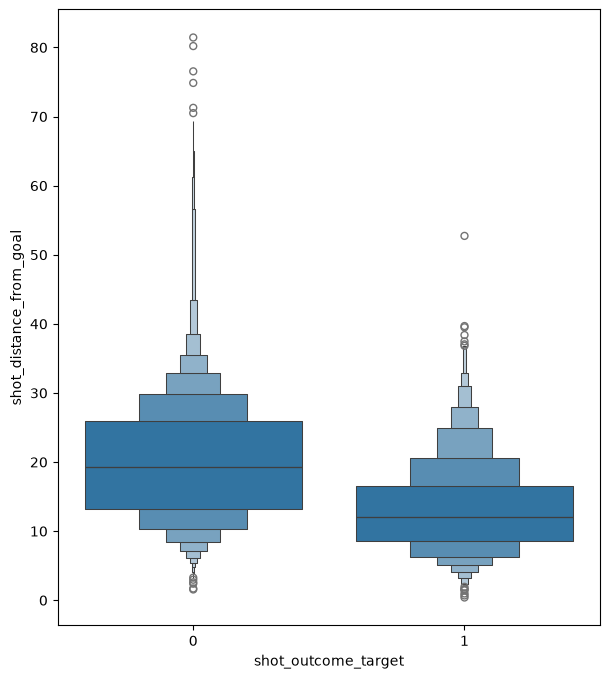

In [336]:
plt.figure(figsize=(7,8))
sbn.boxenplot(x=barcelona_shots["shot_outcome_target"], y=barcelona_shots["shot_distance_from_goal"])

#### Boxplot: avstand for mål og ikke mål

Boxplottet av `shot_distance_from_goal` delt på mål og ikke mål viser at mål typisk er tatt fra kortere avstand. Medianen er lavere for mål enn for ikke mål, og hele boksen ligger lavere. Ikke-målene har en mye lengre hale mot høy avstand, med skudd helt opp mot 80 yards.

Plottet viser også outliers tydelig. Blant målene ligger ett skudd rundt 55 yards fra mål, langt utenfor resten. Det ser ut som et ekte, uvanlig skudd og ikke en feil, men det har jeg ikke sjekket ennå. Jeg vil se på det på en fotballbane i neste del av EDA, der jeg også kan se hvor keeperen sto.

Outliers i halen er knyttet til skjevheten vi så tidligere, og de brukes i alternativet uten IQR-outliers som jeg sammenligner senere i pipeline.

In [337]:
long_goal= barcelona_shots[(barcelona_shots[target] == 1) & (barcelona_shots["shot_distance_from_goal"] > 50)]
long_goal

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle,shot_outcome_target
10215,69221,Barcelona,Pedro Eliezer Rodríguez Ledesma,3958.0,68,7,2,Left Wing,"[69.0, 53.4]",2.869583,Regular Play,0,0,Left Foot,0,"[120.0, 36.8, 1.2]",1,"[{'location': ['87.3', '43.5'], 'player': {'id...",0,0,0.039512,Normal,Open Play,Goal,2010-04-14,2009/2010,69.0,53.4,52.731016,14.721441,8.395239,87.3,43.5,20.806249,32.886775,0.0,0.0,0.0,11.04355,0.0,1


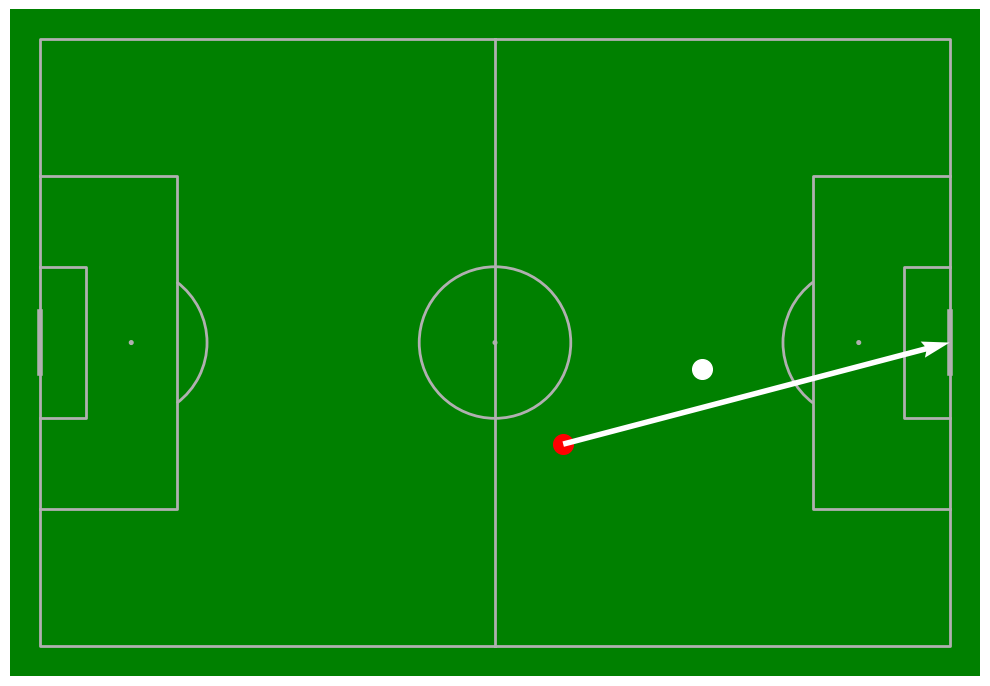

In [338]:
pitch = Pitch(pitch_type='statsbomb', pitch_color="green")
fig, ax = pitch.draw(figsize=(10,7))
pitch.scatter(long_goal["location_x"], long_goal["location_y"], ax=ax, s=200, color="red")
pitch.scatter(long_goal["keeper_x"], long_goal["keeper_y"], ax=ax, s=200, color="white")
pitch.arrows(long_goal["location_x"], long_goal["location_y"], 120, 40, ax=ax, color="white", lw=4)

#### Outlier på bane: det lengste målet

Det lengste målet er et skudd fra ca. 53 yards, tatt nær midtstreken. Jeg plottet det på en bane sammen med keeperposisjonen. Keeperen sto langt ute, godt utenfor 16-meteren, og det forklarer hvorfor skuddet ble mål. Skuddet er altså ekte og ikke en feil i dataene.

Det viser også at keeperfeaturene (`keeper_x`, `distance_between_keeper_and_goal`) fanger en reell situasjon. Jeg beholder skuddet i hoveddatasettet. Det fjernes bare i alternativet uten IQR-outliers, som jeg sammenligner i pipeline.

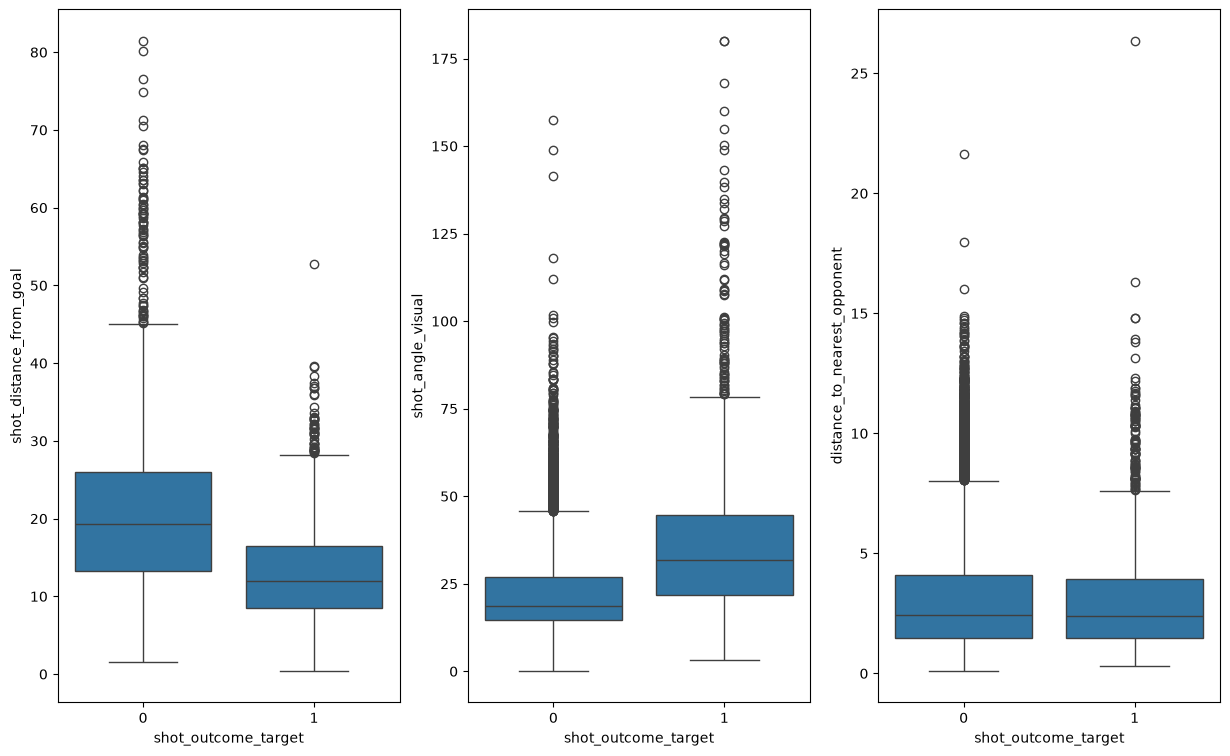

In [339]:
fig, ax = plt.subplots(1, 3, figsize=(15, 9))
sbn.boxplot(data=barcelona_shots, x=target, y="shot_distance_from_goal", ax=ax[0])
sbn.boxplot(data=barcelona_shots, x=target, y="shot_angle_visual", ax=ax[1])
sbn.boxplot(data=barcelona_shots, x=target, y="distance_to_nearest_opponent", ax=ax[2])
plt.show()

In [340]:
difficult_angle= barcelona_shots[(barcelona_shots["shot_angle_visual"] > 175) & (barcelona_shots[target] == 1)].head(1)
difficult_angle

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle,shot_outcome_target
4238,265952,Sporting Gijón,Carlos Castro García,24173.0,20,55,1,Center Forward,"[120.0, 39.6]",0.194749,From Throw In,0,0,Right Foot,0,"[120.0, 40.1, 0.9]",1,"[{'location': ['120.0', '23.0'], 'player': {'i...",0,1,0.941989,Normal,Open Play,Goal,2017-03-01,2016/2017,120.0,39.6,0.4,90.0,180.0,115.8,35.6,5.8,6.082763,0.0,1.0,2.0,3.712142,0.0,1


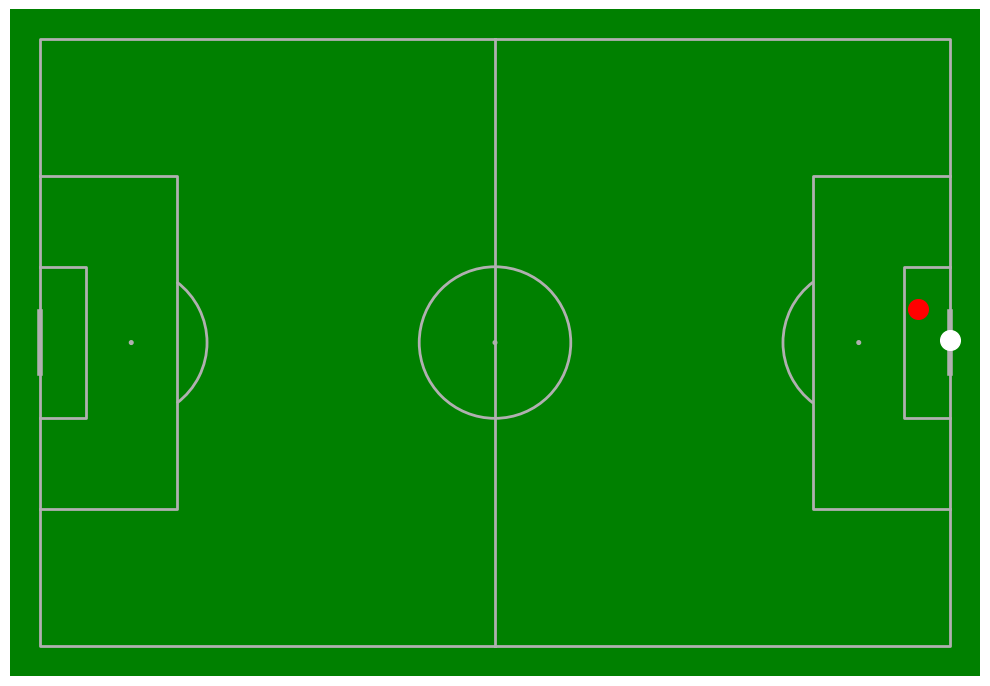

In [341]:
pitch_2= Pitch(pitch_type="statsbomb", pitch_color="green")
fig, ax = pitch_2.draw(figsize=(10,7))
pitch_2.scatter(difficult_angle["location_x"], difficult_angle["location_y"], ax=ax, s=200, color="white" )
pitch_2.scatter(difficult_angle["keeper_x"], difficult_angle["keeper_y"], ax=ax, s=200, color="red")

#### Outlier på bane: skudd med størst vinkel

Boxplottet av `shot_angle_visual` viser enkelte skudd med ekstremt stor vinkel. Det er to mål med vinkel over 175 grader, og jeg plottet det største på banen. Skytteren står på mållinjen omtrent midt mellom stolpene, og keeperen står noen få yards foran mållinjen. Når skytteren står så nær og så sentralt, åpner synsvinkelen mot stolpene seg til nesten 180 grader.

Dette er et geometrisk ekstremtilfelle, men skuddet er ekte, og begge skuddene ble mål. Skuddene forklarer den lange høyrehalen (skew 2,46) for `shot_angle_visual`. Jeg beholder dem i hoveddatasettet, og de fjernes bare i alternativet uten IQR-outliers.

Det er også interessant å se på motsatt ende: målene med minst vinkel. Når vinkelen er liten, er målet nesten ikke synlig for skytteren, så et mål herfra er uvanlig. Jeg sjekker disse skuddene på banen for å se hvor de ble tatt fra og hvor keeperen sto.

In [342]:
goals = barcelona_shots[barcelona_shots[target] == 1]
smallest_goal_angle= goals["shot_angle_visual"].min()
smallest_goal_angle =goals[goals["shot_angle_visual"] == smallest_goal_angle]
smallest_goal_angle.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle,shot_outcome_target
3917,266874,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,39,10,1,Right Wing,"[113.5, 69.5]",0.9576,From Free Kick,0,0,Left Foot,0,"[120.0, 41.0, 0.6]",0,"[{'location': ['111.9', '71.0'], 'player': {'i...",0,0,0.007444,Normal,Free Kick,Goal,2017-02-04,2016/2017,113.5,69.5,30.207615,77.574057,3.319627,119.1,39.2,30.813147,1.204159,0.0,0.0,0.0,10.369667,0.0,1


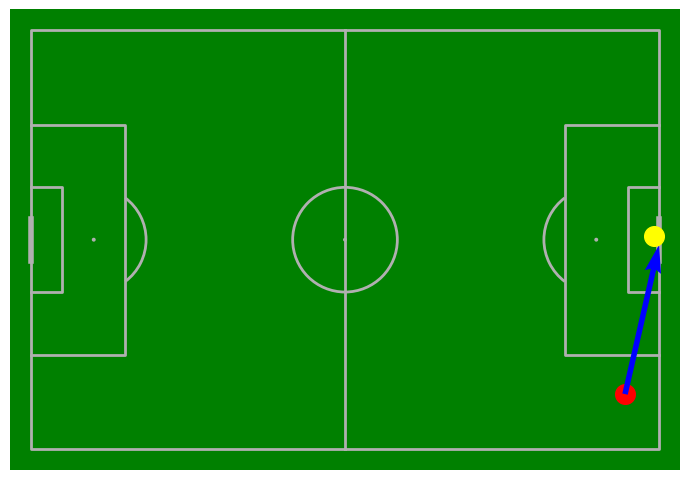

In [343]:
pitch_3 = Pitch(pitch_type="statsbomb", pitch_color="green")
fig, ax = pitch_3.draw(figsize=(7,10))
pitch_3.scatter(smallest_goal_angle["location_x"], smallest_goal_angle["location_y"], ax=ax, s=200, color="red")
pitch_3.arrows(smallest_goal_angle["location_x"],smallest_goal_angle["location_y"], 120, 41, ax=ax, color="blue", lw=5)
pitch_3.scatter(smallest_goal_angle["keeper_x"], smallest_goal_angle["keeper_y"], ax=ax, s=200, color="yellow")

#### Outlier på bane: mål med minst vinkel

Målet med minst vinkel er et frispark tatt med venstrefot fra langt ute på høyre side, i en veldig spiss vinkel. Ifølge dataene er skytteren Messi. Keeperen står på mållinjen, og ballen endte nær midten av målet (`shot_end_location`). Posisjonen og vinkelen er realistiske, så skuddet er ikke en feil i dataene.

Skuddet er sjeldent, men ekte, og det viser at selv vanskelige skudd kan gå inn. Jeg beholder det i hoveddatasettet, fordi det å fjerne slike mål ville gjort modellene for sikre på at vanskelige skudd aldri blir mål.

Dette skuddet fikk meg til å innse at spiller faktisk er en relevant feature. Spillere som Messi har et helt annet mønster enn gjennomsnittet, og en modell uten spillerinformasjon kan ikke forklare slike mål. Samtidig må spillerfeaturen tenkes nøye gjennom før den brukes, fordi den lett kan lekke data uten at man merker det. Hvis jeg target-encoder spillere og bare grupperer på `match_id`, unngår jeg at skudd fra samme kamp havner i både trening og test. Det sier derimot ingenting om tidsrekkefølgen, så en spillers verdi kan bygge på utfall fra kamper som kommer *etter* skuddet. Da har modellen i praksis sett fremtiden, og evalueringen blir urealistisk.

For å løse det har jeg hentet `match_date` og `season` fra StatsBomb sin kamptabell og lagt dem til i datasettet. De brukes ikke som features, men til to ting:
- å bygge spillerhistorikk bare fra kamper før skuddet, og
- å trene på eldre kamper og teste på nyere, som gir en mer realistisk evaluering.

Spiller blir en egen featuregruppe (`player_features`) som jeg tester i ablasjon. For å håndtere ekstreme verdier tester jeg også PowerTransformer og PCA i pipeline, og regularisering i modellene, og lar kryssvalidering avgjøre hva som fungerer best.

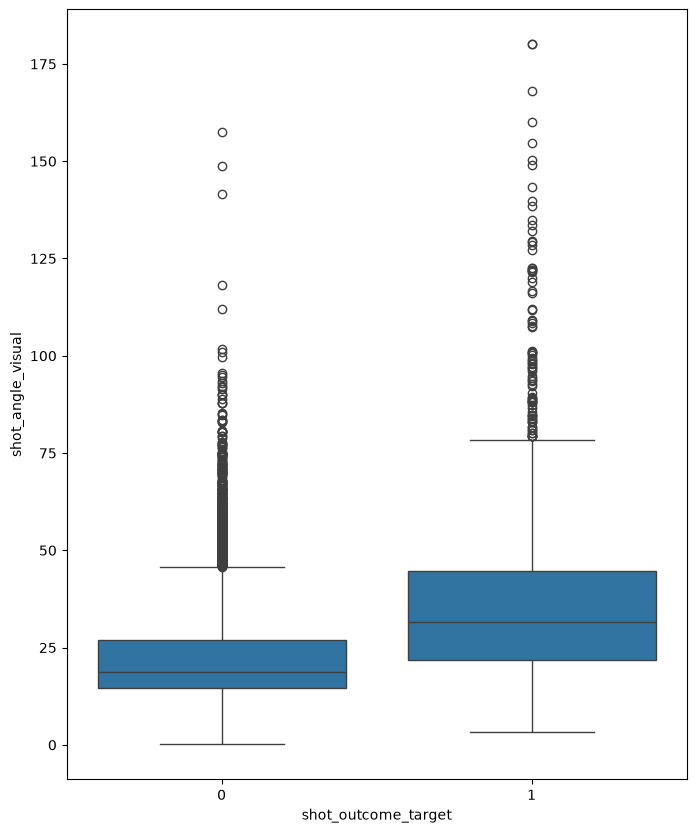

In [344]:
plt.figure(figsize=(8, 10))
sbn.boxplot(data=barcelona_shots, x=target, y="shot_angle_visual")
plt.show()

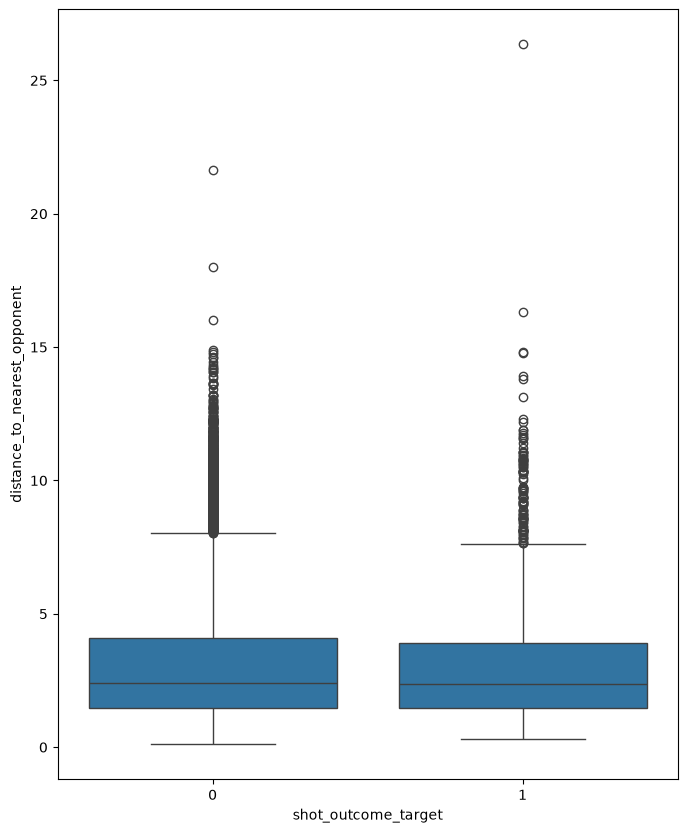

In [345]:
plt.figure(figsize=(8, 10))
sbn.boxplot(data=barcelona_shots, x=target, y="distance_to_nearest_opponent")
plt.show()

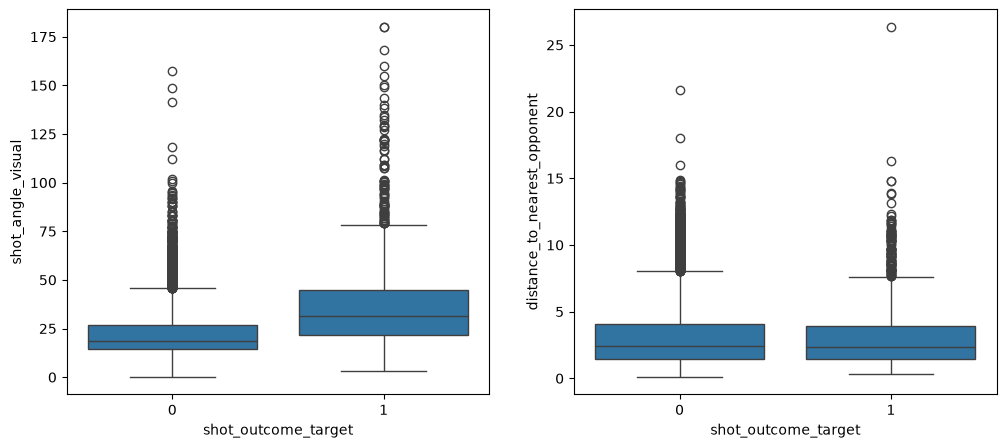

In [346]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sbn.boxplot(data=barcelona_shots, x=target, y="shot_angle_visual", ax=ax[0])
sbn.boxplot(data=barcelona_shots, x=target, y="distance_to_nearest_opponent", ax=ax[1])
plt.show()

#### Boxplot: vinkel og nærmeste motstander

For `shot_angle_visual` ligger boksen for mål tydelig høyere enn for ikke mål, så vinkelen skiller de to gruppene godt. Begge gruppene har mange punkter over værhåret, og særlig mål har mange, fordi de beste sjansene kommer fra kort hold med stor vinkel. Det betyr at "outliers" her stort sett er ekte, viktige skudd og ikke støy. Å fjerne dem med IQR-regelen ville fjernet mange mål, så jeg bruker alternativet uten IQR-outliers med forsiktighet og sammenligner det med hoveddatasettet i pipeline.

For `distance_to_nearest_opponent` er boksene nesten like for mål og ikke mål, så featuren er svak alene. Det samsvarer med histogrammene og korrelasjonen.

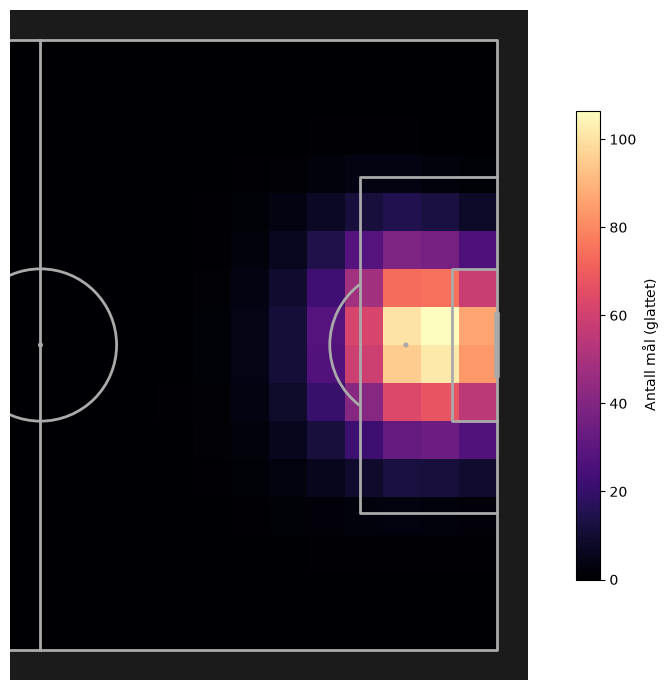

In [347]:
from scipy.ndimage import gaussian_filter

pitch = Pitch(pitch_type="statsbomb", half=True, pitch_color="#1b1b1b", line_color="#aaaaaa", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

goal_stat = pitch.bin_statistic(goals["location_x"], goals["location_y"], statistic="count", bins=(24, 16))
goal_stat["statistic"] = gaussian_filter(goal_stat["statistic"], 1)

hm = pitch.heatmap(goal_stat, ax=ax, cmap="magma", edgecolor="none")
fig.colorbar(hm, ax=ax, shrink=0.7, label="Antall mål (glattet)")
plt.show()

In [348]:
barcelona_shots.groupby("play_pattern")[target].agg(["count", "mean"])

,count,mean
play_pattern,,
From Corner,1775,0.090704
From Counter,574,0.189895
From Free Kick,3129,0.113135
From Goal Kick,479,0.148225
From Keeper,176,0.125000
From Kick Off,171,0.111111
From Throw In,2000,0.121500
Other,187,0.754011
Regular Play,4494,0.145750


In [349]:
pd.crosstab(barcelona_shots["shot_type"], barcelona_shots["play_pattern"])

play_pattern,From Corner,From Counter,From Free Kick,From Goal Kick,From Keeper,From Kick Off,From Throw In,Other,Regular Play
shot_type,,,,,,,,,
Corner,1,0,0,0,0,0,0,0,0
Free Kick,0,0,980,0,0,0,0,0,0
Open Play,1774,574,2149,479,176,171,2000,19,4494
Penalty,0,0,0,0,0,0,0,168,0


#### play_pattern

`play_pattern` forteller hvordan angrepet startet. Flest skudd kommer fra "Regular Play" (4494, 14,6 % mål), "From Free Kick" (3129, 11,3 %) og "From Throw In" (2000, 12,2 %). Skudd etter kontringer har høyest målandel av de store kategoriene (574 skudd, 19,0 %), mens skudd etter corner har lavest (1775 skudd, 9,1 %).

Kategorien "Other" har bare 187 skudd, men 75,4 % mål. Krysstabellen mot `shot_type` viser at alle 168 straffene ligger her, så "Other" er i praksis en straffe-indikator. Tilsvarende ligger alle 980 frisparkene i "From Free Kick". `play_pattern` overlapper altså delvis med `shot_type`, men gir ny informasjon for skudd i åpent spill, som kontringer, corner og innkast.

Featuren er kjent før skuddet tas, så den er ikke lekkasje. Jeg tar den med som kategorisk feature og tester i pipeline om den gir noe utover `shot_type`.

In [350]:
categorical_features = categorical_features + ["play_pattern"]
features = categorical_features + binary_features + numeric_features
X = barcelona_shots[features]

In [351]:
X.head()

,team,position,shot_body_part,shot_technique,shot_type,play_pattern,under_pressure,shot_follows_dribble,shot_aerial_won,shot_first_time,shot_one_on_one,shot_open_goal,minute,location_x,location_y,keeper_x,keeper_y,shot_distance_from_goal,shot_angle,shot_angle_visual,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle
0,Barcelona,Left Wing,Right Foot,Normal,Open Play,From Throw In,0,0,0,0,1,0,12,108.6,28.0,114.5,33.8,16.551737,46.468801,19.470701,8.273452,8.287943,0.0,1.0,0.0,2.863564,0.0
1,Deportivo Alavés,Right Midfield,Right Foot,Normal,Open Play,Regular Play,0,0,0,1,0,0,16,103.6,51.0,116.3,41.8,19.747405,33.851010,19.332894,15.682155,4.114608,0.0,0.0,2.0,6.525335,0.0
2,Barcelona,Center Forward,Left Foot,Normal,Open Play,From Throw In,0,0,0,1,0,0,19,104.3,33.9,118.5,37.8,16.843396,21.232892,25.135121,14.725828,2.662705,0.0,1.0,4.0,2.800000,1.0
3,Barcelona,Center Attacking Midfield,Left Foot,Normal,Free Kick,From Free Kick,0,0,0,0,0,0,22,97.9,44.3,119.6,40.0,22.514440,11.010480,19.806729,22.121935,0.400000,0.0,0.0,0.0,10.231324,7.0
4,Deportivo Alavés,Left Midfield,Left Foot,Normal,Open Play,Regular Play,0,0,0,0,1,1,30,118.3,42.1,110.3,44.3,2.701851,51.009006,122.607287,8.296987,10.610372,0.0,0.0,0.0,16.300307,0.0


In [352]:
X.isna().sum()

team                                     0
position                                 0
shot_body_part                           0
shot_technique                           0
shot_type                                0
play_pattern                             0
under_pressure                           0
shot_follows_dribble                     0
shot_aerial_won                          0
shot_first_time                          0
shot_one_on_one                          0
shot_open_goal                           0
minute                                   0
location_x                               0
location_y                               0
keeper_x                               151
keeper_y                               151
shot_distance_from_goal                  0
shot_angle                               0
shot_angle_visual                        0
distance_between_shooter_and_keeper    151
distance_between_keeper_and_goal       151
opponents_within_2_5_yards             139
opponents_2

In [353]:
X[X["keeper_x"].isna()]["shot_type"].value_counts()

shot_type
Penalty      139
Open Play     12
Name: count, dtype: int64

In [354]:
X[X["distance_to_nearest_opponent"].isna()]["shot_type"].value_counts()

shot_type
Penalty    168
Name: count, dtype: int64

In [355]:
X[X["opponents_in_shot_triangle"].isna()]["shot_type"].value_counts()

shot_type
Penalty    139
Name: count, dtype: int64

### Manglende verdier

Flere features har manglende verdier, og nesten alle skyldes straffer:
- `distance_to_nearest_opponent` mangler for alle 168 straffer.
- Ring-featurene og `opponents_in_shot_triangle` mangler for 139 skudd, og alle er straffer.
- Keeper-featurene (`keeper_x`, `keeper_y` og de to avstandene) mangler for 151 skudd: 139 straffer og 12 skudd fra åpent spill.

Manglene er altså ikke tilfeldige. Ved straffer finnes det ofte ingen freeze frame, og da kan vi ikke telle spillere eller finne keeperen.

Jeg håndterer dette på to måter, slik at alle modellene får nøyaktig det samme datasettet:
1. **Regelbasert fylling for straffer.** Reglene gir oss verdiene uten å bruke dataene: alle andre spillere står minst 10 yards fra ballen (ringene og trekanten blir 0), keeperen står på mållinjen (`keeper_x` = 120, `keeper_y` = 40, avstand til mål 0), og straffemerket ligger 12 yards fra mål. Nærmeste motstander settes til 10 yards og ikke 0, fordi 0 ville betydd at en motstander står oppå skytteren (maksimalt press), mens skytteren ved straff er alene. Siden fyllingen ikke avhenger av dataene, kan den ikke lekke. Jeg sjekker først at tallene stemmer mot straffene som faktisk har verdier.
2. **`SimpleImputer` med median og indikator i pipeline** for de 12 gjenstående skuddene uten keeper. Den fitter bare på treningsdata, og indikatoren forteller modellen at verdien manglet.

Jeg valgte dette fremfor å la noen modeller håndtere NaN selv og andre få imputert data, fordi modellene da ville testes på forskjellige datasett. Jeg valgte det også fremfor ren medianimputering, som ville gitt straffene oppdiktede verdier når reglene allerede gir oss et fasit for de manglende verdiene.

In [356]:
is_penalty = barcelona_shots["shot_type"] == "Penalty"

penalty_fill = {
    "opponents_within_2_5_yards": 0,
    "opponents_2_5_to_5_yards": 0,
    "opponents_5_to_10_yards": 0,
    "opponents_in_shot_triangle": 0,
    "distance_to_nearest_opponent": 10,
    "keeper_x": 120,
    "keeper_y": 40,
    "distance_between_keeper_and_goal": 0,
    "distance_between_shooter_and_keeper": 12,
}

fill_cols = list(penalty_fill)
barcelona_shots.loc[is_penalty, fill_cols] = barcelona_shots.loc[is_penalty, fill_cols].fillna(penalty_fill)

In [357]:
X = barcelona_shots[features]
X.isna().sum()[X.isna().sum() > 0]

keeper_x                               12
keeper_y                               12
distance_between_shooter_and_keeper    12
distance_between_keeper_and_goal       12
dtype: int64

In [358]:
barcelona_shots.loc[is_penalty, "location_x"].describe()

count    168.00000
mean     108.03631
std        0.15950
min      107.10000
25%      108.00000
50%      108.00000
75%      108.10000
max      108.40000
Name: location_x, dtype: float64

### Oppsummering av EDA

**Datasettet og målet.** 12 985 skudd fra La Liga-kamper med Barcelona (begge lags skudd). Målandelen er ca. 13,7 %, så klassene er ubalanserte, og jeg bruker presisjon, recall, F1 og precision-recall-kurver i tillegg til accuracy, mer om dette senere...

**Numeriske features.**
- Sterkt høyreskjeve: `distance_between_keeper_and_goal` (3,05), `shot_angle_visual` (2,46), `opponents_in_shot_triangle` (1,93) og `distance_to_nearest_opponent` (1,69). `keeper_x` er sterkt venstreskjev (−3,50). Skjevheten kommer fra ekte, sjeldne situasjoner (for eksempel keeper langt ute) og ikke fra feil, så jeg tester PowerTransformer i pipeline senere og ser om det faktisk endrer resultaatet eller modelens oppførsel
- Sterkt korrelerte par: `shot_distance_from_goal` mot avstand skytter–keeper (0,96), `location_x` mot `shot_distance_from_goal` (0,94), `keeper_x` mot avstand keeper–mål (0,90). Mye av dette er konstruert (keeperen står nær mållinjen). Jeg tester PCA i pipeline.
- Sterkest sammenheng med mål: `shot_angle_visual` (0,32), deretter avstand skytter–keeper og skuddavstand (begge −0,27). Alle korrelasjoner er lave, men sammenhengen er ikke-lineær (mål kommer fra kort hold og stor vinkel), og modellene kan utnytte mer enn korrelasjonen viser.
-- `distance_to_nearest_opponent` og `minute` er svake alene. Minuttet sier likevel lite uten kontekst: et skudd sent i kampen når laget ligger under er noe annet enn et skudd i første omgang ved 0–0. Derfor lager jeg også en feature for stillingen når skuddet ble tatt (feature engineering 2).

**Kategoriske og binære features.**
- - Straffer har klart høyest målandel (79,8 %), frispark lavest (8,1 %). Lobber (33,3 %) og kontringer (19,0 %) skiller seg ut, hodestøt scorer sjeldnere (10,8 %), og angrepsposisjoner scorer oftere enn backer og defensive midtbanespillere. (ganske obv)
- `shot_open_goal` (83,9 %) og `shot_one_on_one` (25,1 %) gir høyest målandel, mens `shot_aerial_won` (6,6 %) og `under_pressure` (10,4 %) gir lavere.
- Mange kategorier er veldig små (for eksempel "Other" med 33 skudd), så jeg sammenligner One-Hot og Ordinal-encoding.

**Outliers på bane.** Det lengste målet (ca. 53 yards) kom mot en keeper som sto langt ute, og målet med størst vinkel (over 175) ble tatt på mållinjen. Målet med minst vinkel var et frispark. Alle er ekte skudd, så jeg beholder dem. IQR-regelen ville fjernet mange ekte mål på `shot_angle_visual`, så alternativet uten IQR-outliers brukes med forsiktighet.

**Manglende verdier.** Nesten alle skyldes straffer. De fylles regelbasert (straffer ligger rundt x = 108, bekreftet), og de 12 gjenstående imputeres med median og indikator i pipeline.

**Beslutninger videre.** `play_pattern` tas med. `second` er fjernet. Skjeve features testes med PowerTransformer, korrelerte med PCA. Feature engineering 2 består av to nye featuregrupper som testes i ablasjon:
- `game_state_features`: stillingen når skuddet ble tatt (mål for og imot, og differansen), regnet ut fra mål som er scoret strengt før skuddet i samme kamp.
- `player_features`: spillerhistorikk, altså spillerens mål og skudd i tidligere kamper, glattet mot snittet og regnet ut fra `match_date` slik at ingen fremtidig informasjon brukes.

Splitten er tidsbasert: tren på eldre sesonger og test på de tre siste.

In [359]:
barcelona_shots.groupby("season").size()

season
1973/1974     28
2004/2005    158
2005/2006    433
2006/2007    681
2007/2008    700
2008/2009    765
2009/2010    843
2010/2011    739
2011/2012    873
2012/2013    721
2013/2014    810
2014/2015    931
2015/2016    972
2016/2017    882
2017/2018    971
2018/2019    887
2019/2020    752
2020/2021    839
dtype: int64

In [360]:
barcelona_shots.groupby("player_id")[target].count().describe()

count    1215.000000
mean       10.687243
std        74.475537
min         1.000000
25%         1.000000
50%         3.000000
75%         6.000000
max      2352.000000
Name: shot_outcome_target, dtype: float64

In [361]:
barcelona_shots = barcelona_shots.drop(columns=["goals_before", "shots_before", "goals_before_x", "shots_before_x", "goals_before_y", "shots_before_y", "player_goal_rate_before"], errors="ignore")
# 1. Mål og skudd per spiller per kamp
per_match = barcelona_shots.groupby(["player_id", "match_date"])[target].agg(goals="sum", shots="count").reset_index()

# 2. Sorter hver spillers kamper i tidsrekkefølge
per_match = per_match.sort_values(["player_id", "match_date"])

# 3 Løpende sum: alle kamper til og med denne kampen
per_match["goals_including_this"] = per_match.groupby("player_id")["goals"].cumsum()
per_match["shots_including_this"] = per_match.groupby("player_id")["shots"].cumsum()

# 4 Trekk fra denne kampen: da står bare tidligere kamper igjen
per_match["goals_before"] = per_match["goals_including_this"] - per_match["goals"]
per_match["shots_before"] = per_match["shots_including_this"] - per_match["shots"]

barcelona_shots = barcelona_shots.merge(
    per_match[["player_id", "match_date", "goals_before", "shots_before"]],
    on=["player_id", "match_date"], how="left", validate="many_to_one")

test_seasons = ["2018/2019", "2019/2020", "2020/2021"]
is_test = barcelona_shots["season"].isin(test_seasons)

prior = barcelona_shots.loc[~is_test, target].mean()   # målandel i treningsdelen
m = 10                      # smoothing-styrke mer om hvorfor 10 i markdown


barcelona_shots["player_goal_rate_before"] = (barcelona_shots["goals_before"] + m * prior) / (barcelona_shots["shots_before"] + m)
player_features = ["player_goal_rate_before", "shots_before"]

In [362]:
print(len(barcelona_shots), len(is_test))
barcelona_shots["player_goal_rate_before"].isna().sum()

12985 12985


np.int64(0)

In [363]:
barcelona_shots.loc[barcelona_shots["shots_before"] == 0, "player_goal_rate_before"].unique()

array([0.13828876])

### Feature engineering 2: spillerhistorikk

Frisparket til Messi viste at spiller er en relevant feature. For å skille spillerne fra hverandre bruker jeg hvor ofte skuddene deres har blitt mål, ikke bare hvor mange skudd de har tatt. Verdien beregnes bare fra kamper **før** skuddets kamp, slik at ingen fremtidig informasjon brukes, og den fortsetter på tvers av sesongene.

**Slik beregnes den**

1. Jeg samler mål og skudd per spiller per kamp.
2. Med en løpende sum (`cumsum`) minus kampens egne tall får jeg spillerens mål og skudd i alle tidligere kamper.
3. Jeg regner ut et vektet gjennomsnitt av spillerens egen målrate og gjennomsnittet i treningsdelen:

$$\text{rate} = \frac{\text{mål før} + m \cdot p}{\text{skudd før} + m}$$

Her er $p$ målandelen i treningssesongene og $m = 10$ er hvor mange skudd som skal til før spillerens egen rate teller like mye som gjennomsnittet. Formelen kan også skrives som $w \cdot \text{egen rate} + (1 - w) \cdot p$ med $w = \frac{\text{skudd før}}{\text{skudd før} + m}$. En spiller uten tidligere skudd får dermed gjennomsnittet, og en spiller med mange skudd får sin egen rate.

**Hvorfor et vektet gjennomsnitt?** Et vanlig gjennomsnitt gir en spiller med ett skudd og ett mål en målrate på 100 %, og det sier lite. Et vektet gjennomsnitt lar spillere med mange skudd telle mer enn spillere med få. Ifølge [(https://www.investopedia.com/terms/w/weightedaverage.asp)] passer et vektet gjennomsnitt best når datapunktene har ulik viktighet, men vektene innebærer også noe subjektivitet, og resultatet kan være følsomt for hvordan de velges. Det stemmer her: skuddene har ulik pålitelighet etter hvor mange skudd spilleren har. 

**Valget av m.** Jeg valgte `m` etter å ha kjørt `groupby("player_id")[target].count().describe()`. Datasettet har 1215 spillere, og antall skudd per spiller har et gjennomsnitt på ca. 10,7, en median på 3, og 75 % av spillerne har 6 skudd eller færre, mens den mest aktive spilleren har 2352. At gjennomsnittet ligger langt over 75 %-kvartilen, viser at fordelingen er svært skjev: noen få spillere har veldig mange skudd, mens de aller fleste har få.

Derfor bruker jeg `m = 10`, omtrent på nivå med gjennomsnittet. Det er en heuristikk og ikke tunet. En lavere `m` gir mer av spillerens egen rate, men også mer støy for spillere med få skudd, og en høyere `m` trekker nesten alle spillere mot gjennomsnittet. De fleste spillere får dermed omtrent gjennomsnittsverdien, mens spillere med mange tidligere skudd får sin egen målrate. Antall tidligere skudd er med som egen feature (`shots_before`), slik at modellen ser hvor pålitelig raten er.

**Lekkasje.** Skuddets egen kamp er ikke med, og heller ikke senere kamper. Gjennomsnittet `p` regnes bare ut fra treningssesongene. Treningsperiodens utfall brukes til å beregne verdiene for senere skudd, noe som er lovlig fordi slik informasjon er kjent i praksis. altså alt er regnet basert på fortiden og forrige kamper og ingen form for lekkasje her.

Featuren (`player_features`) testes i ablasjon sammen med `game_state_features`.

In [364]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,match_date,season,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle,shot_outcome_target,goals_before,shots_before,player_goal_rate_before
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,2020-10-31,2020/2021,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0,2.863564,0.0,0,9,35,0.230731
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,2020-10-31,2020/2021,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0,6.525335,0.0,0,0,4,0.098778
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,2020-10-31,2020/2021,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0,2.800000,1.0,0,9,80,0.115365
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,2020-10-31,2020/2021,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0,10.231324,7.0,0,443,2175,0.203379
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,2020-10-31,2020/2021,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0,16.300307,0.0,1,0,1,0.125717


In [365]:
fati = barcelona_shots[barcelona_shots["player_id"] == 30756]
fati[fati["match_date"] < "2020-10-31"][target].agg(["sum", "count"])

sum       9
count    35
Name: shot_outcome_target, dtype: int64

In [366]:
fati.groupby("season")[target].agg(["sum", "count"])

,sum,count
season,,
2019/2020,5,27
2020/2021,4,14


**Kontroll.** Jeg sjekket historikken for Ansu Fati (`player_id` 30756). Før kampen 31. oktober 2020 har han 9 mål på 35 skudd i datasettet (5 mål på 27 skudd i 2019/20 og resten i 2020/21 før denne kampen), og det er nøyaktig det `goals_before` og `shots_before` viser. Det bekrefter at historikken summerer tidligere kamper riktig, også på tvers av sesonger.

In [367]:
barcelona_shots = barcelona_shots.drop(columns=["goals_for_before", "goals_against_before", "score_diff_before"], errors="ignore")

# 1. Sorter skuddene kronologisk innenfor hver kamp
shots_sorted = barcelona_shots.sort_values(["match_id", "period", "minute", "second"])

# 2. Mål for skytterens lag FØR dette skuddet:
#    løpende sum av mål per lag per kamp, minus dette skuddets eget utfall
shots_sorted["goals_for_before"] = shots_sorted.groupby(["match_id", "team"])[target].cumsum() - shots_sorted[target]

# 3. Alle mål i kampen (begge lag) FØR dette skuddet
shots_sorted["goals_in_match_before"] = shots_sorted.groupby("match_id")[target].cumsum() - shots_sorted[target]

# 4. Motstanderens mål = alle mål minus skytterens eget lags mål
shots_sorted["goals_against_before"] = shots_sorted["goals_in_match_before"] - shots_sorted["goals_for_before"]

# 5. Kopier tilbake til hovedtabellen (matcher på indeksen)
barcelona_shots["goals_for_before"] = shots_sorted["goals_for_before"]
barcelona_shots["goals_against_before"] = shots_sorted["goals_against_before"]
barcelona_shots["score_diff_before"] = barcelona_shots["goals_for_before"] - barcelona_shots["goals_against_before"]

game_state_features = ["goals_for_before", "goals_against_before", "score_diff_before"]

### Feature engineering 2: stillingen når skuddet ble tatt

Et skudd sent i kampen når laget ligger under er noe annet enn et skudd ved 0–0, og `minute` alene fanger ikke det. Jeg lager derfor tre features (`game_state_features`): `goals_for_before`, `goals_against_before` og `score_diff_before` (positiv hvis skytterens lag leder).

- `goals_for_before`: mål skytterens lag har scoret så langt i kampen.
- `goals_against_before`: mål motstanderen har scoret så langt.
- `score_diff_before`: differansen (positiv hvis skytterens lag leder, negativ hvis det ligger under). Et Barça-skudd etter at motstanderen har scoret første mål, har for eksempel verdien −1.

Begrensning: vi har bare skudd, så selvmål er ikke med, og stillingen kan avvike litt fra den virkelige.

In [368]:
one_match = barcelona_shots[barcelona_shots["match_id"] == barcelona_shots["match_id"].iloc[0]]
one_match[["team", "period", "minute", "second", target, "goals_for_before", "goals_against_before"]].sort_values(["period", "minute", "second"])

,team,period,minute,second,shot_outcome_target,goals_for_before,goals_against_before
0,Barcelona,1,12,19,0,0,0
1,Deportivo Alavés,1,16,7,0,0,0
2,Barcelona,1,19,42,0,0,0
3,Barcelona,1,22,26,0,0,0
4,Deportivo Alavés,1,30,6,1,0,0
5,Barcelona,1,35,25,0,0,1
6,Barcelona,1,42,34,0,0,1
7,Deportivo Alavés,1,44,47,0,1,0
8,Barcelona,1,45,16,0,0,1
9,Barcelona,2,47,47,0,0,1


liten sjekk/kontroll på én kamp (Alavés 1–1 Barcelona): hvert mål dukker opp i tellingen først på skuddene etter målet, aldri på selve målskuddet, og stillingen ender på 1–1.

In [369]:
all_features = features + player_features + game_state_features
X = barcelona_shots[all_features]
y = barcelona_shots[target]
groups = barcelona_shots[group_column]

In [370]:
X.head()

,team,position,shot_body_part,shot_technique,shot_type,play_pattern,under_pressure,shot_follows_dribble,shot_aerial_won,shot_first_time,shot_one_on_one,shot_open_goal,minute,location_x,location_y,keeper_x,keeper_y,shot_distance_from_goal,shot_angle,shot_angle_visual,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle,player_goal_rate_before,shots_before,goals_for_before,goals_against_before,score_diff_before
0,Barcelona,Left Wing,Right Foot,Normal,Open Play,From Throw In,0,0,0,0,1,0,12,108.6,28.0,114.5,33.8,16.551737,46.468801,19.470701,8.273452,8.287943,0.0,1.0,0.0,2.863564,0.0,0.230731,35,0,0,0
1,Deportivo Alavés,Right Midfield,Right Foot,Normal,Open Play,Regular Play,0,0,0,1,0,0,16,103.6,51.0,116.3,41.8,19.747405,33.851010,19.332894,15.682155,4.114608,0.0,0.0,2.0,6.525335,0.0,0.098778,4,0,0,0
2,Barcelona,Center Forward,Left Foot,Normal,Open Play,From Throw In,0,0,0,1,0,0,19,104.3,33.9,118.5,37.8,16.843396,21.232892,25.135121,14.725828,2.662705,0.0,1.0,4.0,2.800000,1.0,0.115365,80,0,0,0
3,Barcelona,Center Attacking Midfield,Left Foot,Normal,Free Kick,From Free Kick,0,0,0,0,0,0,22,97.9,44.3,119.6,40.0,22.514440,11.010480,19.806729,22.121935,0.400000,0.0,0.0,0.0,10.231324,7.0,0.203379,2175,0,0,0
4,Deportivo Alavés,Left Midfield,Left Foot,Normal,Open Play,Regular Play,0,0,0,0,1,1,30,118.3,42.1,110.3,44.3,2.701851,51.009006,122.607287,8.296987,10.610372,0.0,0.0,0.0,16.300307,0.0,0.125717,1,0,0,0


In [371]:
barcelona_shots["season"].value_counts().count()

np.int64(18)

In [372]:
#Har allerede laget test sesongene når jeg skulle featre engeeinere spillerns features
"""
test_seasons = ["2018/2019", "2019/2020", "2020/2021"]
is_test = barcelona_shots["season"].isin(test_seasons)
"""
trainval_indices = barcelona_shots[~is_test].index
test_indices = barcelona_shots[is_test].index

train_features= X.loc[trainval_indices]
train_target = y.loc[trainval_indices]

test_features = X.loc[test_indices]
test_target = y.loc[test_indices]

In [373]:
train_groups = groups.loc[trainval_indices]

In [374]:
X.dtypes

team                                       str
position                                   str
shot_body_part                             str
shot_technique                             str
shot_type                                  str
play_pattern                               str
under_pressure                           int64
shot_follows_dribble                     int64
shot_aerial_won                          int64
shot_first_time                          int64
shot_one_on_one                          int64
shot_open_goal                           int64
minute                                   int64
location_x                             float64
location_y                             float64
keeper_x                               float64
keeper_y                               float64
shot_distance_from_goal                float64
shot_angle                             float64
shot_angle_visual                      float64
distance_between_shooter_and_keeper    float64
distance_betw

In [375]:
dt_pipe_simple = Pipeline([
    ("transformer", ColumnTransformer([
        ("num", 
         Pipeline([
             ("fillna", SimpleImputer(strategy="median", add_indicator=True)),
             ("scaler", StandardScaler()) #Skal fylle den med ulike scalere som standard og minmax
             ]) ,numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ("bin", "passthrough", binary_features)
        ])),
    ("estimator", "passthrough"),
])

In [376]:
dt_pipe_advanced = Pipeline([
    ("transformer", ColumnTransformer([
        ("num", Pipeline([
            ("fillna", SimpleImputer(strategy="median", add_indicator=True)),
            ("power", PowerTransformer(method="yeo-johnson", standardize=True)),
            ("pca", PCA(n_components=0.95)),
        ]), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ("bin", "passthrough", binary_features),
    ])),
    ("estimator", "passthrough"),
])

## Pipelines

Jeg lager to generelle pipelines som mange modeller kan bruke. De er en fast grunnmur. Detaljene (modellparametre, valg av encoder og scaler) endrer jeg senere via param-dicter (`dt_params`), og det er dicten som egentlig styrer hva som endres når jeg hypertuner.

**Simple pipeline**
- Numeriske: `SimpleImputer` (median, med indikator) og `StandardScaler`
- Kategoriske: `OneHotEncoder`
- Binære: `passthrough`
- Estimator settes i dicten

**Advanced pipeline**
- Numeriske: `SimpleImputer` (median, med indikator), `PowerTransformer` (Yeo-Johnson) og `PCA` (95 % av variansen)
- Kategoriske og binære som over
- Estimator settes i dicten

Den advanced pipelinen håndterer manglende verdier, skjeve fordelinger og korrelerte features. Det gjør at den også passer for modeller som er sensitive for dette, som logistisk regresjon og ANN.

Begge pipelines har fast estimator (`"passthrough"`), som byttes ut i dicten. Dermed kan samme pipeline brukes til Decistion trees, random forest, boosting, logistisk regresjon og ANN, og sammenligningen mellom modellene blir rettferdig fordi forbehandlingen er lik.

In [377]:
dt_simple_pipe_params = {
    "estimator" : [DecisionTreeClassifier(class_weight="balanced")], 
    "estimator__max_depth": [10, 50, 100, 150],
    "estimator__min_samples_leaf" : [20,50, 100,150],
    "transformer__num__scaler":[StandardScaler(), MinMaxScaler()],
    "transformer__cat":[OneHotEncoder(), TargetEncoder(), OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)]
}

In [378]:
dt_simple_pipe_grid = GridSearchCV(dt_pipe_simple, dt_simple_pipe_params, scoring="accuracy", n_jobs=-2)
dt_simple_pipe_grid.fit(train_features, train_target)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...assthrough')])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'estimator': [DecisionTreeC...ht='balanced')], 'estimator__max_depth': [10, 50, ...], 'estimator__min_samples_leaf': [20, 50, ...], 'transformer__cat': [OneHotEncoder(), TargetEncoder(), ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchang

In [379]:
dt_simple_pipe_grid.best_score_

np.float64(0.7383675754058486)

In [380]:
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}


In [381]:
dt_simple_pipe_grid2 = GridSearchCV(dt_pipe_simple, dt_simple_pipe_params, scoring=scoring,refit="f1", n_jobs=-2)
dt_simple_pipe_grid2.fit(train_features, train_target)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...assthrough')])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'estimator': [DecisionTreeC...ht='balanced')], 'estimator__max_depth': [10, 50, ...], 'estimator__min_samples_leaf': [20, 50, ...], 'transformer__cat': [OneHotEncoder(), TargetEncoder(), ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for th

In [382]:
dt_simple_pipe_grid2.best_score_

np.float64(0.42900576268297463)

## Valg av metrikker

Kun ca. 13,7 % av skuddene er mål, så metrikken må velges med omhu.

| Metrikk | Hva den måler | Brukes til |
| --- | --- | --- |
| Accuracy | Andel riktige totalt | Rapporteres, men brukes ikke til valg |
| Precision | Av skuddene vi tipper som mål, hvor mange er det? | Rapporteres |
| Recall | Av alle faktiske mål, hvor mange finner vi? | Rapporteres |
| F1 | Balanse mellom precision og recall for mål | **Valg av modell** |
| PR-AUC | Precision/recall på tvers av terskler | Støtte |

**Bevis fra beslutningstreet**

Jeg kjørte samme pipeline og samme parameterrutenett to ganger, én gang med accuracy og én gang med F1 som score:

- Accuracy: **0,736**
- F1: **0,4309**

Accuracy ser ganske høy ut, men sier lite om hvor godt treet finner mål. F1 viser at det er langt fra perfekt. En modell som alltid gjetter «ikke mål» ville fått ca. 86 % accuracy (1 − 0,137) uten å finne ett eneste mål, så accuracy kan ikke skille en god modell fra en som bare gjetter.

Derfor velger jeg modell på **F1**, og bruker accuracy, precision, recall og confusion matrix til å forklare hva modellen gjør.

In [401]:
def show_results(grid, name="", top=5):
    print(f"{name}: beste F1 = {grid.best_score_:.4f}")
    display(pd.Series(grid.best_params_).astype(str).to_frame("beste verdi"))

    results = pd.DataFrame(grid.cv_results_).sort_values("mean_test_f1", ascending=False)
    param_cols = results.filter(like="param_").columns.tolist()
    score_cols = ["mean_test_f1", "std_test_f1", "mean_fit_time"]
    display(results[score_cols + param_cols].head(top))

def show_metrics(grid, name=""):
    results = pd.DataFrame(grid.cv_results_)
    best = results.loc[grid.best_index_]

    table = pd.DataFrame({
        "snitt": [best["mean_test_accuracy"], best["mean_test_precision"],
                  best["mean_test_recall"], best["mean_test_f1"]],
        "std": [best["std_test_accuracy"], best["std_test_precision"],
                best["std_test_recall"], best["std_test_f1"]],
    }, index=["accuracy", "precision", "recall", "f1"])

    print(name)
    display(table.round(3))

def compare_train_cv_test(grid, train_features, train_target, test_features, test_target, name=""):
    best = pd.DataFrame(grid.cv_results_).loc[grid.best_index_]
    train_pred = grid.best_estimator_.predict(train_features)
    test_pred = grid.best_estimator_.predict(test_features)

    table = pd.DataFrame({
        "train": [accuracy_score(train_target, train_pred), precision_score(train_target, train_pred),
                  recall_score(train_target, train_pred), f1_score(train_target, train_pred)],
        "CV": [best["mean_test_accuracy"], best["mean_test_precision"],
               best["mean_test_recall"], best["mean_test_f1"]],
        "test": [accuracy_score(test_target, test_pred), precision_score(test_target, test_pred),
                 recall_score(test_target, test_pred), f1_score(test_target, test_pred)],
    }, index=["accuracy", "precision", "recall", "f1"])

    print(name)
    display(table.round(3))

In [384]:
show_results(dt_simple_pipe_grid, name="Decision Tree, simple")

Decision Tree, simple: beste score = 0.7384


,beste verdi
estimator,DecisionTreeClassifier(class_weight='balanced')
estimator__max_depth,150
estimator__min_samples_leaf,100
transformer__cat,TargetEncoder()
transformer__num__scaler,MinMaxScaler()


,mean_test_score,std_test_score,mean_fit_time,param_estimator,param_estimator__max_depth,param_estimator__min_samples_leaf,param_transformer__cat,param_transformer__num__scaler
87,0.738368,0.019111,0.116260,DecisionTreeClassifier(class_weight='balanced'),150,100,TargetEncoder(),MinMaxScaler()
15,0.734656,0.016134,0.123287,DecisionTreeClassifier(class_weight='balanced'),10,100,TargetEncoder(),MinMaxScaler()
86,0.733225,0.009247,0.125601,DecisionTreeClassifier(class_weight='balanced'),150,100,TargetEncoder(),StandardScaler()
39,0.732943,0.021374,0.111896,DecisionTreeClassifier(class_weight='balanced'),50,100,TargetEncoder(),MinMaxScaler()
20,0.732089,0.029294,0.122951,DecisionTreeClassifier(class_weight='balanced'),10,150,TargetEncoder(),StandardScaler()


<Axes: xlabel='param_estimator__min_samples_leaf', ylabel='mean_test_f1'>

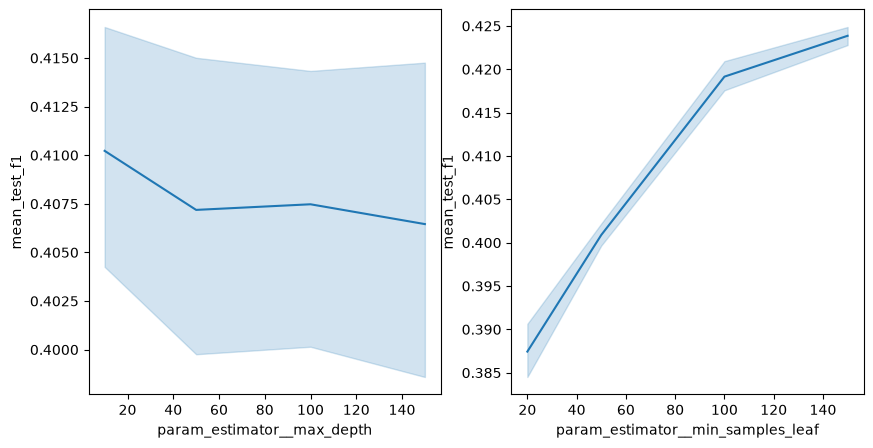

In [389]:
rf_cv_results = pd.DataFrame(dt_simple_pipe_grid2.cv_results_)


fig, axs = plt.subplots(1, 2, figsize=(10, 5))
sbn.lineplot(data=rf_cv_results, x='param_estimator__max_depth', y='mean_test_f1', ax=axs[0])
sbn.lineplot(data=rf_cv_results, x='param_estimator__min_samples_leaf', y='mean_test_f1', ax=axs[1])

### Grov tuning: funn og justering

Plottet av `cv_results_` fra første rutenett viste:

- **`max_depth`:** F1 faller svakt jo dypere treet er (ca. 0,411 ved 10 og ca. 0,407 ved 50–150), og konfidensbåndene overlapper. Store verdier gir ingen gevinst, så jeg bruker et kortere intervall: `[5, 10, 15]`.
- **`min_samples_leaf`:** F1 stiger jevnt fra ca. 0,39 ved 20 til ca. 0,425 ved 150, og flater ikke ut. Beste verdi ligger ytterst i rutenettet, så jeg utvider intervallet oppover.

**Andre parametere jeg tar med i fin tuning**

- `min_samples_split`: minste antall skudd i en node for at den kan deles. Sammen med `min_samples_leaf` styrer den hvor store treets blader blir.
- `criterion` (`gini`, `entropy`): hvordan en deling måles. Det er et valg som kan ha litt å si på ubalanserte data.
- `max_features`: hvor mange features treet ser på per deling. Færre gir mer tilfeldighet og kan redusere overtilpasning.
- `ccp_alpha`: beskjæring etter at treet er bygget. Større verdi gir et enklere tre.

Neste kjøring (fin tuning) bruker derfor kort intervall for `max_depth`, lengre intervall for `min_samples_leaf`, og de ekstra parameterne over.

In [394]:
dt_simple_pipe_params2 = {
    "estimator": [DecisionTreeClassifier(class_weight="balanced", random_state=42)],
    "estimator__max_depth": [5, 10, 15],
    "estimator__min_samples_leaf": [100, 150, 200, 300, 500],
    "estimator__min_samples_split": [2, 20, 50],
    "estimator__criterion": ["gini", "entropy"],
    "estimator__max_features": [None, "sqrt"],
    "transformer__cat": [
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        TargetEncoder(),
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    ],
}

inner_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

dt_simple_pipe_grid3 = GridSearchCV(dt_pipe_simple, dt_simple_pipe_params2, 
                                    scoring=scoring, refit="f1", cv=inner_cv, n_jobs=-2, verbose=1)
dt_simple_pipe_grid3.fit(train_features, train_target, groups=train_groups)

Fitting 5 folds for each of 540 candidates, totalling 2700 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...assthrough')])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'estimator': [DecisionTreeC...ndom_state=42)], 'estimator__criterion': ['gini', 'entropy'], 'estimator__max_depth': [5, 10, ...], 'estimator__max_features': [None, 'sqrt'], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-valid

In [396]:
show_results(dt_simple_pipe_grid3, name="Decision Tree, simple, fin tuning")

Decision Tree, simple, fin tuning: beste F1 = 0.4410


,beste verdi
estimator,DecisionTreeClassifier(class_weight='balanced'...
estimator__criterion,gini
estimator__max_depth,10
estimator__max_features,sqrt
estimator__min_samples_leaf,500
estimator__min_samples_split,20
transformer__cat,TargetEncoder()


,mean_test_f1,std_test_f1,mean_fit_time,param_estimator,param_estimator__criterion,param_estimator__max_depth,param_estimator__max_features,param_estimator__min_samples_leaf,param_estimator__min_samples_split,param_transformer__cat
175,0.440961,0.020455,0.051750,DecisionTreeClassifier(class_weight='balanced'...,gini,10,sqrt,500,20,TargetEncoder()
331,0.440775,0.013138,0.055198,DecisionTreeClassifier(class_weight='balanced'...,entropy,5,sqrt,150,50,TargetEncoder()
470,0.440491,0.010267,0.090550,DecisionTreeClassifier(class_weight='balanced'...,entropy,15,NaN,200,2,OrdinalEncoder(handle_unknown='use_encoded_val...
473,0.440491,0.010267,0.094608,DecisionTreeClassifier(class_weight='balanced'...,entropy,15,NaN,200,20,OrdinalEncoder(handle_unknown='use_encoded_val...
386,0.440491,0.010267,0.084178,DecisionTreeClassifier(class_weight='balanced'...,entropy,10,NaN,200,50,OrdinalEncoder(handle_unknown='use_encoded_val...


In [398]:
show_metrics(grid=dt_simple_pipe_grid3, name="Decision Tree, simple")

Decision Tree, simple


,snitt,std
accuracy,0.779,0.024
precision,0.342,0.028
recall,0.627,0.040
f1,0.441,0.020


<Axes: xlabel='param_estimator__min_samples_leaf', ylabel='mean_test_score'>

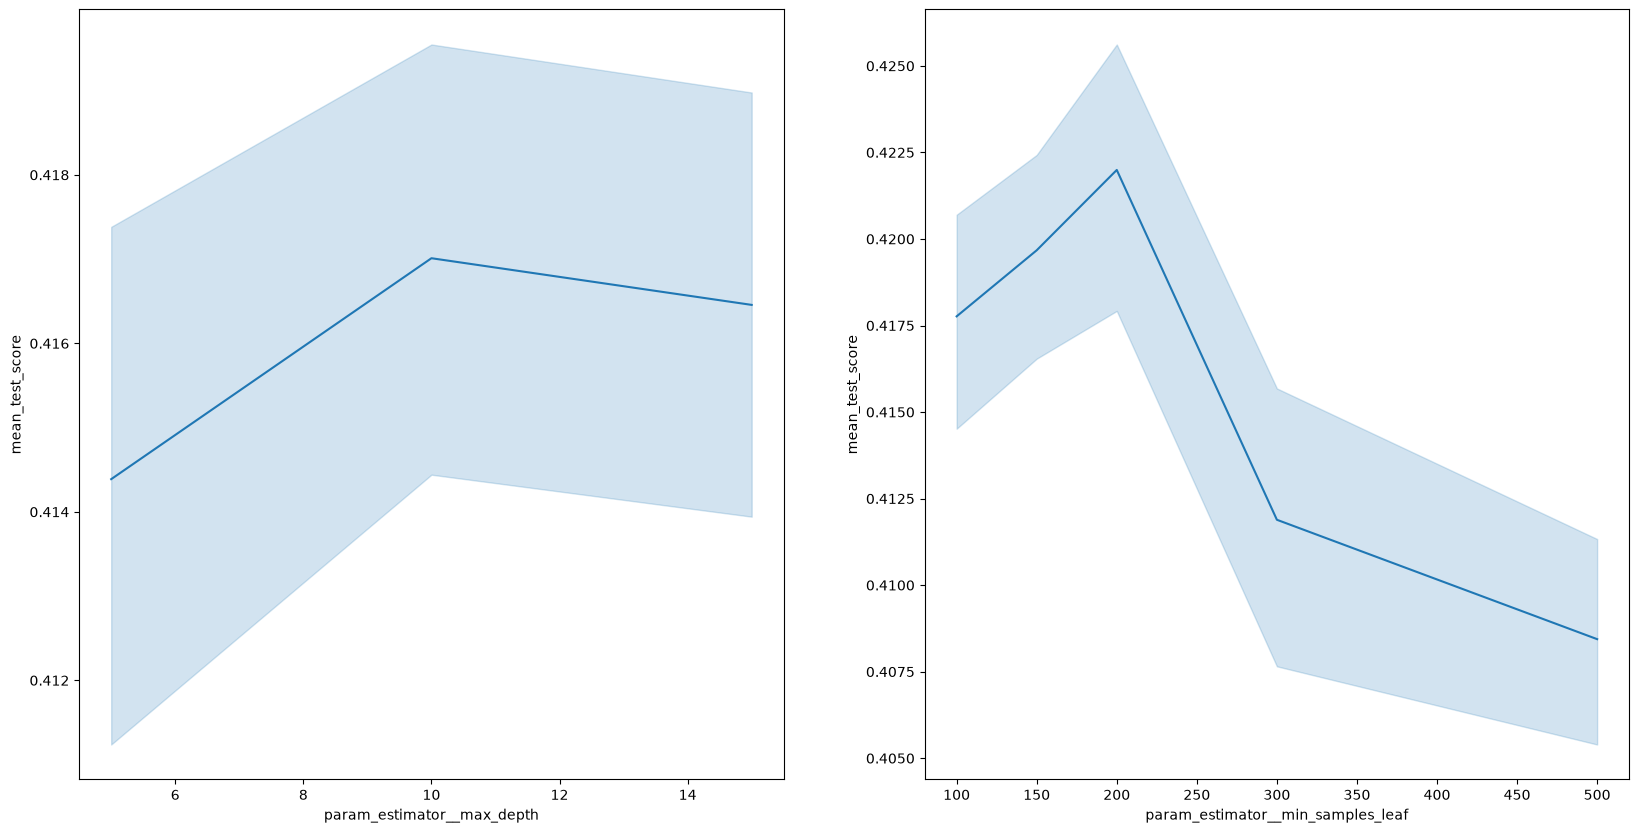

In [ ]:
rf_cv_results2 = pd.DataFrame(dt_simple_pipe_grid3.cv_results_)


fig, ax= plt.subplots(1, 2, figsize=(20,10))
sbn.lineplot(data=rf_cv_results2, x="param_estimator__max_depth", y="mean_test_score", ax=ax[0])
sbn.lineplot(data=rf_cv_results2, x="param_estimator__min_samples_leaf",y="mean_test_score", ax=ax[1] )


<Axes: xlabel='param_estimator__min_samples_split', ylabel='mean_test_score'>

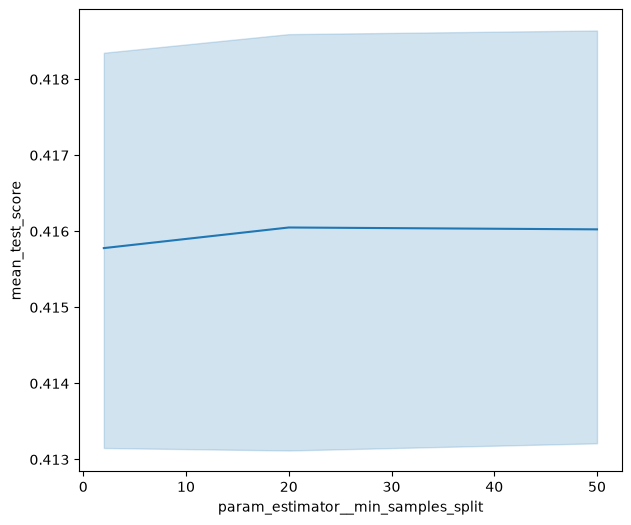

In [ ]:
fig, ax= plt.subplots(1, 1, figsize=(7,6))
sbn.lineplot(data=rf_cv_results2, x="param_estimator__min_samples_split", y="mean_test_score", ax=ax)


### Fin tuning: resultat for beslutningstreet (simple pipeline)

Beste F1 i CV ble **0,4405**, med `min_samples_leaf=200`, `max_depth=10`, `criterion="entropy"`, `max_features=None`, `min_samples_split=2` og `TargetEncoder`.

Lineplottene av `cv_results_` viser hva som gjør jobben:

- **`min_samples_leaf`** er den eneste parameteren med tydelig effekt. F1 stiger fra 100 til en topp ved 200 (ca. 0,422 i snitt), og faller deretter ved 300 og 500. Toppen ligger midt i rutenettet, så intervallet var stort nok.
- **`max_depth`** har liten effekt (ca. 0,414 ved 5 og ca. 0,417 ved 10 og 15), og konfidensbåndene overlapper.
- **`min_samples_split`** er helt flat (ca. 0,416) uten forskjell mellom 2, 20 og 50. Store blader (`min_samples_leaf`) gjør at den ikke får noen betydning.

Konklusjon: det er størrelsen på bladene som styrer hvor godt treet generaliserer. De andre parameterne spiller liten rolle.

In [402]:
dt_simple_pipe_params3 = {
    "estimator": [DecisionTreeClassifier(class_weight="balanced", random_state=42)],
    "estimator__min_samples_leaf": [100, 150, 200, 250, 300],
    "estimator__max_depth": [8, 10, 12],
    "estimator__criterion": ["gini", "entropy"],
    "estimator__max_features": [None, "sqrt"],
    "transformer__cat": [
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        TargetEncoder(),
    ],
}

In [ ]:
train_seasons = barcelona_shots.loc[~is_test, "season"]
blocks = np.array_split(sorted(train_seasons.unique()), 3)

outer_scores = []

# YTRE LØKKE: hver blokk er test én gang
for test_block in blocks:
    outer_test = train_seasons.isin(test_block)

    X_tr, y_tr, g_tr = train_features[~outer_test], train_target[~outer_test], train_groups[~outer_test]
    X_te, y_te = train_features[outer_test], train_target[outer_test]

    # INDRE LØKKE: GridSearchCV tuner på ytre trening
    grid = GridSearchCV(clone(dt_pipe_simple), dt_simple_pipe_params2,
                        scoring=scoring, refit="f1", cv=inner_cv, n_jobs=-2)
    grid.fit(X_tr, y_tr, groups=g_tr)

    pred = grid.best_estimator_.predict(X_te)
    outer_scores.append({
        "test_blokk": test_block[0] + " ... " + test_block[-1],
        "antall_skudd": len(y_te),
        "accuracy": accuracy_score(y_te, pred),
        "precision": precision_score(y_te, pred),
        "recall": recall_score(y_te, pred),
        "f1": f1_score(y_te, pred),
        "indre_cv_f1": grid.best_score_,
    })

nested_results = pd.DataFrame(outer_scores)
display(nested_results.round(3))
print("Snitt ytre F1:", nested_results["f1"].mean().round(3))

,test_blokk,antall_skudd,accuracy,precision,recall,f1,indre_cv_f1
0,1973/1974 ... 2007/2008,2000,0.788,0.311,0.625,0.415,0.445
1,2008/2009 ... 2012/2013,3941,0.715,0.315,0.747,0.443,0.453
2,2013/2014 ... 2017/2018,4566,0.693,0.271,0.759,0.399,0.447


Snitt ytre F1: 0.419


**Hva jeg tenker resultatet betyr**

- Vanlig CV ga F1 ≈ 0,44, men nested CV viser at et mer ærlig estimat er ca. 0,42. Tuningen ga et litt for pent tall fordi den beste av mange kombinasjoner ble valgt og scoret på de samme dataene.
- Variasjonen mellom blokkene (F1 fra 0,40 til 0,44) viser at modellen ikke gjør det like bra i alle tidsperioder. Den svakeste blokken er den nyeste.
- Recall (0,63–0,76) er klart høyere enn precision (0,27–0,32). Modellen finner de fleste målene, men tipper også mange skudd som mål som ikke er det. Det er prisen for `class_weight="balanced"`.
- Til sammen forteller det at beslutningstreet er en brukbar baseline, men ikke mer. Vi forventer at F1 på test-sesongene havner rundt 0,42, og at de mer avanserte modellene må slå det.

In [ ]:
dt_advanced_params = {
    "estimator": [DecisionTreeClassifier(class_weight="balanced")],
    "estimator__min_samples_leaf": [100, 150, 200, 300, 500],
    "estimator__max_depth": [5, 10, 15],
    "estimator__criterion": ["gini", "entropy"],
    "estimator__max_features": [None, "sqrt"],
    "transformer__cat": [
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        TargetEncoder(),
    ],
    "transformer__num__pca__n_components": [0.90, 0.95, 0.99],
}

In [405]:
dt_advanced_grid = GridSearchCV(
    dt_pipe_advanced, dt_advanced_params,
    scoring=scoring, refit="f1", cv=inner_cv, n_jobs=-2, verbose=1,
)
dt_advanced_grid.fit(train_features, train_target, groups=train_groups)

Fitting 5 folds for each of 360 candidates, totalling 1800 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...assthrough')])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'estimator': [DecisionTreeC...ndom_state=42)], 'estimator__criterion': ['gini', 'entropy'], 'estimator__max_depth': [5, 10, ...], 'estimator__max_features': [None, 'sqrt'], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-valid

In [406]:
show_results(dt_advanced_grid, name="Decision Tree, advanced")


Decision Tree, advanced: beste F1 = 0.4363


,beste verdi
estimator,DecisionTreeClassifier(class_weight='balanced'...
estimator__criterion,entropy
estimator__max_depth,10
estimator__max_features,NaN
estimator__min_samples_leaf,200
transformer__cat,"OneHotEncoder(handle_unknown='ignore', sparse_..."
transformer__num__pca__n_components,0.9


,mean_test_f1,std_test_f1,mean_fit_time,param_estimator,param_estimator__criterion,param_estimator__max_depth,param_estimator__max_features,param_estimator__min_samples_leaf,param_transformer__cat,param_transformer__num__pca__n_components
312,0.436315,0.015169,1.435799,DecisionTreeClassifier(class_weight='balanced'...,entropy,15,NaN,200,"OneHotEncoder(handle_unknown='ignore', sparse_...",0.90
252,0.436315,0.015169,1.377043,DecisionTreeClassifier(class_weight='balanced'...,entropy,10,NaN,200,"OneHotEncoder(handle_unknown='ignore', sparse_...",0.90
255,0.434974,0.015424,1.365714,DecisionTreeClassifier(class_weight='balanced'...,entropy,10,NaN,200,TargetEncoder(),0.90
253,0.434242,0.013235,1.363104,DecisionTreeClassifier(class_weight='balanced'...,entropy,10,NaN,200,"OneHotEncoder(handle_unknown='ignore', sparse_...",0.95
313,0.434242,0.013235,1.411663,DecisionTreeClassifier(class_weight='balanced'...,entropy,15,NaN,200,"OneHotEncoder(handle_unknown='ignore', sparse_...",0.95


In [407]:
show_metrics(dt_advanced_grid, name="Decision Tree, advanced")

Decision Tree, advanced


,snitt,std
accuracy,0.737,0.021
precision,0.311,0.017
recall,0.733,0.029
f1,0.436,0.015


### Decision Tree: simple mot advanced

| | Simple | Advanced |
| --- | --- | --- |
| Beste F1 (CV) | 0,441 | 0,436 |
| Std F1 | 0,020 | 0,015 |

Advanced (med `PowerTransformer` og `PCA`) ble ikke bedre enn simple. Forskjellen på 0,005 er mindre enn standardavviket mellom foldene. PCA valgte også det laveste alternativet (90 % av variansen), så den bidro ikke merkbart.

Jeg tror det passer med at descisontrees egentlig ikke trenger skalering eller normalfordelte data. Trær deler på terskler i hver enkelt feature, så de bryr seg ikke om skala, skjeve fordelinger eller korrelerte features. Slik prosessering er derfor mer relevant for modeller som logistisk regresjon og ANN.

**Precision og recall**

Beste advanced-modell har precision 0,311 og recall 0,733. Modellen finner de fleste målene, men tipper også mange skudd som mål som ikke er det. Det kommer sannsynlig av `class_weight="balanced"`, som gjør mål mye viktigere enn ikke-mål. Mulige tiltak er å tune vektingen eller velge en annen terskel ved hjelp av `predict_proba` og en precision-recall-kurve.

In [412]:
dt_cw_params = {
    "estimator": [DecisionTreeClassifier()],
    "estimator__class_weight": ["balanced", {0: 1, 1: 4}, {0: 1, 1: 3}, {0: 1, 1: 2}, None],
    "estimator__min_samples_leaf": [ 150,200, 250, 300],
    "estimator__max_depth": [5, 10, 15],
    "estimator__criterion": ["gini", "entropy"],
    "transformer__cat": [
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        TargetEncoder(),
    ],
}


In [413]:

dt_cw_grid = GridSearchCV(
    dt_pipe_simple, dt_cw_params,
    scoring=scoring, refit="f1", cv=inner_cv, n_jobs=-2, verbose=1,
)
dt_cw_grid.fit(train_features, train_target, groups=train_groups)



Fitting 5 folds for each of 240 candidates, totalling 1200 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...assthrough')])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'estimator': [DecisionTreeClassifier()], 'estimator__class_weight': ['balanced', {0: 1, 1: 4}, ...], 'estimator__criterion': ['gini', 'entropy'], 'estimator__max_depth': [5, 10, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the various

In [414]:
show_results(dt_cw_grid, name="Decision Tree, class_weight")

Decision Tree, class_weight: beste F1 = 0.4734


,beste verdi
estimator,DecisionTreeClassifier()
estimator__class_weight,"{0: 1, 1: 3}"
estimator__criterion,gini
estimator__max_depth,5
estimator__min_samples_leaf,250
transformer__cat,"OneHotEncoder(handle_unknown='ignore', sparse_..."


,mean_test_f1,std_test_f1,mean_fit_time,param_estimator,param_estimator__class_weight,param_estimator__criterion,param_estimator__max_depth,param_estimator__min_samples_leaf,param_transformer__cat
111,0.473448,0.010987,0.101330,DecisionTreeClassifier(),"{0: 1, 1: 3}",gini,10,300,TargetEncoder()
110,0.473448,0.010987,0.125166,DecisionTreeClassifier(),"{0: 1, 1: 3}",gini,10,300,"OneHotEncoder(handle_unknown='ignore', sparse_..."
109,0.473448,0.010987,0.107147,DecisionTreeClassifier(),"{0: 1, 1: 3}",gini,10,250,TargetEncoder()
108,0.473448,0.010987,0.129428,DecisionTreeClassifier(),"{0: 1, 1: 3}",gini,10,250,"OneHotEncoder(handle_unknown='ignore', sparse_..."
100,0.473448,0.010987,0.116656,DecisionTreeClassifier(),"{0: 1, 1: 3}",gini,5,250,"OneHotEncoder(handle_unknown='ignore', sparse_..."


In [415]:
show_metrics(dt_cw_grid, name="Decision Tree, class_weight")

Decision Tree, class_weight


,snitt,std
accuracy,0.831,0.008
precision,0.416,0.015
recall,0.551,0.030
f1,0.473,0.011


### Tuning av class_weight (Decision Tree, simple)

Advanced-pipelinen hadde høy recall (0,73) men lav precision (0,31). Jeg tror det kommer av `class_weight="balanced"`, som vekter et mål ca. 6 ganger så mye som et ikke-mål (regnet ut fra at 13,7 % er mål). Derfor tunet jeg `class_weight` som parameter (`"balanced"`, `{0:1, 1:4}`, `{0:1, 1:3}`, `{0:1, 1:2}` og `None`).

**Hva `{0: 1, 1: 3}` betyr:** en ordbok med vekt per klasse. Ikke-mål (0) har vekt 1 og mål (1) har vekt 3. Et feiltippet mål straffes altså 3 ganger så hardt som et feiltippet ikke-mål, så modellen prøver hardere å finne mål. `"balanced"` gjør det samme, men sterkere (ca. 6 ganger).

| | `balanced` (forrige) | Beste class_weight |
| --- | --- | --- |
| Vekting | ca. 6× | `{0: 1, 1: 3}` |
| F1 (CV) | 0,441 | **0,473** |
| Precision | 0,342 | 0,416 |
| Recall | 0,627 | 0,551 |
| Accuracy | 0,779 | 0,831 |

F1 økte med 0,032, som er mer enn standardavviket mellom foldene (0,011). Svakere vekting ga bedre balanse mellom precision og recall. Treet ble også enklere (`max_depth=5`, `min_samples_leaf=250`, `gini`).

Siden jeg tunet vektingen på de samme foldene, kan 0,473 være litt optimistisk. For å være sikre kjører jeg **nested CV** med samme rutenett og sammenligner den ytre F1-scoren med tidligere nested-resultat (ca. 0,419).

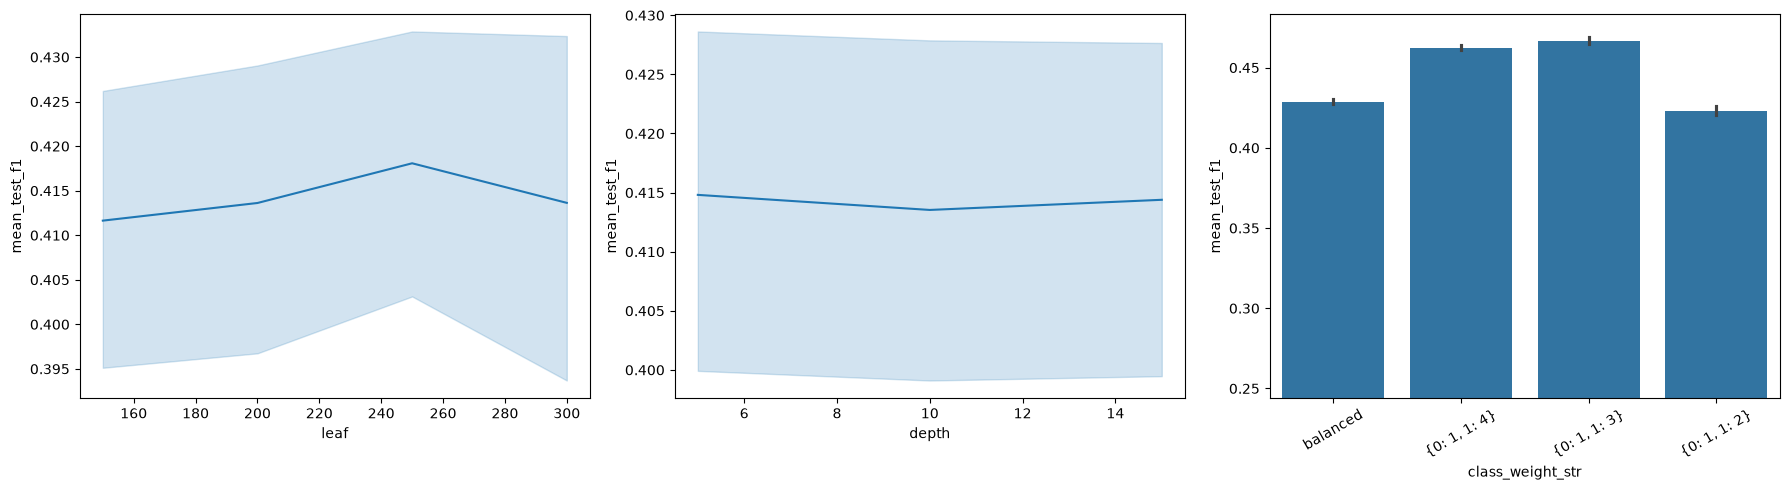

In [416]:
cw_results = pd.DataFrame(dt_cw_grid.cv_results_)

# class_weight inneholder dicter, None og tekst, så gjør den om til tekst
cw_results["class_weight_str"] = cw_results["param_estimator__class_weight"].astype(str)

# tall-kolonner kan være object-typer, så gjør dem om
cw_results["leaf"] = cw_results["param_estimator__min_samples_leaf"].astype(int)
cw_results["depth"] = cw_results["param_estimator__max_depth"].astype(int)

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

sbn.lineplot(data=cw_results, x="leaf", y="mean_test_f1", ax=axs[0])
sbn.lineplot(data=cw_results, x="depth", y="mean_test_f1", ax=axs[1])
sbn.barplot(data=cw_results, x="class_weight_str", y="mean_test_f1", ax=axs[2])

axs[2].tick_params(axis="x", rotation=30)
axs[2].set_ylim(cw_results["mean_test_f1"].min() - 0.01, cw_results["mean_test_f1"].max() + 0.01)
plt.tight_layout()

### Lineplot av class_weight-tuningen

- `class_weight`: `{0:1, 1:3}` og `{0:1, 1:4}` gir høyest F1. `balanced` og `{0:1, 1:2}` er lavere.
- `min_samples_leaf`: liten topp ved 250.
- `max_depth`: nesten flat.

Derfor tilpasser jeg rutenettet: tettere `class_weight` rundt 3–4, smalt `min_samples_leaf` rundt 250 og et større intervall for `max_depth`.

In [417]:
dt_cw_params2 = {
    "estimator": [DecisionTreeClassifier(random_state=42)],
    "estimator__class_weight": [{0: 1, 1: 2.5}, {0: 1, 1: 3}, {0: 1, 1: 3.5}, {0: 1, 1: 4}, {0: 1, 1: 5}],
    "estimator__min_samples_leaf": [200, 250, 300],
    "estimator__max_depth": [3, 5, 10, 20, None],
    "estimator__criterion": ["gini", "entropy"],
    "transformer__cat": [
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        TargetEncoder(),
    ],
}

dt_cw_grid2 = GridSearchCV(
    dt_pipe_simple, dt_cw_params2,
    scoring=scoring, refit="f1", cv=inner_cv, n_jobs=-2, verbose=1,
)
dt_cw_grid2.fit(train_features, train_target, groups=train_groups)


Fitting 5 folds for each of 300 candidates, totalling 1500 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...assthrough')])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'estimator': [DecisionTreeC...ndom_state=42)], 'estimator__class_weight': [{0: 1, 1: 2.5}, {0: 1, 1: 3}, ...], 'estimator__criterion': ['gini', 'entropy'], 'estimator__max_depth': [3, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for th

In [418]:
show_results(dt_cw_grid2, name="Decision Tree, class_weight fin")

Decision Tree, class_weight fin: beste F1 = 0.4734


,beste verdi
estimator,DecisionTreeClassifier(random_state=42)
estimator__class_weight,"{0: 1, 1: 2.5}"
estimator__criterion,entropy
estimator__max_depth,5
estimator__min_samples_leaf,300
transformer__cat,"OneHotEncoder(handle_unknown='ignore', sparse_..."


,mean_test_f1,std_test_f1,mean_fit_time,param_estimator,param_estimator__class_weight,param_estimator__criterion,param_estimator__max_depth,param_estimator__min_samples_leaf,param_transformer__cat
46,0.473448,0.010987,0.129167,DecisionTreeClassifier(random_state=42),"{0: 1, 1: 2.5}",entropy,10,300,"OneHotEncoder(handle_unknown='ignore', sparse_..."
47,0.473448,0.010987,0.104942,DecisionTreeClassifier(random_state=42),"{0: 1, 1: 2.5}",entropy,10,300,TargetEncoder()
41,0.473448,0.010987,0.098796,DecisionTreeClassifier(random_state=42),"{0: 1, 1: 2.5}",entropy,5,300,TargetEncoder()
53,0.473448,0.010987,0.098139,DecisionTreeClassifier(random_state=42),"{0: 1, 1: 2.5}",entropy,20,300,TargetEncoder()
52,0.473448,0.010987,0.113103,DecisionTreeClassifier(random_state=42),"{0: 1, 1: 2.5}",entropy,20,300,"OneHotEncoder(handle_unknown='ignore', sparse_..."


In [419]:
show_metrics(dt_cw_grid2, name="Decision Tree, class_weight fin")

Decision Tree, class_weight fin


,snitt,std
accuracy,0.831,0.008
precision,0.416,0.015
recall,0.551,0.030
f1,0.473,0.011


### Fin tuning av class_weight

Den finere kjøringen ga samme resultat som forrige: F1 = 0,473 (std 0,011), precision 0,416, recall 0,551 og accuracy 0,831. Beste parametere ble `class_weight={0:1, 1:2.5}`, `entropy`, `max_depth=5` og `min_samples_leaf=300`.

In [421]:
cw_results2 = pd.DataFrame(dt_cw_grid2.cv_results_)
best_f1 = cw_results2["mean_test_f1"].max()
ties = cw_results2[cw_results2["mean_test_f1"] == best_f1]
print(len(ties))

54


De fem beste kombinasjonene har helt lik F1, og 54 av 300 kombinasjoner deler toppscoren. Toppen er altså flat: mange ulike innstillinger gir samme score, sannsynligvis fordi de gir samme tre. «Beste» parametere er derfor bare den første blant uavgjorte. Treet ser ut til å være robust, og F1 ≈ 0,473 ser ut til å være taket for denne modellen.

In [423]:
train_seasons = barcelona_shots.loc[~is_test, "season"]
blocks = np.array_split(sorted(train_seasons.unique()), 3)

outer_scores = []

# YTRE LØKKE: hver blokk er test én gang
for test_block in blocks:
    outer_test = train_seasons.isin(test_block)

    X_tr, y_tr, g_tr = train_features[~outer_test], train_target[~outer_test], train_groups[~outer_test]
    X_te, y_te = train_features[outer_test], train_target[outer_test]

    # INDRE LØKKE: GridSearchCV tuner på ytre trening
    grid = GridSearchCV(clone(dt_pipe_simple), dt_cw_params2,
                        scoring=scoring, refit="f1", cv=inner_cv, n_jobs=-2)
    grid.fit(X_tr, y_tr, groups=g_tr)

    pred = grid.best_estimator_.predict(X_te)
    outer_scores.append({
        "test_blokk": test_block[0] + " ... " + test_block[-1],
        "antall_skudd": len(y_te),
        "accuracy": accuracy_score(y_te, pred),
        "precision": precision_score(y_te, pred),
        "recall": recall_score(y_te, pred),
        "f1": f1_score(y_te, pred),
        "indre_cv_f1": grid.best_score_,
    })

nested_results_cw = pd.DataFrame(outer_scores)
display(nested_results_cw.round(3))
print("Snitt ytre F1:", nested_results_cw["f1"].mean().round(3))

,test_blokk,antall_skudd,accuracy,precision,recall,f1,indre_cv_f1
0,1973/1974 ... 2007/2008,2000,0.840,0.386,0.571,0.461,0.477
1,2008/2009 ... 2012/2013,3941,0.817,0.425,0.573,0.488,0.466
2,2013/2014 ... 2017/2018,4566,0.822,0.384,0.532,0.446,0.459


Snitt ytre F1: 0.465


### Nested CV: balanced mot svakere class_weight

| | `class_weight="balanced"` | Tunet `class_weight` |
| --- | --- | --- |
| Ytre F1 per blokk | 0,415 / 0,443 / 0,399 | 0,461 / 0,488 / 0,446 |
| **Snitt ytre F1** | 0,419 | **0,465** |
| Snitt indre CV-F1 | ca. 0,448 | ca. 0,467 |
| Gap indre og ytre | ca. 0,03 | under 0,01 |
| Snitt precision | ca. 0,30 | ca. 0,40 |
| Snitt recall | ca. 0,71 | ca. 0,56 |

Ytre F1 økte med ca. 0,046, og forbedringen kom i alle tre blokkene. Den viktigste endringen mellom kjøringene var at vektingen ble tunet i stedet for å ligge fast på `balanced`. Stolpediagrammet fra tuningen viste samme bilde: `{0:1, 1:3}` og `{0:1, 1:4}` ga klart høyere F1 enn `balanced` og `{0:1, 1:2}`.

Med `balanced` ble mange skudd tippet som mål (høy recall, lav precision). En svakere vekting ga en bedre balanse mellom precision og recall, og dermed høyere F1. Gapet mellom indre og ytre F1 ble også mindre, så forbedringen er ikke bare optimisme fra tuningen.

**Hva betyr dette for skuddene våre?**

F1 = 0,465 er ikke sannsynligheten for at et skudd er et mål. Det er balansen mellom to ting:

- **Precision (ca. 0,40):** når modellen tipper mål, er det riktig i ca. 4 av 10 tilfeller.
- **Recall (ca. 0,56):** modellen finner ca. 56 % av alle faktiske mål.

Til sammenligning er bare 13,7 % av skuddene mål, så en precision på ca. 40 % er klart bedre enn å tippe tilfeldig. Likevel tar modellen ofte feil, noe som passer med at skuddutfall er vanskelig å forutsi (målvakt, tilfeldigheter og ting dataene ikke fanger).

In [424]:
compare_train_cv_test(dt_cw_grid2, train_features, train_target,
                      test_features, test_target, name="Decision Tree, simple, class_weight")

Decision Tree, simple, class_weight


,train,CV,test
accuracy,0.836,0.831,0.838
precision,0.427,0.416,0.391
recall,0.544,0.551,0.444
f1,0.479,0.473,0.416


### Test: Decision Tree (simple, tunet class_weight)

Train og CV er nesten like (F1 0,479 og 0,473), så treet overtilpasser ikke der siden forskjellen er så pass lav. På test (de 3 siste sesongene) faller F1 til 0,416, mest på grunn av lavere recall (0,444). Det er lavere enn nested CV ga (ca. 0,465), som kan tyde på at skuddene i de nyeste sesongene er litt annerledes enn i treningsperioden. MEN Det har vi ikke testet så egentlig bare en antagelse for nå.


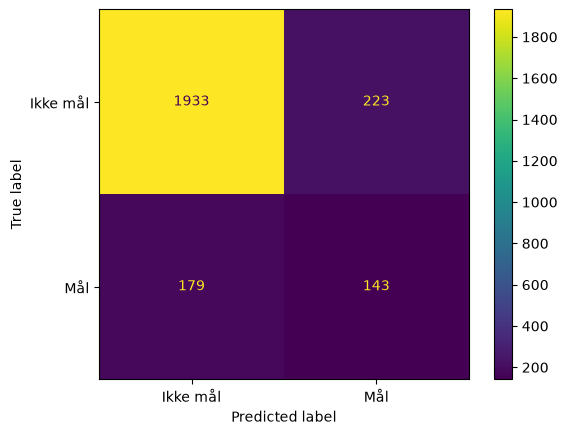

In [436]:
cm_dt = ConfusionMatrixDisplay.from_estimator(
    dt_cw_grid2.best_estimator_, test_features, test_target,
    display_labels=["Ikke mål", "Mål"], cmap="viridis",
)

### Confusion matrix: Decision Tree (test)

Av de 322 faktiske målene i test-sesongene fant modellen 143 (recall 0,444) og gikk glipp av 179. Av 366 skudd modellen tippet som mål, var 143 faktisk mål (precision 0,391) og 223 falske alarmer. Modellen klassifiserte 1933 av 2156 ikke-mål riktig.

Det betyr at treet finner under halvparten av målene, og at flere enn halvparten av «mål-tippene» er feil. Det passer med at skuddutfall er vanskelig å forutsi, håper på at vi kan få bedre resultater på de neste modellene ....